<a href="https://colab.research.google.com/github/kanokwantho/Project_Tonper/blob/main/All_2567.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [10]:
import os
import glob
import pandas as pd
from IPython.display import display

FOLDER = "/content/drive/MyDrive/โรงพยาบาล"

if not os.path.isdir(FOLDER):
    raise FileNotFoundError(
        f"ไม่พบโฟลเดอร์: {FOLDER}\n"
        "กรุณาตรวจสอบบัญชี Google และตำแหน่งโฟลเดอร์"
    )

In [11]:
all_csv_files = glob.glob(
    os.path.join(FOLDER, "*.csv")
)

quarter_files = {}

for q in range(1, 5):
    matched = [
        f for f in all_csv_files
        if f"service_ip_67q{q}" in os.path.basename(f).lower()
    ]

    if matched:
        quarter_files[q] = sorted(matched)[0]

print("ผลการค้นหาไฟล์")
for q in range(1, 5):
    if q in quarter_files:
        print(f"ไตรมาส {q}: {os.path.basename(quarter_files[q])}")
    else:
        print(f"ไตรมาส {q}: ไม่พบไฟล์")


ผลการค้นหาไฟล์
ไตรมาส 1: opendata_02_service_ip_67q1 (1).csv
ไตรมาส 2: opendata_02_service_ip_67q2.csv
ไตรมาส 3: opendata_02_service_ip_67q3.csv
ไตรมาส 4: opendata_02_service_ip_67q4.csv


In [12]:
quarter_data = {}

for q, filepath in quarter_files.items():
    print(f"\nกำลังอ่านไตรมาส {q}...")

    # พยายามอ่านด้วย encoding ภาษาไทย (tis-620 / cp874) หรือ utf-8
    for encoding in ['tis-620', 'cp874', 'utf-8']:
        try:
            df = pd.read_csv(filepath, encoding=encoding, low_memory=False)
            print(f"อ่านไฟล์สำเร็จด้วย encoding: {encoding}")
            break
        except UnicodeDecodeError:
            continue
    else:
        # หากลองทุกตัวแล้วไม่ได้ ให้ใช้แบบข้ามตัวอักษรที่มีปัญหา
        df = pd.read_csv(filepath, encoding='utf-8', errors='replace', low_memory=False)
        print("อ่านไฟล์ด้วย utf-8 (ข้ามตัวอักษรที่แปลงไม่ได้)")

    quarter_data[q] = df

    print(f"จำนวนแถว: {len(df):,}")
    print(f"จำนวนคอลัมน์: {len(df.columns)}")


กำลังอ่านไตรมาส 1...
อ่านไฟล์สำเร็จด้วย encoding: utf-8
จำนวนแถว: 501,528
จำนวนคอลัมน์: 12

กำลังอ่านไตรมาส 2...
อ่านไฟล์สำเร็จด้วย encoding: tis-620
จำนวนแถว: 508,045
จำนวนคอลัมน์: 12

กำลังอ่านไตรมาส 3...
อ่านไฟล์สำเร็จด้วย encoding: tis-620
จำนวนแถว: 510,348
จำนวนคอลัมน์: 12

กำลังอ่านไตรมาส 4...
อ่านไฟล์สำเร็จด้วย encoding: tis-620
จำนวนแถว: 530,836
จำนวนคอลัมน์: 12


In [13]:
if quarter_data:
    all_data = pd.concat(
        quarter_data.values(),
        ignore_index=True
    )

    print("\n========== สรุปข้อมูล ==========")
    print(f"จำนวนไตรมาสที่พบ: {len(quarter_data)}")
    print(f"จำนวนแถวรวม: {len(all_data):,}")
    print(f"จำนวนคอลัมน์: {len(all_data.columns)}")

    print("\nรายชื่อคอลัมน์")
    print(all_data.columns.tolist())

    print("\nตัวอย่างข้อมูล")
    display(all_data.head())

else:
    print("ไม่พบไฟล์ที่ต้องการ กรุณาตรวจสอบตำแหน่งโฟลเดอร์")


========== สรุปข้อมูล ==========
จำนวนไตรมาสที่พบ: 4
จำนวนแถวรวม: 2,050,757
จำนวนคอลัมน์: 12

รายชื่อคอลัมน์
['month_no', 'hcode', 'hname', 'province_id', 'prov', 'nhso_zonename', 'gender', 'service_type', 'pdx', 'pdx_name', 'n_pop', 'n_service']

ตัวอย่างข้อมูล


,month_no,hcode,hname,province_id,prov,nhso_zonename,gender,service_type,pdx,pdx_name,n_pop,n_service
0,202310,04007,รพ.ซับใหญ่,3600,ชัยภูมิ,เขต 9 นครราชสีมา,1.0,IP,A27,Leptospirosis,1,1
1,202310,04007,รพ.ซับใหญ่,3600,ชัยภูมิ,เขต 9 นครราชสีมา,1.0,IP,A91,Dengue haemorrhagic fever,1,1
2,202310,04007,รพ.ซับใหญ่,3600,ชัยภูมิ,เขต 9 นครราชสีมา,1.0,IP,I64,Stroke not specified as haemorrhage or infarc...,3,3
3,202310,04007,รพ.ซับใหญ่,3600,ชัยภูมิ,เขต 9 นครราชสีมา,1.0,IP,J15,Bacterial pneumonia not elsewhere classified,1,1
4,202310,04007,รพ.ซับใหญ่,3600,ชัยภูมิ,เขต 9 นครราชสีมา,1.0,IP,J69,Pneumonitis due to solids and liquids,2,2


In [16]:
import pandas as pd

# เปลี่ยนจาก data เป็น quarter_data ที่มีอยู่ในระบบ
for filename, df in quarter_data.items():

    # ตรวจสอบว่ามีคอลัมน์ month_no หรือไม่
    if "month_no" not in df.columns:
        print(f"ไม่พบคอลัมน์ month_no ในไตรมาส {filename}")
        continue

    # แปลง month_no เป็นข้อความ
    df["month_no"] = df["month_no"].astype(str).str.strip()

    # แปลงเป็นวันที่ รูปแบบ YYYYMM
    df["date"] = pd.to_datetime(
        df["month_no"].str.replace(r'\.0$', '', regex=True), # รองรับกรณีมี .0 พ่วงท้าย
        format="%Y%m",
        errors="coerce"
    )

    # สร้างคอลัมน์ปีและเดือน
    df["year"] = df["date"].dt.year
    df["month"] = df["date"].dt.month

    print(f"\nไตรมาส: {filename}")
    display(df[["month_no", "date", "year", "month"]].head())

    # ตรวจสอบจำนวนวันที่แปลงไม่ได้
    print("จำนวนแถวทั้งหมด:", len(df))
    print("จำนวนวันที่แปลงไม่ได้:", df["date"].isna().sum())


ไตรมาส: 1


,month_no,date,year,month
0,202310,2023-10-01,2023,10
1,202310,2023-10-01,2023,10
2,202310,2023-10-01,2023,10
3,202310,2023-10-01,2023,10
4,202310,2023-10-01,2023,10


จำนวนแถวทั้งหมด: 501528
จำนวนวันที่แปลงไม่ได้: 0

ไตรมาส: 2


,month_no,date,year,month
0,202401,2024-01-01,2024,1
1,202401,2024-01-01,2024,1
2,202401,2024-01-01,2024,1
3,202401,2024-01-01,2024,1
4,202401,2024-01-01,2024,1


จำนวนแถวทั้งหมด: 508045
จำนวนวันที่แปลงไม่ได้: 0

ไตรมาส: 3


,month_no,date,year,month
0,202404,2024-04-01,2024,4
1,202404,2024-04-01,2024,4
2,202404,2024-04-01,2024,4
3,202404,2024-04-01,2024,4
4,202404,2024-04-01,2024,4


จำนวนแถวทั้งหมด: 510348
จำนวนวันที่แปลงไม่ได้: 0

ไตรมาส: 4


,month_no,date,year,month
0,202407,2024-07-01,2024,7
1,202407,2024-07-01,2024,7
2,202407,2024-07-01,2024,7
3,202407,2024-07-01,2024,7
4,202407,2024-07-01,2024,7


จำนวนแถวทั้งหมด: 530836
จำนวนวันที่แปลงไม่ได้: 0


##**Clean ข้อมูล**

In [17]:
text_cols = [
    'hname',
    'prov',
    'nhso_zonename',
    'service_type',
    'pdx',
    'pdx_name'
]

for col in text_cols:
    df[col] = df[col].astype('string').str.strip()
    df[col] = df[col].str.replace(r'\s+', ' ', regex=True)

In [19]:
text_cols = [
    'hname',
    'prov',
    'nhso_zonename',
    'service_type',
    'pdx',
    'pdx_name'
]

# เปลี่ยนจาก data เป็น quarter_data ที่มีอยู่ในระบบ
for filename, df in quarter_data.items():

    print(f"\nกำลังคลีนไฟล์: {filename}")

    existing_cols = [col for col in text_cols if col in df.columns]

    for col in existing_cols:
        df[col] = df[col].astype('string').str.strip()
        df[col] = df[col].str.replace(r'\s+', ' ', regex=True)

    print("คอลัมน์ที่คลีน:", existing_cols)
    print("ขนาดข้อมูล:", df.shape)

    display(df[existing_cols].head())

print("\nคลีนข้อมูลทุกไฟล์เสร็จแล้ว")



กำลังคลีนไฟล์: 1
คอลัมน์ที่คลีน: ['hname', 'prov', 'nhso_zonename', 'service_type', 'pdx', 'pdx_name']
ขนาดข้อมูล: (501528, 15)


,hname,prov,nhso_zonename,service_type,pdx,pdx_name
0,รพ.ซับใหญ่,ชัยภูมิ,เขต 9 นครราชสีมา,IP,A27,Leptospirosis
1,รพ.ซับใหญ่,ชัยภูมิ,เขต 9 นครราชสีมา,IP,A91,Dengue haemorrhagic fever
2,รพ.ซับใหญ่,ชัยภูมิ,เขต 9 นครราชสีมา,IP,I64,Stroke not specified as haemorrhage or infarction
3,รพ.ซับใหญ่,ชัยภูมิ,เขต 9 นครราชสีมา,IP,J15,Bacterial pneumonia not elsewhere classified
4,รพ.ซับใหญ่,ชัยภูมิ,เขต 9 นครราชสีมา,IP,J69,Pneumonitis due to solids and liquids



กำลังคลีนไฟล์: 2
คอลัมน์ที่คลีน: ['hname', 'prov', 'nhso_zonename', 'service_type', 'pdx', 'pdx_name']
ขนาดข้อมูล: (508045, 15)


,hname,prov,nhso_zonename,service_type,pdx,pdx_name
0,รพ.ซับใหญ่,ชัยภูมิ,เขต 9 นครราชสีมา,IP,A09,Diarrhoea and gastroenteritis of presumed infe...
1,รพ.ซับใหญ่,ชัยภูมิ,เขต 9 นครราชสีมา,IP,J18,Pneumonia organism unspecified
2,รพ.ซับใหญ่,ชัยภูมิ,เขต 9 นครราชสีมา,IP,J11,Influenza virus not identified
3,รพ.ซับใหญ่,ชัยภูมิ,เขต 9 นครราชสีมา,IP,D37,Neoplasm of uncertain or unknown behaviour of ...
4,รพ.ซับใหญ่,ชัยภูมิ,เขต 9 นครราชสีมา,IP,S42,Fracture of shoulder and upper arm



กำลังคลีนไฟล์: 3
คอลัมน์ที่คลีน: ['hname', 'prov', 'nhso_zonename', 'service_type', 'pdx', 'pdx_name']
ขนาดข้อมูล: (510348, 15)


,hname,prov,nhso_zonename,service_type,pdx,pdx_name
0,รพ.ซับใหญ่,ชัยภูมิ,เขต 9 นครราชสีมา,IP,N10,Acute tubulo-interstitial nephritis
1,รพ.ซับใหญ่,ชัยภูมิ,เขต 9 นครราชสีมา,IP,A09,Diarrhoea and gastroenteritis of presumed infe...
2,รพ.ซับใหญ่,ชัยภูมิ,เขต 9 นครราชสีมา,IP,N17,Acute renal failure
3,รพ.ซับใหญ่,ชัยภูมิ,เขต 9 นครราชสีมา,IP,N39,Other disorders of urinary system
4,รพ.ซับใหญ่,ชัยภูมิ,เขต 9 นครราชสีมา,IP,J18,Pneumonia organism unspecified



กำลังคลีนไฟล์: 4
คอลัมน์ที่คลีน: ['hname', 'prov', 'nhso_zonename', 'service_type', 'pdx', 'pdx_name']
ขนาดข้อมูล: (530836, 15)


,hname,prov,nhso_zonename,service_type,pdx,pdx_name
0,รพ.ซับใหญ่,ชัยภูมิ,เขต 9 นครราชสีมา,IP,K56,Paralytic ileus and intestinal obstruction wit...
1,รพ.ซับใหญ่,ชัยภูมิ,เขต 9 นครราชสีมา,IP,R56,Convulsions not elsewhere classified
2,รพ.ซับใหญ่,ชัยภูมิ,เขต 9 นครราชสีมา,IP,K30,Dyspepsia
3,รพ.ซับใหญ่,ชัยภูมิ,เขต 9 นครราชสีมา,IP,S30,Superficial injury of abdomen lower back and p...
4,รพ.ซับใหญ่,ชัยภูมิ,เขต 9 นครราชสีมา,IP,S00,Superficial injury of head



คลีนข้อมูลทุกไฟล์เสร็จแล้ว


In [21]:
# ตรวจ Missing Value ของทุกไฟล์
for filename, df in quarter_data.items():
    print(f"\n========== ไฟล์: {filename} ==========")
    print("ขนาดข้อมูล:", df.shape)
    print(df.isna().sum())


========== ไฟล์: 1 ==========
ขนาดข้อมูล: (501528, 15)
month_no            0
hcode               0
hname               0
province_id         0
prov                0
nhso_zonename       0
gender            515
service_type        0
pdx                 0
pdx_name         1610
n_pop               0
n_service           0
date                0
year                0
month               0
dtype: int64

========== ไฟล์: 2 ==========
ขนาดข้อมูล: (508045, 15)
month_no            0
hcode               0
hname               0
province_id         0
prov                0
nhso_zonename       0
gender            295
service_type        0
pdx                 0
pdx_name         1485
n_pop               0
n_service           0
date                0
year                0
month               0
dtype: int64

========== ไฟล์: 3 ==========
ขนาดข้อมูล: (510348, 15)
month_no            0
hcode               0
hname               0
province_id         0
prov                0
nhso_zonename       0
gender        

##**แยกภูมิภาค**

In [23]:
# 1. Mapping จังหวัด -> ภาค
region_mapping = {
    'เหนือ': [
        'เชียงใหม่', 'เชียงราย', 'ลำปาง', 'ลำพูน', 'แม่ฮ่องสอน',
        'น่าน', 'พะเยา', 'แพร่', 'อุตรดิตถ์'
    ],
    'ตะวันออกเฉียงเหนือ': [
        'กาฬสินธุ์', 'ขอนแก่น', 'ชัยภูมิ', 'นครพนม', 'นครราชสีมา',
        'บึงกาฬ', 'บุรีรัมย์', 'มหาสารคาม', 'มุกดาหาร', 'ยโสธร',
        'ร้อยเอ็ด', 'เลย', 'ศรีสะเกษ', 'สกลนคร', 'สุรินทร์',
        'หนองคาย', 'หนองบัวลำภู', 'อุดรธานี', 'อุบลราชธานี',
        'อำนาจเจริญ'
    ],
    'กลาง': [
        'กรุงเทพฯ', 'กำแพงเพชร', 'ชัยนาท', 'นครนายก', 'นครปฐม',
        'นครสวรรค์', 'นนทบุรี', 'ปทุมธานี', 'พระนครศรีอยุธยา',
        'พิจิตร', 'พิษณุโลก', 'เพชรบูรณ์', 'ลพบุรี', 'สมุทรปราการ',
        'สมุทรสงคราม', 'สมุทรสาคร', 'สระบุรี', 'สิงห์บุรี',
        'สุโขทัย', 'สุพรรณบุรี', 'อ่างทอง', 'อุทัยธานี'
    ],
    'ตะวันตก': [
        'กาญจนบุรี', 'ตาก', 'ประจวบคีรีขันธ์', 'เพชรบุรี', 'ราชบุรี'
    ],
    'ตะวันออก': [
        'จันทบุรี', 'ฉะเชิงเทรา', 'ชลบุรี', 'ตราด',
        'ปราจีนบุรี', 'ระยอง', 'สระแก้ว'
    ],
    'ใต้': [
        'กระบี่', 'ชุมพร', 'ตรัง', 'นครศรีธรรมราช', 'นราธิวาส',
        'ปัตตานี', 'พังงา', 'พัทลุง', 'ภูเก็ต', 'ยะลา',
        'ระนอง', 'สตูล', 'สงขลา', 'สุราษฎร์ธานี'
    ]
}

# 2. สร้าง Dictionary จังหวัด -> ภาค
province_to_region = {
    province: region
    for region, provinces in region_mapping.items()
    for province in provinces
}

# 3. สร้างคอลัมน์ภาคให้ทุกไฟล์
for filename, df in quarter_data.items():

    if 'prov' not in df.columns:
        print(f"ไม่พบคอลัมน์ prov ในไฟล์ {filename}")
        continue

    # ทำความสะอาดชื่อจังหวัด
    df['prov'] = (
        df['prov']
        .astype('string')
        .str.strip()
        .str.replace(r'\s+', ' ', regex=True)
    )

    # Mapping จังหวัดเป็นภาค
    df['ภาค'] = df['prov'].map(province_to_region)

    # คงชื่อเดิมไว้หากไม่พบใน Mapping
    df['ภาค'] = df['ภาค'].fillna(df['prov'])

    print(f"\nไฟล์: {filename}")
    display(
        df[['prov', 'ภาค']]
        .drop_duplicates()
        .sort_values(['ภาค', 'prov'])
        .reset_index(drop=True)
    )

print("\nสร้างคอลัมน์ภาคครบทุกไฟล์ที่มีคอลัมน์ prov แล้ว")



ไฟล์: 1


,prov,ภาค
0,กรมแพทย์ทหารอากาศ,กรมแพทย์ทหารอากาศ
1,กรมแพทย์ทหารเรือ,กรมแพทย์ทหารเรือ
2,กรุงเทพฯ,กลาง
3,กำแพงเพชร,กลาง
4,ชัยนาท,กลาง
...,...,...
74,ยะลา,ใต้
75,ระนอง,ใต้
76,สงขลา,ใต้
77,สตูล,ใต้



ไฟล์: 2


,prov,ภาค
0,กรมแพทย์ทหารอากาศ,กรมแพทย์ทหารอากาศ
1,กรมแพทย์ทหารเรือ,กรมแพทย์ทหารเรือ
2,กรุงเทพฯ,กลาง
3,กำแพงเพชร,กลาง
4,ชัยนาท,กลาง
...,...,...
74,ยะลา,ใต้
75,ระนอง,ใต้
76,สงขลา,ใต้
77,สตูล,ใต้



ไฟล์: 3


,prov,ภาค
0,กรมแพทย์ทหารอากาศ,กรมแพทย์ทหารอากาศ
1,กรมแพทย์ทหารเรือ,กรมแพทย์ทหารเรือ
2,กรุงเทพฯ,กลาง
3,กำแพงเพชร,กลาง
4,ชัยนาท,กลาง
...,...,...
74,ยะลา,ใต้
75,ระนอง,ใต้
76,สงขลา,ใต้
77,สตูล,ใต้



ไฟล์: 4


,prov,ภาค
0,กรมแพทย์ทหารอากาศ,กรมแพทย์ทหารอากาศ
1,กรมแพทย์ทหารเรือ,กรมแพทย์ทหารเรือ
2,กรุงเทพฯ,กลาง
3,กำแพงเพชร,กลาง
4,ชัยนาท,กลาง
...,...,...
74,ยะลา,ใต้
75,ระนอง,ใต้
76,สงขลา,ใต้
77,สตูล,ใต้



สร้างคอลัมน์ภาคครบทุกไฟล์ที่มีคอลัมน์ prov แล้ว


In [24]:
# ตรวจสอบจังหวัดที่ไม่อยู่ใน Mapping ทุกไฟล์

for filename, df in quarter_data.items():

    if 'prov' not in df.columns:
        continue

    province = (
        df['prov']
        .astype('string')
        .str.strip()
        .str.replace(r'\s+', ' ', regex=True)
    )

    # จังหวัดที่ไม่อยู่ใน Dictionary ภูมิภาค
    unmatched = df[
        province.notna()
        & ~province.isin(province_to_region.keys())
    ].copy()

    print(f"\nไฟล์: {filename}")
    print("จำนวนแถวที่จับคู่ภูมิภาคไม่ได้:", len(unmatched))

    if len(unmatched) > 0:
        display(
            unmatched[
                [c for c in ['prov', 'hname', 'hcode'] if c in df.columns]
            ]
            .drop_duplicates()
            .sort_values('prov')
            .reset_index(drop=True)
        )
    else:
        print("✅ ทุกจังหวัดตรงกับ Mapping")



ไฟล์: 1
จำนวนแถวที่จับคู่ภูมิภาคไม่ได้: 61


,prov,hname,hcode
0,กรมแพทย์ทหารอากาศ,รพ.จันทรุเบกษา,SPC02
1,กรมแพทย์ทหารเรือ,แผนกแพทย์ รร.ชุมพลฯ,SNC02
2,กรมแพทย์ทหารเรือ,กองพันพยาบาลกรมสนับสนุนหน่วยบัญชาการต่อสู้อากา...,SNC05
3,กรมแพทย์ทหารเรือ,กองร้อยพยาบาลกองกำลังป้องกันชายแดนจันทบุรีและตราด,SNC06
4,กรมแพทย์ทหารเรือ,รพ.ทหารเรือกรุงเทพ,SNC09
5,กรมแพทย์ทหารเรือ,แผนกแพทย์ศูนย์ฝึกทหารใหม่ ยศ.ทร.,SNC01



ไฟล์: 2
จำนวนแถวที่จับคู่ภูมิภาคไม่ได้: 67


,prov,hname,hcode
0,กรมแพทย์ทหารอากาศ,รพ.จันทรุเบกษา,SPC02
1,กรมแพทย์ทหารเรือ,แผนกแพทย์ รร.ชุมพลฯ,SNC02
2,กรมแพทย์ทหารเรือ,กองพันพยาบาลกรมสนับสนุนหน่วยบัญชาการต่อสู้อากา...,SNC05
3,กรมแพทย์ทหารเรือ,กองร้อยพยาบาลกองกำลังป้องกันชายแดนจันทบุรีและตราด,SNC06
4,กรมแพทย์ทหารเรือ,แผนกแพทย์ศูนย์ฝึกทหารใหม่ ยศ.ทร.,SNC01
5,กรมแพทย์ทหารเรือ,รพ.ทหารเรือกรุงเทพ,SNC09



ไฟล์: 3
จำนวนแถวที่จับคู่ภูมิภาคไม่ได้: 28


,prov,hname,hcode
0,กรมแพทย์ทหารอากาศ,รพ.จันทรุเบกษา,SPC02
1,กรมแพทย์ทหารเรือ,กองพันพยาบาลกรมสนับสนุนหน่วยบัญชาการต่อสู้อากา...,SNC05
2,กรมแพทย์ทหารเรือ,รพ.ทหารเรือกรุงเทพ,SNC09
3,กรมแพทย์ทหารเรือ,แผนกแพทย์ศูนย์ฝึกทหารใหม่ ยศ.ทร.,SNC01
4,กรมแพทย์ทหารเรือ,แผนกแพทย์ รร.ชุมพลฯ,SNC02



ไฟล์: 4
จำนวนแถวที่จับคู่ภูมิภาคไม่ได้: 46


,prov,hname,hcode
0,กรมแพทย์ทหารอากาศ,รพ.จันทรุเบกษา,SPC02
1,กรมแพทย์ทหารเรือ,แผนกแพทย์ รร.ชุมพลฯ,SNC02
2,กรมแพทย์ทหารเรือ,รพ.ทหารเรือกรุงเทพ,SNC09
3,กรมแพทย์ทหารเรือ,แผนกแพทย์ศูนย์ฝึกทหารใหม่ ยศ.ทร.,SNC01


In [25]:
import pandas as pd

# เก็บข้อมูลที่คลีนแล้วแยกตามไฟล์
cleaned_data = {}

for filename, df in quarter_data.items():

    print(f"\n{'=' * 50}")
    print(f"กำลังทำความสะอาด: {filename}")

    # 1. ทำสำเนาข้อมูล
    clean = df.copy()

    # 2. ลบช่องว่างในคอลัมน์ข้อความ
    text_cols = ["prov", "ภาค", "nhso_zonename", "pdx_name"]

    for col in text_cols:
        if col in clean.columns:
            clean[col] = (
                clean[col]
                .astype("string")
                .str.strip()
                .str.replace(r"\s+", " ", regex=True)
            )

    # 3. แปลงจำนวนบริการเป็นตัวเลข
    if "n_service" in clean.columns:
        clean["n_service"] = pd.to_numeric(
            clean["n_service"], errors="coerce"
        )
    else:
        print("⚠️ ไม่พบคอลัมน์ n_service")
        continue

    # 4. แปลงจำนวนประชากรเป็นตัวเลข
    if "n_pop" in clean.columns:
        clean["n_pop"] = pd.to_numeric(
            clean["n_pop"], errors="coerce"
        )

    # 5. ลบแถวที่ไม่มีค่าจำเป็น
    required_cols = [
        col for col in ["prov", "ภาค", "pdx_name", "n_service"]
        if col in clean.columns
    ]

    clean = clean.dropna(subset=required_cols)

    # 6. เก็บข้อมูลที่คลีนแล้ว
    cleaned_data[filename] = clean

    # 7. สรุปผล
    print("จำนวนข้อมูลหลังคลีน:", len(clean))
    print("จำนวนภาค:", clean["ภาค"].nunique() if "ภาค" in clean.columns else "ไม่มีคอลัมน์")
    print("จำนวนจังหวัด:", clean["prov"].nunique() if "prov" in clean.columns else "ไม่มีคอลัมน์")
    print("จำนวนโรค:", clean["pdx_name"].nunique() if "pdx_name" in clean.columns else "ไม่มีคอลัมน์")

    display(clean.head())

print("\n✅ ทำความสะอาดข้อมูลครบทุกไฟล์แล้ว")



กำลังทำความสะอาด: 1
จำนวนข้อมูลหลังคลีน: 499918
จำนวนภาค: 8
จำนวนจังหวัด: 79
จำนวนโรค: 1445


,month_no,hcode,hname,province_id,prov,nhso_zonename,gender,service_type,pdx,pdx_name,n_pop,n_service,date,year,month,ภาค
0,202310,04007,รพ.ซับใหญ่,3600,ชัยภูมิ,เขต 9 นครราชสีมา,1.0,IP,A27,Leptospirosis,1,1,2023-10-01,2023,10,ตะวันออกเฉียงเหนือ
1,202310,04007,รพ.ซับใหญ่,3600,ชัยภูมิ,เขต 9 นครราชสีมา,1.0,IP,A91,Dengue haemorrhagic fever,1,1,2023-10-01,2023,10,ตะวันออกเฉียงเหนือ
2,202310,04007,รพ.ซับใหญ่,3600,ชัยภูมิ,เขต 9 นครราชสีมา,1.0,IP,I64,Stroke not specified as haemorrhage or infarction,3,3,2023-10-01,2023,10,ตะวันออกเฉียงเหนือ
3,202310,04007,รพ.ซับใหญ่,3600,ชัยภูมิ,เขต 9 นครราชสีมา,1.0,IP,J15,Bacterial pneumonia not elsewhere classified,1,1,2023-10-01,2023,10,ตะวันออกเฉียงเหนือ
4,202310,04007,รพ.ซับใหญ่,3600,ชัยภูมิ,เขต 9 นครราชสีมา,1.0,IP,J69,Pneumonitis due to solids and liquids,2,2,2023-10-01,2023,10,ตะวันออกเฉียงเหนือ



กำลังทำความสะอาด: 2
จำนวนข้อมูลหลังคลีน: 506560
จำนวนภาค: 8
จำนวนจังหวัด: 79
จำนวนโรค: 1437


,month_no,hcode,hname,province_id,prov,nhso_zonename,gender,service_type,pdx,pdx_name,n_pop,n_service,date,year,month,ภาค
0,202401,04007,รพ.ซับใหญ่,3600,ชัยภูมิ,เขต 9 นครราชสีมา,1.0,IP,A09,Diarrhoea and gastroenteritis of presumed infe...,6,6,2024-01-01,2024,1,ตะวันออกเฉียงเหนือ
1,202401,04007,รพ.ซับใหญ่,3600,ชัยภูมิ,เขต 9 นครราชสีมา,1.0,IP,J18,Pneumonia organism unspecified,3,3,2024-01-01,2024,1,ตะวันออกเฉียงเหนือ
2,202401,04007,รพ.ซับใหญ่,3600,ชัยภูมิ,เขต 9 นครราชสีมา,2.0,IP,J11,Influenza virus not identified,1,1,2024-01-01,2024,1,ตะวันออกเฉียงเหนือ
3,202401,04007,รพ.ซับใหญ่,3600,ชัยภูมิ,เขต 9 นครราชสีมา,2.0,IP,D37,Neoplasm of uncertain or unknown behaviour of ...,1,1,2024-01-01,2024,1,ตะวันออกเฉียงเหนือ
4,202401,04007,รพ.ซับใหญ่,3600,ชัยภูมิ,เขต 9 นครราชสีมา,1.0,IP,S42,Fracture of shoulder and upper arm,1,1,2024-01-01,2024,1,ตะวันออกเฉียงเหนือ



กำลังทำความสะอาด: 3
จำนวนข้อมูลหลังคลีน: 507737
จำนวนภาค: 8
จำนวนจังหวัด: 79
จำนวนโรค: 1433


,month_no,hcode,hname,province_id,prov,nhso_zonename,gender,service_type,pdx,pdx_name,n_pop,n_service,date,year,month,ภาค
0,202404,04007,รพ.ซับใหญ่,3600,ชัยภูมิ,เขต 9 นครราชสีมา,2.0,IP,N10,Acute tubulo-interstitial nephritis,1,1,2024-04-01,2024,4,ตะวันออกเฉียงเหนือ
1,202404,04007,รพ.ซับใหญ่,3600,ชัยภูมิ,เขต 9 นครราชสีมา,1.0,IP,A09,Diarrhoea and gastroenteritis of presumed infe...,2,2,2024-04-01,2024,4,ตะวันออกเฉียงเหนือ
2,202404,04007,รพ.ซับใหญ่,3600,ชัยภูมิ,เขต 9 นครราชสีมา,2.0,IP,N17,Acute renal failure,1,1,2024-04-01,2024,4,ตะวันออกเฉียงเหนือ
3,202404,04007,รพ.ซับใหญ่,3600,ชัยภูมิ,เขต 9 นครราชสีมา,1.0,IP,N39,Other disorders of urinary system,1,1,2024-04-01,2024,4,ตะวันออกเฉียงเหนือ
4,202404,04007,รพ.ซับใหญ่,3600,ชัยภูมิ,เขต 9 นครราชสีมา,1.0,IP,J18,Pneumonia organism unspecified,1,1,2024-04-01,2024,4,ตะวันออกเฉียงเหนือ



กำลังทำความสะอาด: 4
จำนวนข้อมูลหลังคลีน: 526137
จำนวนภาค: 8
จำนวนจังหวัด: 79
จำนวนโรค: 1448


,month_no,hcode,hname,province_id,prov,nhso_zonename,gender,service_type,pdx,pdx_name,n_pop,n_service,date,year,month,ภาค
0,202407,04007,รพ.ซับใหญ่,3600,ชัยภูมิ,เขต 9 นครราชสีมา,1.0,IP,K56,Paralytic ileus and intestinal obstruction wit...,1,1,2024-07-01,2024,7,ตะวันออกเฉียงเหนือ
1,202407,04007,รพ.ซับใหญ่,3600,ชัยภูมิ,เขต 9 นครราชสีมา,1.0,IP,R56,Convulsions not elsewhere classified,3,3,2024-07-01,2024,7,ตะวันออกเฉียงเหนือ
2,202407,04007,รพ.ซับใหญ่,3600,ชัยภูมิ,เขต 9 นครราชสีมา,1.0,IP,K30,Dyspepsia,1,1,2024-07-01,2024,7,ตะวันออกเฉียงเหนือ
3,202407,04007,รพ.ซับใหญ่,3600,ชัยภูมิ,เขต 9 นครราชสีมา,1.0,IP,S30,Superficial injury of abdomen lower back and p...,1,1,2024-07-01,2024,7,ตะวันออกเฉียงเหนือ
4,202407,04007,รพ.ซับใหญ่,3600,ชัยภูมิ,เขต 9 นครราชสีมา,1.0,IP,S00,Superficial injury of head,1,1,2024-07-01,2024,7,ตะวันออกเฉียงเหนือ



✅ ทำความสะอาดข้อมูลครบทุกไฟล์แล้ว


##**จำนวนครั้งเข้ารับบริการ จำแนกตามภาค**

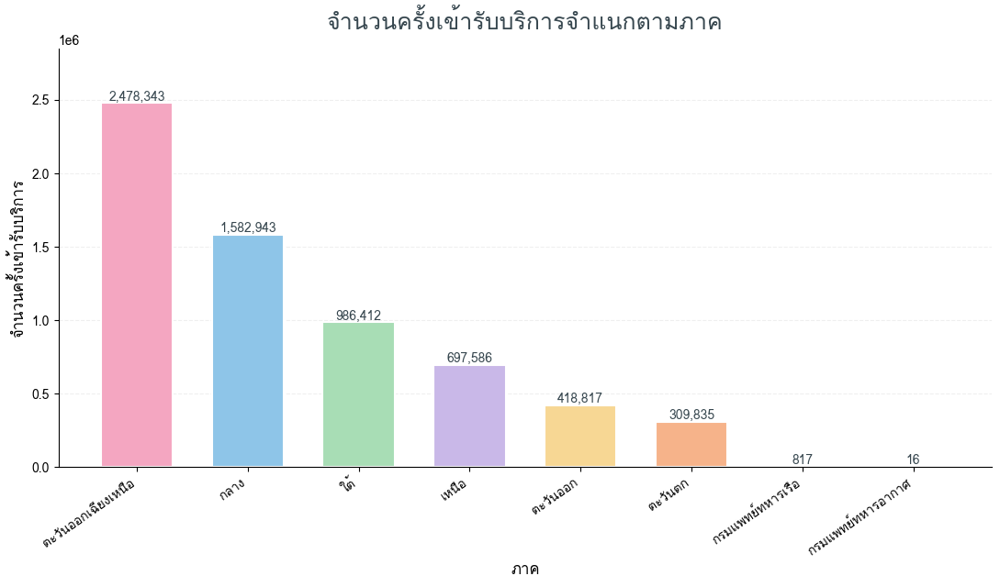

In [27]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

# 1. ติดตั้งฟอนต์ภาษาไทยหากยังไม่มี
font_path = '/usr/share/fonts/truetype/tlwg/Loma.ttf'
if not os.path.exists(font_path):
    print("กำลังติดตั้งฟอนต์ภาษาไทย...")
    os.system('apt-get -qq install -y fonts-thai-tlwg > /dev/null 2>&1')

# ตั้งค่าฟอนต์ภาษาไทย
if os.path.exists(font_path):
    mpl.font_manager.fontManager.addfont(font_path)
    mpl.rc('font', family='Loma')
else:
    print("⚠️ ไม่สามารถโหลดฟอนต์ Loma ได้ จะใช้ฟอนต์ระบบแทน")

# 2. รวมข้อมูลจาก cleaned_data ทุกไฟล์มาเป็น all_data
if 'cleaned_data' in globals() and cleaned_data:
    all_data = pd.concat(cleaned_data.values(), ignore_index=True)
else:
    # หากยังไม่ได้ทำความสะอาดข้อมูล ให้ดึงข้อมูลดิบจาก data แทน
    all_data = pd.concat(data.values(), ignore_index=True)

# 3. รวมจำนวนครั้งเข้ารับบริการตามภาคจากทุกไฟล์
region_service = (
    all_data.groupby("ภาค")["n_service"]
    .sum()
    .sort_values(ascending=False)
)

cute_colors = [
    "#F4A6C1", "#8EC5E8", "#A8DDB5",
    "#C9B8E8", "#F7D794", "#F6B38A",
    "#D8A7C7", "#A8C8E8"
]

fig, ax = plt.subplots(figsize=(11, 6.5))

bars = ax.bar(
    region_service.index,
    region_service.values,
    color=[cute_colors[i % len(cute_colors)]
           for i in range(len(region_service))],
    edgecolor="white",
    linewidth=1.5,
    width=0.65
)

ax.set_title(
    "จำนวนครั้งเข้ารับบริการจำแนกตามภาค",
    fontsize=18,
    fontweight="bold",
    color="#37474F",
    pad=15
)

ax.set_xlabel("ภาค", fontsize=12, fontweight="bold")
ax.set_ylabel("จำนวนครั้งเข้ารับบริการ", fontsize=12)

plt.xticks(rotation=35, ha="right", fontsize=10)

# แสดงตัวเลขบนแท่งกราฟ
for bar, value in zip(bars, region_service.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:,.0f}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
        color="#37474F"
    )

ax.grid(axis="y", linestyle="--", alpha=0.2)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

if not region_service.empty and region_service.max() > 0:
    ax.set_ylim(0, region_service.max() * 1.15)

plt.tight_layout()
plt.show()

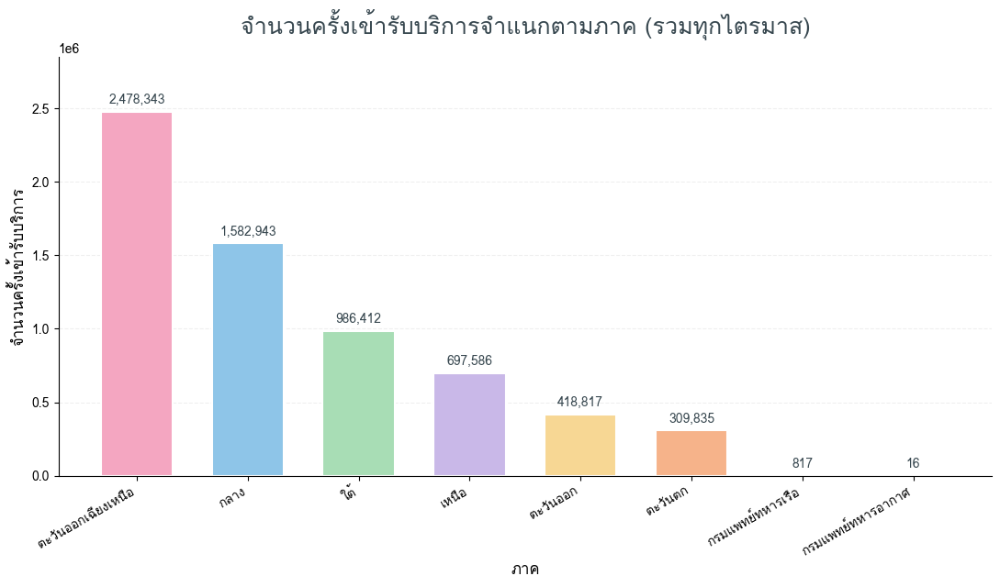

จำนวนครั้งเข้ารับบริการรวม: 6,474,769 ครั้ง


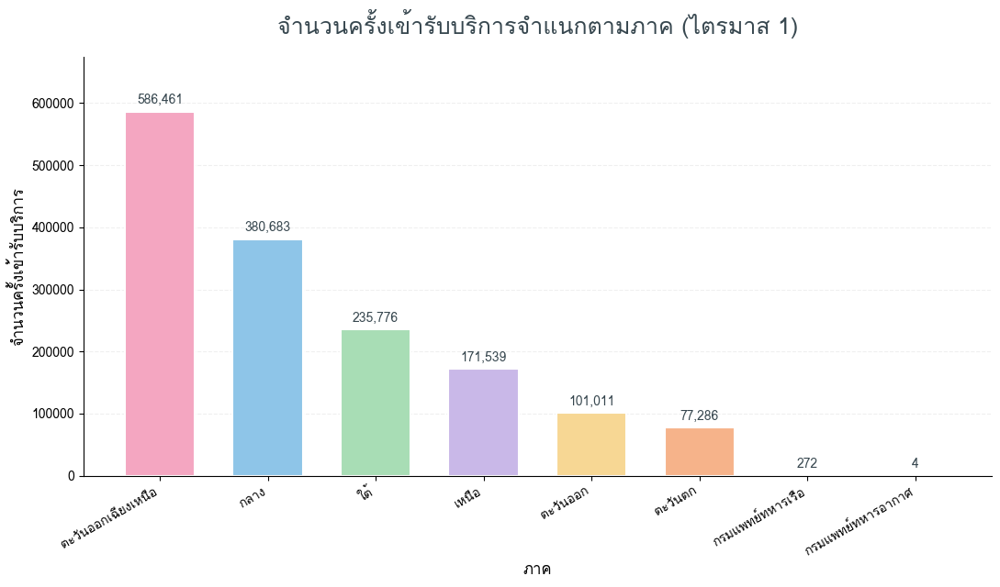

จำนวนครั้งเข้ารับบริการรวม: 1,553,032 ครั้ง


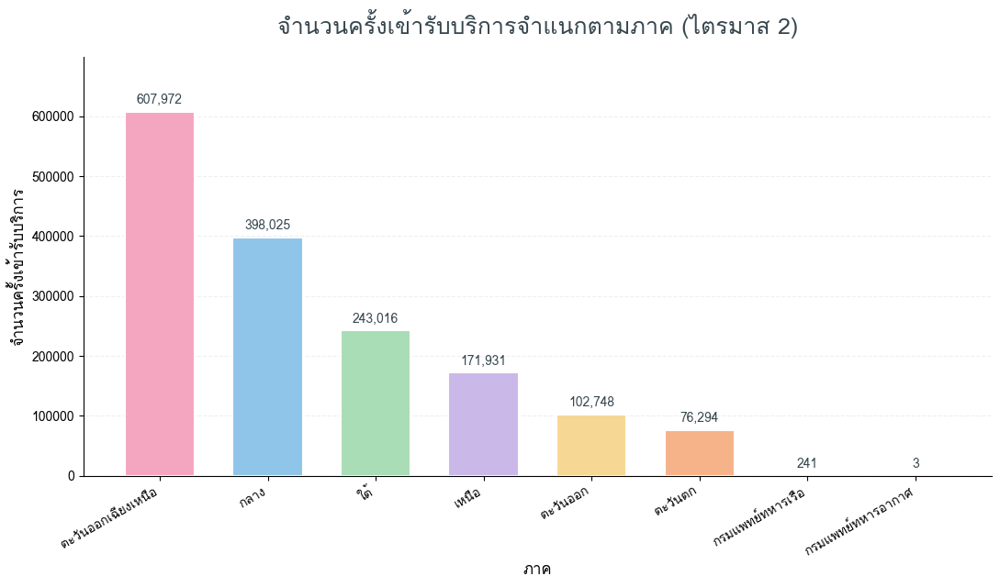

จำนวนครั้งเข้ารับบริการรวม: 1,600,230 ครั้ง


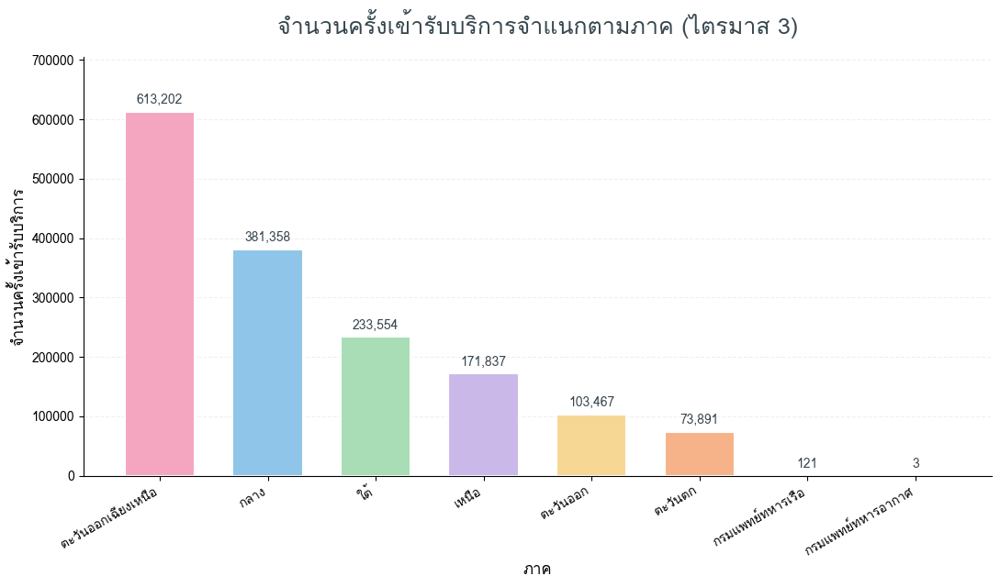

จำนวนครั้งเข้ารับบริการรวม: 1,577,433 ครั้ง


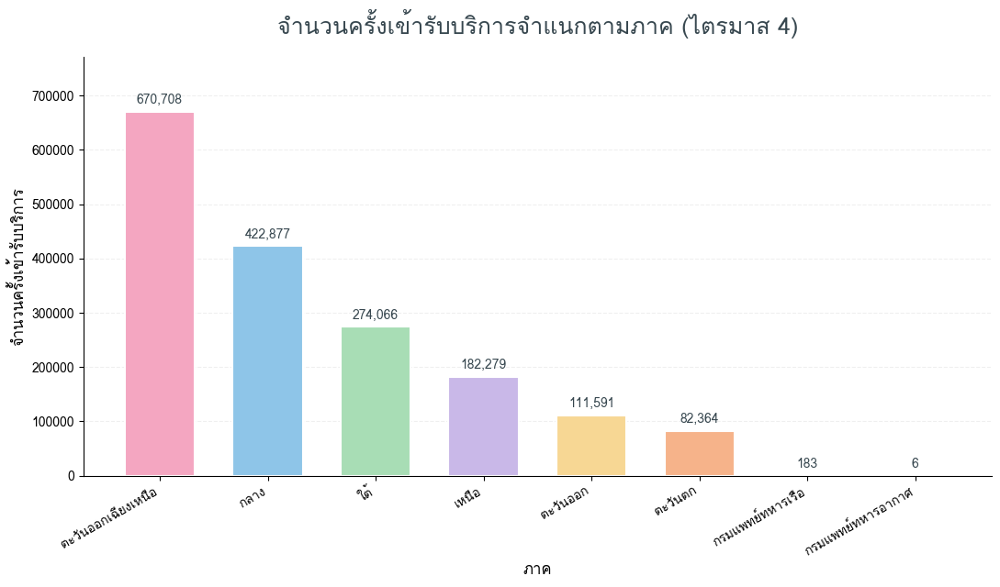

จำนวนครั้งเข้ารับบริการรวม: 1,744,074 ครั้ง


In [30]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

# ==================================================
# 1. ตั้งค่าฟอนต์ภาษาไทย
# ==================================================
font_path = '/usr/share/fonts/truetype/tlwg/Loma.ttf'

if not os.path.exists(font_path):
    os.system('apt-get -qq install -y fonts-thai-tlwg > /dev/null 2>&1')

if os.path.exists(font_path):
    mpl.font_manager.fontManager.addfont(font_path)
    mpl.rc('font', family='Loma')

mpl.rcParams['axes.unicode_minus'] = False

# ==================================================
# 2. เตรียมข้อมูลทุกไตรมาส
# ==================================================
source_data = cleaned_data if (
    'cleaned_data' in globals() and cleaned_data
) else quarter_data

quarter_plot_data = {}

for q_num, df in source_data.items():

    # ตรวจสอบคอลัมน์ที่จำเป็น
    if not {'ภาค', 'n_service'}.issubset(df.columns):
        print(f'ข้าม ไตรมาส {q_num}: ไม่มีคอลัมน์ ภาค หรือ n_service')
        continue

    temp = df.copy()

    # แปลงจำนวนบริการเป็นตัวเลข
    temp['n_service'] = pd.to_numeric(
        temp['n_service'], errors='coerce'
    )

    # ตัดแถวที่ไม่มีข้อมูลที่จำเป็น
    temp = temp.dropna(subset=['ภาค', 'n_service'])

    # ระบุไตรมาสโดยตรงจากคีย์ (1-4)
    quarter_plot_data[f'ไตรมาส {q_num}'] = temp

if not quarter_plot_data:
    raise ValueError(
        "ไม่พบข้อมูลไตรมาส 1–4 ที่ต้องการ"
    )

# รวมข้อมูลทุกไตรมาส
all_data = pd.concat(
    quarter_plot_data.values(),
    ignore_index=True
)

# ==================================================
# 3. กำหนดสีพาสเทล
# ==================================================
cute_colors = [
    "#F4A6C1", "#8EC5E8", "#A8DDB5",
    "#C9B8E8", "#F7D794", "#F6B38A",
    "#D8A7C7", "#A8C8E8"
]

# ==================================================
# 4. ฟังก์ชันสร้างกราฟ
# ==================================================
def plot_region_service(df, title):

    region_service = (
        df.groupby('ภาค')['n_service']
        .sum()
        .sort_values(ascending=False)
    )

    if region_service.empty:
        print(f'ไม่มีข้อมูลสำหรับ {title}')
        return

    fig, ax = plt.subplots(figsize=(11, 6.5))

    bars = ax.bar(
        region_service.index,
        region_service.values,
        color=[
            cute_colors[i % len(cute_colors)]
            for i in range(len(region_service))
        ],
        edgecolor='white',
        linewidth=1.5,
        width=0.65
    )

    ax.set_title(
        title,
        fontsize=18,
        fontweight='bold',
        color='#37474F',
        pad=18
    )

    ax.set_xlabel('ภาค', fontsize=12, fontweight='bold')
    ax.set_ylabel('จำนวนครั้งเข้ารับบริการ', fontsize=12)

    plt.setp(
        ax.get_xticklabels(),
        rotation=30,
        ha='right',
        fontsize=10
    )

    # แสดงค่าบนแท่งกราฟ
    for bar, value in zip(bars, region_service.values):
        ax.annotate(
            f'{value:,.0f}',
            (bar.get_x() + bar.get_width() / 2,
             bar.get_height()),
            xytext=(0, 4),
            textcoords='offset points',
            ha='center',
            va='bottom',
            fontsize=10,
            fontweight='bold',
            color='#37474F'
        )

    ax.grid(axis='y', linestyle='--', alpha=0.2)
    ax.set_axisbelow(True)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    max_value = region_service.max()
    if max_value > 0:
        ax.set_ylim(0, max_value * 1.15)

    plt.tight_layout()
    plt.show()

    print(f'จำนวนครั้งเข้ารับบริการรวม: {region_service.sum():,.0f} ครั้ง')

# ==================================================
# 5. กราฟที่ 1: รวมทุกไตรมาส
# ==================================================
plot_region_service(
    all_data,
    'จำนวนครั้งเข้ารับบริการจำแนกตามภาค (รวมทุกไตรมาส)'
)

# ==================================================
# 6. กราฟที่ 2–5: แยกแต่ละไตรมาส
# ==================================================
for quarter in sorted(quarter_plot_data.keys()):
    plot_region_service(
        quarter_plot_data[quarter],
        f'จำนวนครั้งเข้ารับบริการจำแนกตามภาค ({quarter})'
    )

##**Top 5 โรคที่มีจำนวนครั้งเข้ารับบริการสูงสุด จำแนกตามภูมิภาค**

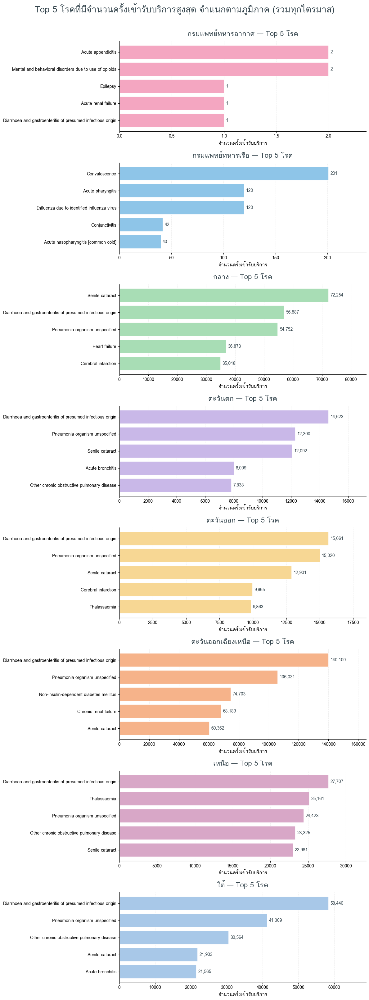

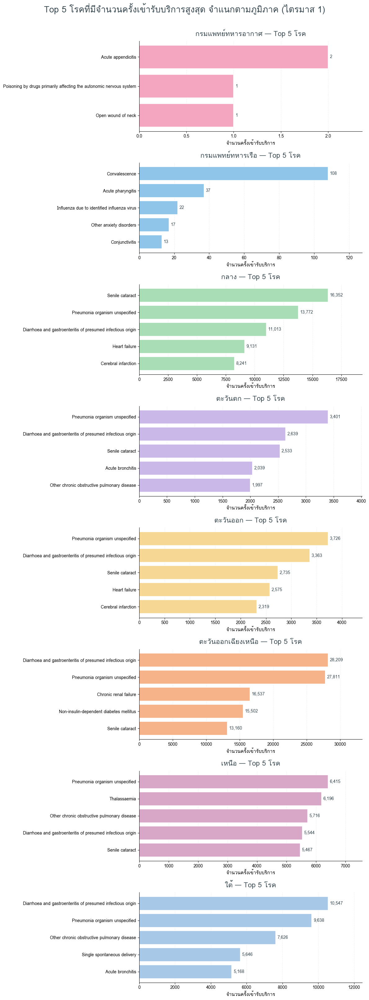

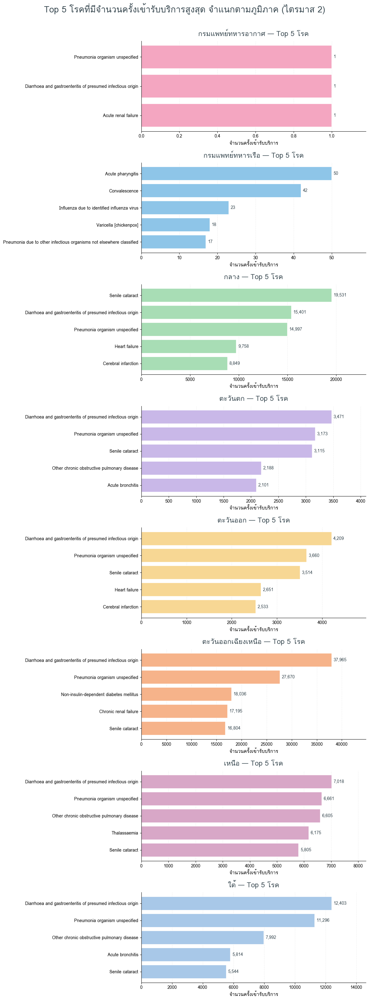

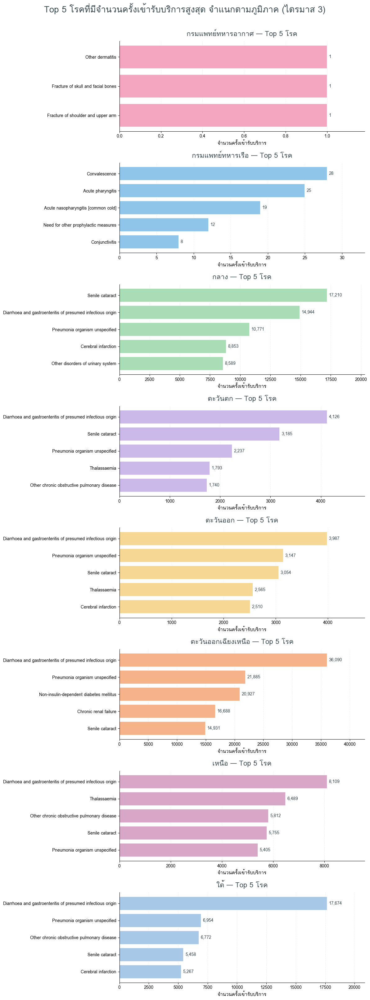

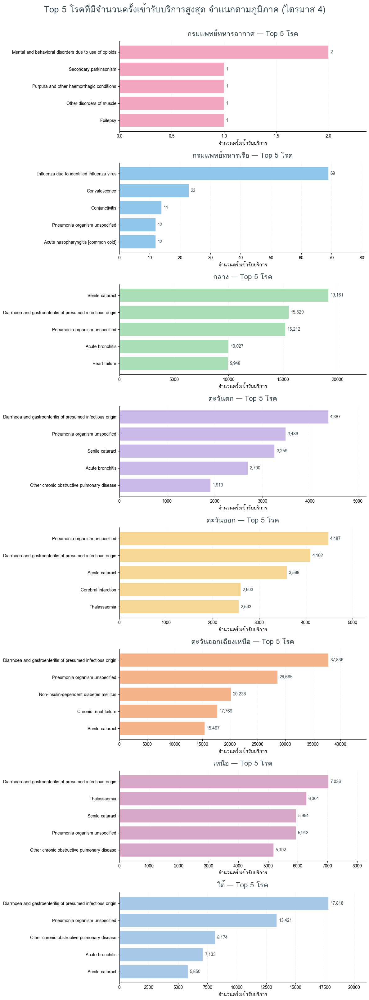

In [33]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

# ==================================================
# 1. ตั้งค่าฟอนต์ภาษาไทย
# ==================================================
font_path = '/usr/share/fonts/truetype/tlwg/Loma.ttf'

if not os.path.exists(font_path):
    os.system('apt-get -qq install -y fonts-thai-tlwg > /dev/null 2>&1')

if os.path.exists(font_path):
    mpl.font_manager.fontManager.addfont(font_path)
    mpl.rc('font', family='Loma')

mpl.rcParams['axes.unicode_minus'] = False

# ==================================================
# 2. เตรียมข้อมูลแต่ละไตรมาส
# ==================================================
source_data = cleaned_data if (
    'cleaned_data' in globals() and cleaned_data
) else data

quarter_data = {}

for key, df in source_data.items():
    # หาก key เป็นตัวเลข (1, 2, 3, 4)
    if isinstance(key, int):
        q_num = key
    else:
        # หาก key เป็นชื่อไฟล์
        name = os.path.basename(str(key)).lower()
        q_num = None
        for q in range(1, 5):
            if f'67q{q}' in name:
                q_num = q
                break
        if q_num is None:
            continue

    required = {'ภาค', 'pdx_name', 'n_service'}
    if not required.issubset(df.columns):
        print(f'ข้ามไฟล์/ไตรมาส {key}: คอลัมน์ไม่ครบ')
        continue

    temp = df.copy()
    temp['n_service'] = pd.to_numeric(
        temp['n_service'], errors='coerce'
    )
    temp = temp.dropna(
        subset=['ภาค', 'pdx_name', 'n_service']
    )

    quarter_data[f'ไตรมาส {q_num}'] = temp

if not quarter_data:
    raise ValueError('ไม่พบข้อมูลไตรมาสที่ต้องการที่มีคอลัมน์ครบ')

all_data = pd.concat(
    quarter_data.values(),
    ignore_index=True
)

# ==================================================
# 3. สีพาสเทล
# ==================================================
pastel_colors = [
    "#F4A6C1",
    "#8EC5E8",
    "#A8DDB5",
    "#C9B8E8",
    "#F7D794",
    "#F6B38A",
    "#D8A7C7",
    "#A8C8E8"
]

# ==================================================
# 4. ฟังก์ชันสร้างกราฟ Top 5 โรคแยกตามภาค
# ==================================================
def plot_top5_disease(df, title):

    region_disease = (
        df.groupby(['ภาค', 'pdx_name'], as_index=False)
        ['n_service'].sum()
    )

    regions = sorted(region_disease['ภาค'].dropna().unique())

    if len(regions) == 0:
        print(f'ไม่มีข้อมูล: {title}')
        return

    fig, axes = plt.subplots(
        nrows=len(regions),
        ncols=1,
        figsize=(12, 4 * len(regions))
    )

    if len(regions) == 1:
        axes = [axes]

    fig.suptitle(
        title,
        fontsize=20,
        fontweight='bold',
        color='#37474F',
        y=1.005
    )

    for i, (ax, region) in enumerate(zip(axes, regions)):

        # เลือก Top 5 โรคตามจำนวนบริการ
        temp = (
            region_disease[region_disease['ภาค'] == region]
            .nlargest(5, 'n_service')
            .sort_values('n_service', ascending=True)
        )

        bars = ax.barh(
            temp['pdx_name'].astype(str),
            temp['n_service'],
            color=pastel_colors[i % len(pastel_colors)],
            edgecolor='white',
            linewidth=1.2
        )

        ax.set_title(
            f'{region} — Top 5 โรค',
            fontsize=16,
            fontweight='bold',
            color='#37474F',
            pad=12
        )

        ax.set_xlabel(
            'จำนวนครั้งเข้ารับบริการ',
            fontsize=11
        )
        ax.set_ylabel('')

        # แสดงจำนวนปลายแท่ง
        ax.bar_label(
            bars,
            labels=[f'{v:,.0f}' for v in temp['n_service']],
            padding=4,
            fontsize=10,
            color='#37474F'
        )

        ax.grid(axis='x', linestyle='--', alpha=0.2)
        ax.set_axisbelow(True)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)

        max_value = temp['n_service'].max()
        if max_value > 0:
            ax.set_xlim(0, max_value * 1.18)

    plt.tight_layout()
    plt.show()

# ==================================================
# 5. กราฟที่ 1: รวมทุกไตรมาส
# ==================================================
plot_top5_disease(
    all_data,
    'Top 5 โรคที่มีจำนวนครั้งเข้ารับบริการสูงสุด จำแนกตามภูมิภาค (รวมทุกไตรมาส)'
)

# ==================================================
# 6. กราฟที่ 2–5: แยกแต่ละไตรมาส
# ==================================================
for quarter in sorted(quarter_data.keys()):
    plot_top5_disease(
        quarter_data[quarter],
        f'Top 5 โรคที่มีจำนวนครั้งเข้ารับบริการสูงสุด จำแนกตามภูมิภาค ({quarter})'
    )

##**สัดส่วนเพศของผู้เข้ารับบริการใน 5 โรคหลัก**


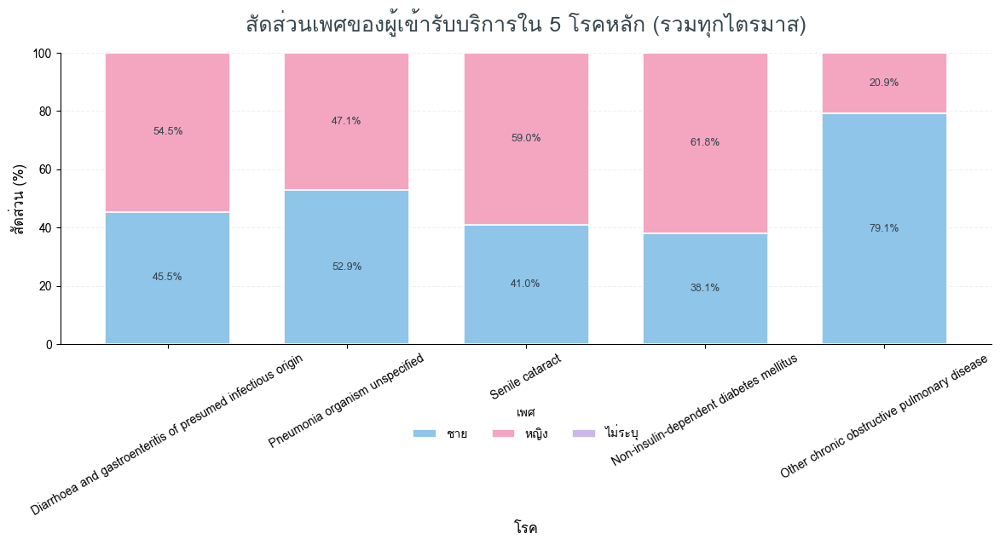


สัดส่วนเพศของผู้เข้ารับบริการใน 5 โรคหลัก (รวมทุกไตรมาส)


gender_label,ชาย,หญิง,ไม่ระบุ
pdx_name,,,
Diarrhoea and gastroenteritis of presumed infectious origin,45.47,54.52,0.01
Pneumonia organism unspecified,52.85,47.12,0.03
Senile cataract,40.98,59.02,0.00
Non-insulin-dependent diabetes mellitus,38.14,61.85,0.01
Other chronic obstructive pulmonary disease,79.11,20.85,0.04


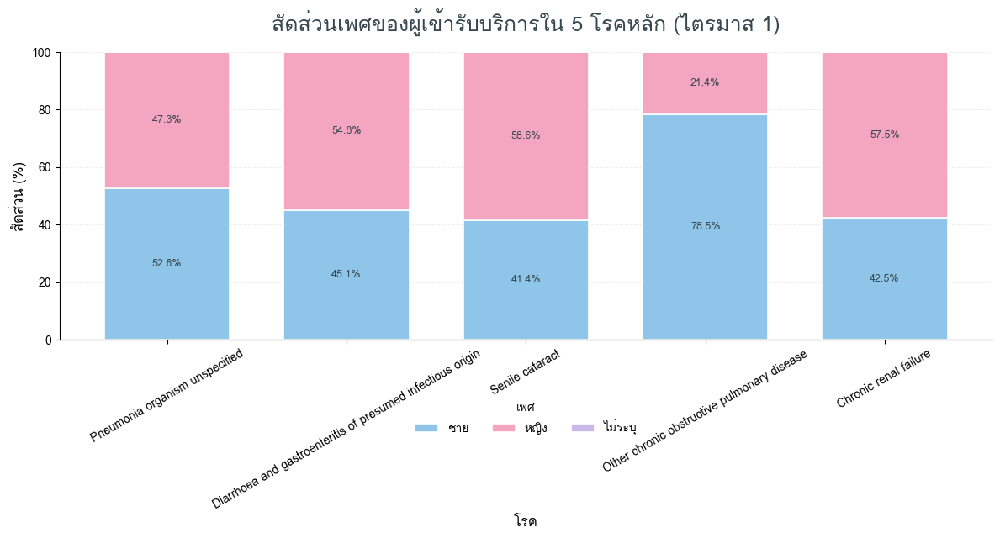


สัดส่วนเพศของผู้เข้ารับบริการใน 5 โรคหลัก (ไตรมาส 1)


gender_label,ชาย,หญิง,ไม่ระบุ
pdx_name,,,
Pneumonia organism unspecified,52.60,47.35,0.05
Diarrhoea and gastroenteritis of presumed infectious origin,45.15,54.84,0.01
Senile cataract,41.41,58.59,0.00
Other chronic obstructive pulmonary disease,78.48,21.45,0.07
Chronic renal failure,42.46,57.47,0.06


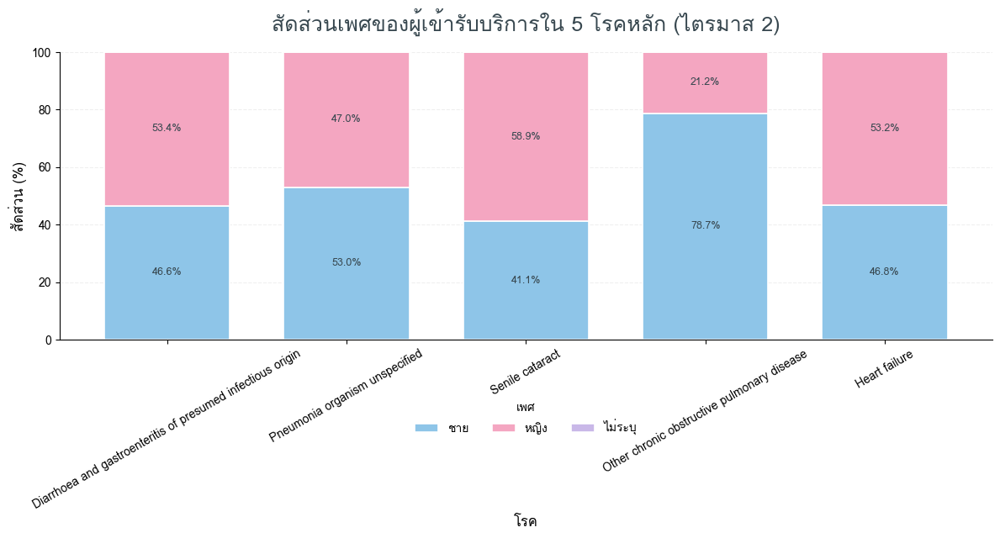


สัดส่วนเพศของผู้เข้ารับบริการใน 5 โรคหลัก (ไตรมาส 2)


gender_label,ชาย,หญิง,ไม่ระบุ
pdx_name,,,
Diarrhoea and gastroenteritis of presumed infectious origin,46.62,53.37,0.01
Pneumonia organism unspecified,53.01,46.95,0.04
Senile cataract,41.13,58.86,0.01
Other chronic obstructive pulmonary disease,78.74,21.21,0.05
Heart failure,46.80,53.18,0.03


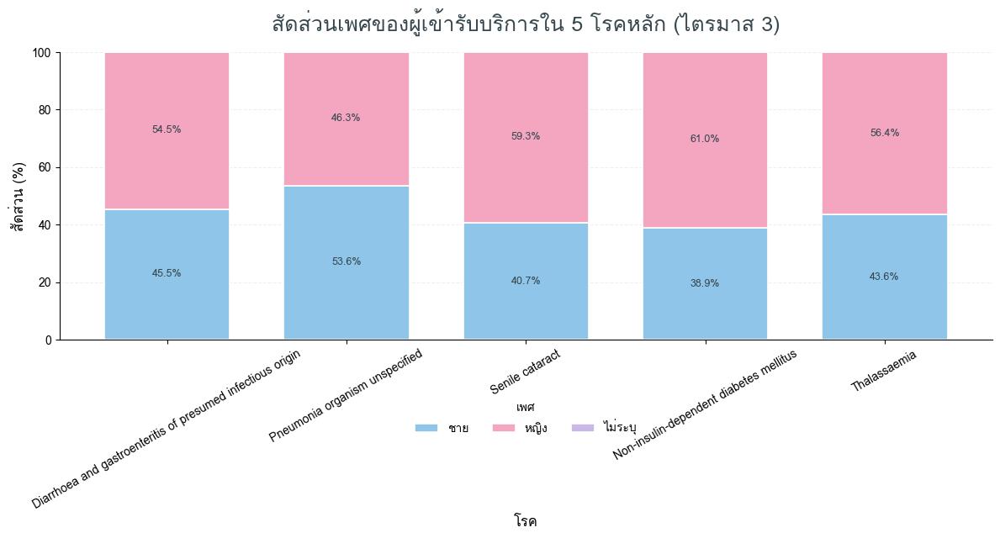


สัดส่วนเพศของผู้เข้ารับบริการใน 5 โรคหลัก (ไตรมาส 3)


gender_label,ชาย,หญิง,ไม่ระบุ
pdx_name,,,
Diarrhoea and gastroenteritis of presumed infectious origin,45.47,54.52,0.01
Pneumonia organism unspecified,53.62,46.34,0.04
Senile cataract,40.71,59.29,0.00
Non-insulin-dependent diabetes mellitus,38.94,61.05,0.01
Thalassaemia,43.56,56.44,0.00


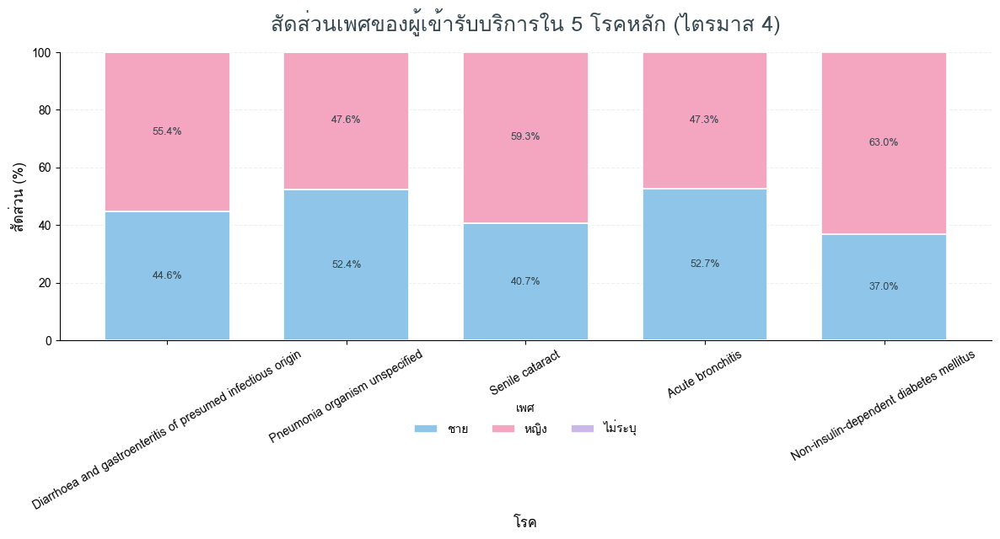


สัดส่วนเพศของผู้เข้ารับบริการใน 5 โรคหลัก (ไตรมาส 4)


gender_label,ชาย,หญิง,ไม่ระบุ
pdx_name,,,
Diarrhoea and gastroenteritis of presumed infectious origin,44.62,55.38,0.0
Pneumonia organism unspecified,52.39,47.61,0.0
Senile cataract,40.70,59.30,0.0
Acute bronchitis,52.74,47.26,0.0
Non-insulin-dependent diabetes mellitus,36.98,63.02,0.0


In [35]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

# ==================================================
# 1. ตั้งค่าฟอนต์ภาษาไทย
# ==================================================
font_path = '/usr/share/fonts/truetype/tlwg/Loma.ttf'

if not os.path.exists(font_path):
    os.system('apt-get -qq install -y fonts-thai-tlwg > /dev/null 2>&1')

if os.path.exists(font_path):
    mpl.font_manager.fontManager.addfont(font_path)
    mpl.rc('font', family='Loma')

mpl.rcParams['axes.unicode_minus'] = False

# ==================================================
# 2. เตรียมข้อมูลทุกไตรมาส
# ==================================================
source_data = cleaned_data if (
    'cleaned_data' in globals() and cleaned_data
) else data

quarter_data = {}

for key, df in source_data.items():
    # หาก key เป็นตัวเลข (1, 2, 3, 4)
    if isinstance(key, int):
        q_num = key
    else:
        # หาก key เป็นชื่อไฟล์
        name = os.path.basename(str(key)).lower()
        q_num = None
        for q in range(1, 5):
            if f'67q{q}' in name:
                q_num = q
                break
        if q_num is None:
            continue

    required = {'pdx_name', 'gender', 'n_service'}
    if not required.issubset(df.columns):
        print(f'ข้ามคีย์ {key}: คอลัมน์ไม่ครบ')
        continue

    temp = df.copy()
    temp['n_service'] = pd.to_numeric(
        temp['n_service'], errors='coerce'
    )

    temp = temp.dropna(
        subset=['pdx_name', 'n_service']
    )

    # รองรับรหัสเพศทั้งตัวเลขและข้อความ
    gender_code = pd.to_numeric(temp['gender'], errors='coerce')

    temp['gender_label'] = gender_code.map({
        1: 'ชาย',
        2: 'หญิง'
    }).fillna('ไม่ระบุ')

    quarter_data[f'ไตรมาส {q_num}'] = temp

if not quarter_data:
    raise ValueError(
        'ไม่พบข้อมูลไตรมาส 67q1–67q4 ที่มีคอลัมน์ครบ'
    )

# รวมข้อมูลทุกไตรมาส
all_data = pd.concat(
    quarter_data.values(),
    ignore_index=True
)

# ==================================================
# 3. ตั้งค่าสีและลำดับเพศ
# ==================================================
colors = {
    'ชาย': '#8EC5E8',
    'หญิง': '#F4A6C1',
    'ไม่ระบุ': '#C9B8E8'
}

gender_order = ['ชาย', 'หญิง', 'ไม่ระบุ']

# ==================================================
# 4. ฟังก์ชันสร้างกราฟสัดส่วนเพศ
# ==================================================
def plot_gender_disease(df, title):

    # หา Top 5 โรคจากจำนวนบริการรวม
    top5_disease = (
        df.groupby('pdx_name')['n_service']
        .sum()
        .nlargest(5)
        .index
    )

    # รวมจำนวนบริการตามโรคและเพศ
    gender_disease = (
        df[df['pdx_name'].isin(top5_disease)]
        .groupby(['pdx_name', 'gender_label'])['n_service']
        .sum()
        .unstack(fill_value=0)
    )

    # เรียงโรคจากจำนวนบริการสูงไปต่ำ
    disease_order = (
        df.groupby('pdx_name')['n_service']
        .sum()
        .loc[top5_disease]
        .sort_values(ascending=False)
        .index
    )

    gender_disease = gender_disease.reindex(
        index=disease_order,
        columns=gender_order,
        fill_value=0
    )

    # คำนวณเปอร์เซ็นต์
    totals = gender_disease.sum(axis=1).replace(0, float('nan'))
    gender_pct = gender_disease.div(totals, axis=0) * 100
    gender_pct = gender_pct.fillna(0)

    # วาดกราฟ
    fig, ax = plt.subplots(figsize=(12, 6.5))

    gender_pct.plot(
        kind='bar',
        stacked=True,
        ax=ax,
        color=[colors[col] for col in gender_pct.columns],
        edgecolor='white',
        linewidth=1.2,
        width=0.7
    )

    ax.set_title(
        title,
        fontsize=18,
        fontweight='bold',
        color='#37474F',
        pad=18
    )

    ax.set_xlabel('โรค', fontsize=12, fontweight='bold')
    ax.set_ylabel('สัดส่วน (%)', fontsize=12, fontweight='bold')

    ax.set_ylim(0, 100)
    ax.set_yticks(range(0, 101, 20))
    ax.tick_params(axis='x', labelrotation=30, labelsize=10)
    ax.tick_params(axis='y', labelsize=10)

    # แสดงเปอร์เซ็นต์ในแต่ละส่วนของแท่ง
    for container in ax.containers:
        labels = [
            f'{bar.get_height():.1f}%'
            if bar.get_height() >= 5 else ''
            for bar in container
        ]

        ax.bar_label(
            container,
            labels=labels,
            label_type='center',
            fontsize=9,
            color='#37474F',
            fontweight='bold'
        )

    ax.grid(axis='y', linestyle='--', alpha=0.2)
    ax.set_axisbelow(True)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    ax.legend(
        title='เพศ',
        loc='upper center',
        bbox_to_anchor=(0.5, -0.18),
        ncol=3,
        frameon=False
    )

    plt.tight_layout()
    plt.show()

    print(f'\n{title}')
    display(gender_pct.round(2))

# ==================================================
# 5. กราฟที่ 1: รวมทุกไตรมาส
# ==================================================
plot_gender_disease(
    all_data,
    'สัดส่วนเพศของผู้เข้ารับบริการใน 5 โรคหลัก (รวมทุกไตรมาส)'
)

# ==================================================
# 6. กราฟที่ 2–5: แยกแต่ละไตรมาส
# ==================================================
for quarter in sorted(quarter_data.keys()):
    plot_gender_disease(
        quarter_data[quarter],
        f'สัดส่วนเพศของผู้เข้ารับบริการใน 5 โรคหลัก ({quarter})'
    )

##**จำนวนครั้งเข้ารับบริการจำแนกตามเขตสุขภาพ**

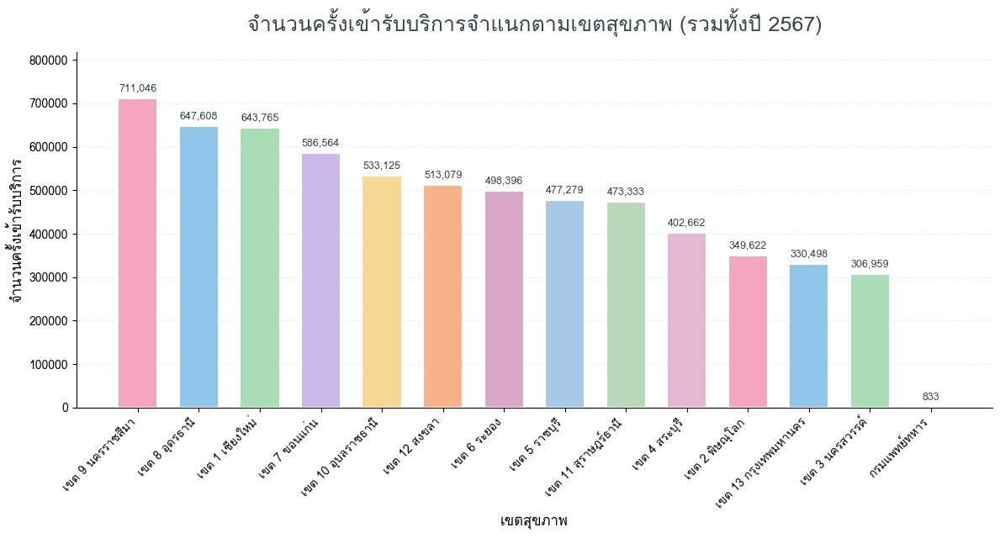

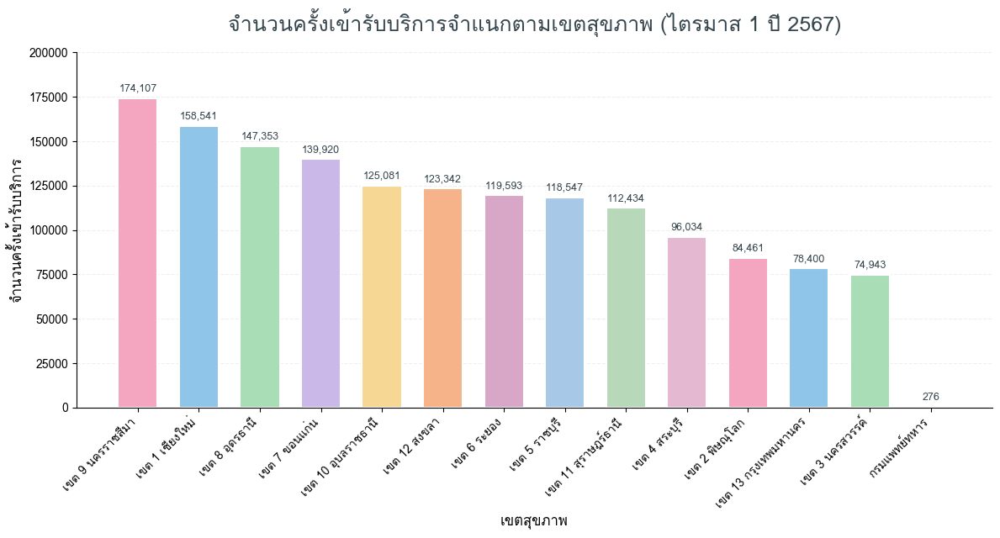

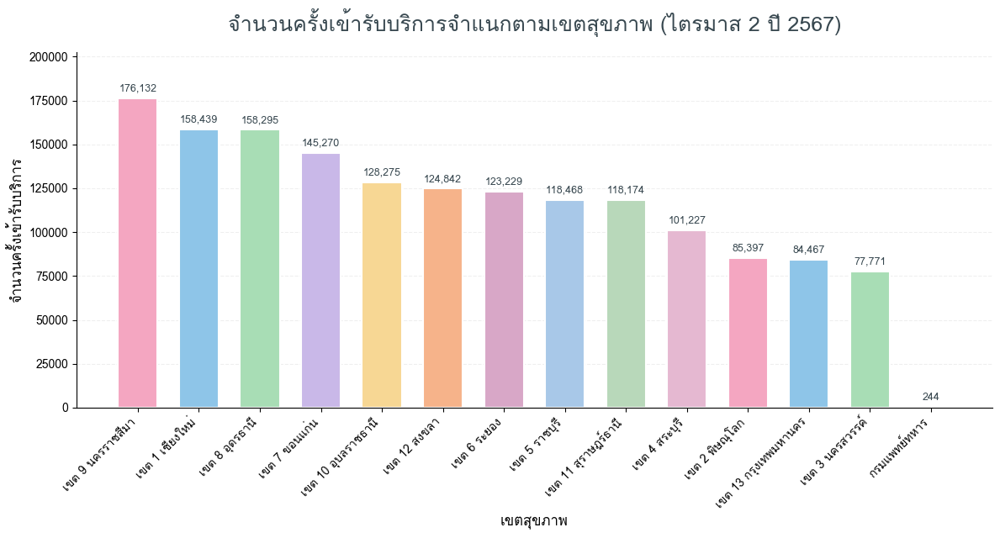

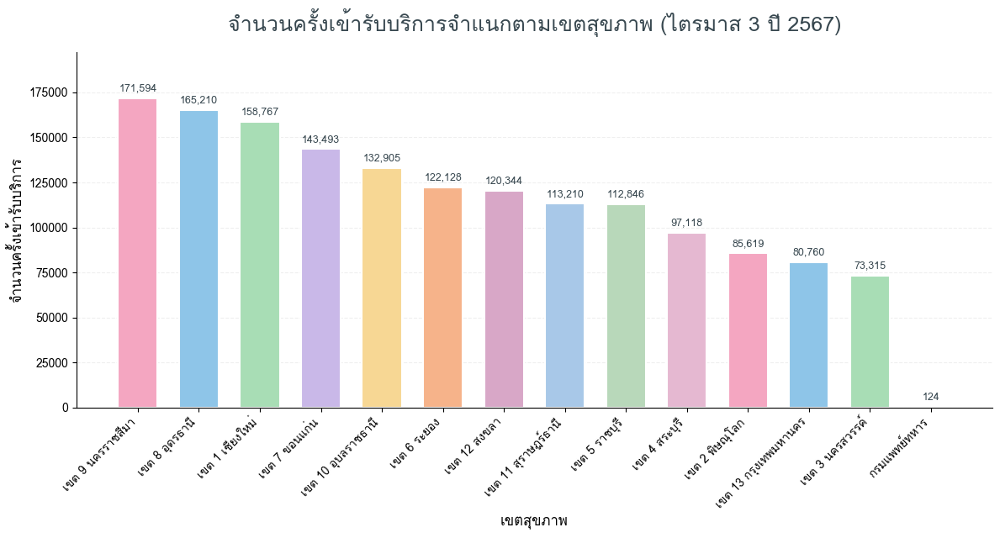

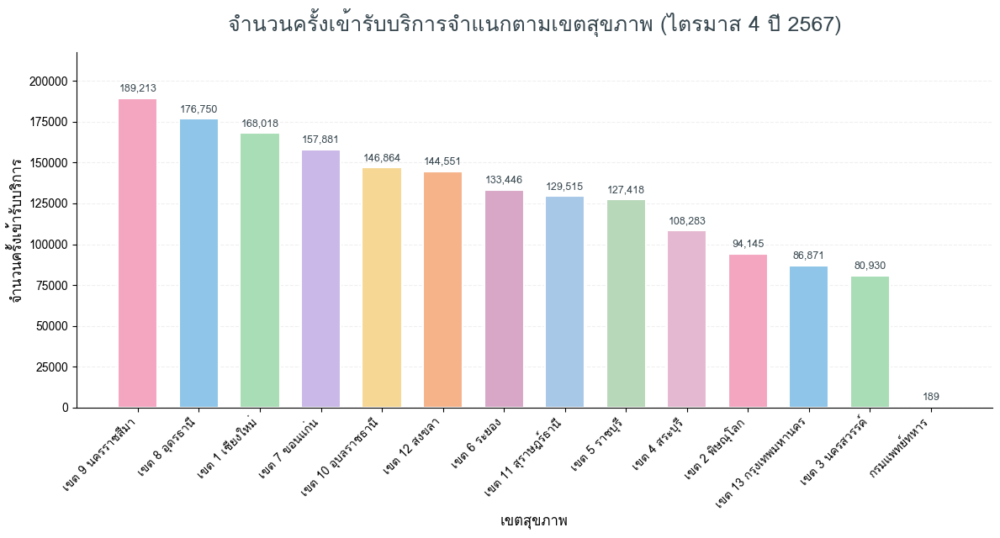

In [37]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import glob
import os

# ============================================================
# 1. ตั้งค่าฟอนต์และสี
# ============================================================

mpl.rcParams["font.family"] = "Loma"
mpl.rcParams["axes.unicode_minus"] = False

cute_colors = [
    "#F4A6C1", "#8EC5E8", "#A8DDB5", "#C9B8E8",
    "#F7D794", "#F6B38A", "#D8A7C7", "#A8C8E8",
    "#B8D8BA", "#E5B8D1"
]

# ============================================================
# 2. เตรียมข้อมูลจากไฟล์ทั้ง 4 ไตรมาส
#    ใช้ cleaned_data หากมี ไม่เช่นนั้นใช้ data
# ============================================================

source_data = cleaned_data if "cleaned_data" in globals() else data

quarter_data = {}

for key, df in source_data.items():
    if isinstance(key, int):
        q_num = key
    else:
        name = os.path.basename(str(key)).lower()
        q_num = None
        for q in range(1, 5):
            if f"67q{q}" in name:
                q_num = q
                break
        if q_num is None:
            continue

    quarter_data[f"ไตรมาส {q_num}"] = df.copy()

if not quarter_data:
    raise ValueError(
        "ไม่พบข้อมูลไฟล์ไตรมาส 1–4 กรุณาตรวจสอบชื่อไฟล์ในตัวแปร data"
    )

# รวมข้อมูลทุกไตรมาส
all_data = pd.concat(
    quarter_data.values(),
    ignore_index=True
)

# ============================================================
# 3. ฟังก์ชันสร้างกราฟจำนวนครั้งเข้ารับบริการตามเขตสุขภาพ
# ============================================================

def plot_region_service(df, title):

    required_cols = ["nhso_zonename", "n_service"]

    missing = [c for c in required_cols if c not in df.columns]

    if missing:
        print(f"ข้าม {title}: ไม่พบคอลัมน์ {missing}")
        return

    plot_data = df[required_cols].copy()

    plot_data["n_service"] = pd.to_numeric(
        plot_data["n_service"],
        errors="coerce"
    )

    plot_data = plot_data.dropna(
        subset=["nhso_zonename", "n_service"]
    )

    plot_data["nhso_zonename"] = (
        plot_data["nhso_zonename"].astype(str).str.strip()
    )

    plot_data = plot_data[
        (plot_data["nhso_zonename"] != "") &
        (plot_data["nhso_zonename"].str.lower() != "nan")
    ]

    zone_service = (
        plot_data.groupby("nhso_zonename")["n_service"]
        .sum()
        .sort_values(ascending=False)
    )

    if zone_service.empty:
        print(f"ไม่มีข้อมูลสำหรับ {title}")
        return

    fig, ax = plt.subplots(figsize=(12, 6.5))

    colors = [
        cute_colors[i % len(cute_colors)]
        for i in range(len(zone_service))
    ]

    bars = ax.bar(
        zone_service.index,
        zone_service.values,
        color=colors,
        edgecolor="white",
        linewidth=1.5,
        width=0.65
    )

    ax.set_title(
        title,
        fontsize=18,
        fontweight="bold",
        color="#37474F",
        pad=18
    )

    ax.set_xlabel(
        "เขตสุขภาพ",
        fontsize=12,
        fontweight="bold"
    )

    ax.set_ylabel(
        "จำนวนครั้งเข้ารับบริการ",
        fontsize=12,
        fontweight="bold"
    )

    plt.xticks(rotation=45, ha="right", fontsize=10)

    # ตัวเลขบนแท่งกราฟ
    for bar, value in zip(bars, zone_service.values):
        ax.annotate(
            f"{value:,.0f}",
            (bar.get_x() + bar.get_width() / 2, bar.get_height()),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=9,
            fontweight="bold",
            color="#37474F"
        )

    ax.grid(axis="y", linestyle="--", alpha=0.2)
    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.set_ylim(0, zone_service.max() * 1.15)

    plt.tight_layout()
    plt.show()


# ============================================================
# 4. กราฟรวมทุกไตรมาส
# ============================================================

plot_region_service(
    all_data,
    "จำนวนครั้งเข้ารับบริการจำแนกตามเขตสุขภาพ (รวมทั้งปี 2567)"
)

# ============================================================
# 5. กราฟแยกไตรมาส
# ============================================================

for quarter in sorted(
    quarter_data.keys(),
    key=lambda x: int(x.split()[-1])
):
    plot_region_service(
        quarter_data[quarter],
        f"จำนวนครั้งเข้ารับบริการจำแนกตามเขตสุขภาพ ({quarter} ปี 2567)"
    )

In [38]:
print("จำนวนเขตสุขภาพทั้งหมด:",
      all_data[all_data["nhso_zonename"].str.startswith("เขต", na=False)]["nhso_zonename"].nunique())

print(
    sorted(
        all_data[all_data["nhso_zonename"].str.startswith("เขต", na=False)]["nhso_zonename"]
        .unique()
    )
)

จำนวนเขตสุขภาพทั้งหมด: 13
['เขต 1 เชียงใหม่', 'เขต 10 อุบลราชธานี', 'เขต 11 สุราษฎร์ธานี', 'เขต 12 สงขลา', 'เขต 13 กรุงเทพมหานคร', 'เขต 2 พิษณุโลก', 'เขต 3 นครสวรรค์', 'เขต 4 สระบุรี', 'เขต 5 ราชบุรี', 'เขต 6 ระยอง', 'เขต 7 ขอนแก่น', 'เขต 8 อุดรธานี', 'เขต 9 นครราชสีมา']


##**จำนวนครั้งเข้ารับบริการจำแนกตามภาคและจังหวัด**

In [41]:
import plotly.express as px
import pandas as pd
import os

# ============================================================
# 1. เลือกข้อมูลที่เตรียมไว้แล้ว
# ============================================================

source_data = cleaned_data if "cleaned_data" in globals() else data

quarter_data = {}

for key, df in source_data.items():
    if isinstance(key, int):
        q_num = key
    else:
        name = os.path.basename(str(key)).lower()
        q_num = None
        for q in range(1, 5):
            if f"67q{q}" in name:
                q_num = q
                break
        if q_num is None:
            continue

    quarter_data[f"ไตรมาส {q_num}"] = df.copy()

if not quarter_data:
    raise ValueError(
        "ไม่พบไฟล์ไตรมาส 1–4 กรุณาตรวจสอบชื่อไฟล์ในตัวแปร data"
    )

# รวมข้อมูลทุกไตรมาส
all_data = pd.concat(
    quarter_data.values(),
    ignore_index=True
)

# ============================================================
# 2. กำหนดสีพาสเทลแยกตามภาค
# ============================================================

region_colors = {
    "เหนือ": "#F4A6C1",
    "ตะวันออกเฉียงเหนือ": "#8EC5E8",
    "กลาง": "#A8DDB5",
    "ตะวันตก": "#F6B38A",
    "ตะวันออก": "#F7D794",
    "ใต้": "#C9B8E8",
    "กรมแพทย์ทหารอากาศ": "#D8A7CA",
    "กรมแพทย์ทหารเรือ": "#A9C7E8"
}

# ============================================================
# 3. ฟังก์ชันสร้าง Treemap
# ============================================================

def plot_province_treemap(df, title):

    required_cols = ["ภาค", "prov", "n_service"]
    missing = [c for c in required_cols if c not in df.columns]

    if missing:
        print(f"ข้าม {title}: ไม่พบคอลัมน์ {missing}")
        return

    plot_data = df[required_cols].copy()

    plot_data["n_service"] = pd.to_numeric(
        plot_data["n_service"],
        errors="coerce"
    )

    plot_data = plot_data.dropna(
        subset=["ภาค", "prov", "n_service"]
    )

    # ทำความสะอาดชื่อภาคและจังหวัด
    for col in ["ภาค", "prov"]:
        plot_data[col] = plot_data[col].astype(str).str.strip()

    plot_data = plot_data[
        (plot_data["ภาค"] != "") &
        (plot_data["prov"] != "") &
        (plot_data["ภาค"].str.lower() != "nan") &
        (plot_data["prov"].str.lower() != "nan")
    ]

    # รวมจำนวนบริการตามภาคและจังหวัด
    province_service = (
        plot_data.groupby(["ภาค", "prov"], as_index=False)["n_service"]
        .sum()
        .sort_values("n_service", ascending=False)
    )

    if province_service.empty:
        print(f"ไม่มีข้อมูลสำหรับ {title}")
        return

    # สร้าง Treemap
    fig = px.treemap(
        province_service,
        path=["ภาค", "prov"],
        values="n_service",
        color="ภาค",
        color_discrete_map=region_colors,
        title=title
    )

    fig.update_traces(
        textinfo="label+value",
        texttemplate="%{label}<br>%{value:,.0f}",
        textfont=dict(
            size=14,
            color="#263238"
        ),
        marker=dict(
            line=dict(
                color="white",
                width=2
            )
        ),
        hovertemplate=(
            "ภาค/จังหวัด: %{label}<br>"
            "จำนวนครั้งเข้ารับบริการ: %{value:,.0f}"
            "<extra></extra>"
        )
    )

    fig.update_layout(
        width=1100,
        height=700,
        title=dict(
            text=title,
            font=dict(size=22, color="#37474F"),
            x=0.5
        ),
        margin=dict(t=80, l=20, r=20, b=20),
        paper_bgcolor="white",
        plot_bgcolor="white"
    )

    fig.show()


# ============================================================
# 4. กราฟรวมทุกไตรมาส
# ============================================================

plot_province_treemap(
    all_data,
    "จำนวนครั้งเข้ารับบริการจำแนกตามจังหวัดและภูมิภาค (รวมปี 2567)"
)

# ============================================================
# 5. กราฟแยกไตรมาส
# ============================================================

for quarter in sorted(
    quarter_data.keys(),
    key=lambda x: int(x.split()[-1])
):
    plot_province_treemap(
        quarter_data[quarter],
        f"จำนวนครั้งเข้ารับบริการจำแนกตามจังหวัดและภูมิภาค ({quarter} ปี 2567)"
    )

##**สัดส่วนผู้เข้ารับบริการจำแนกตามเพศและภูมิภาค**

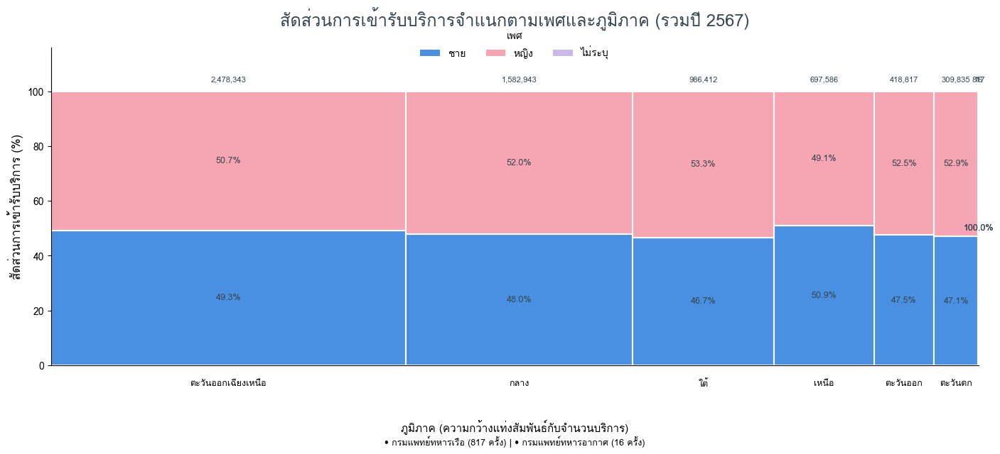

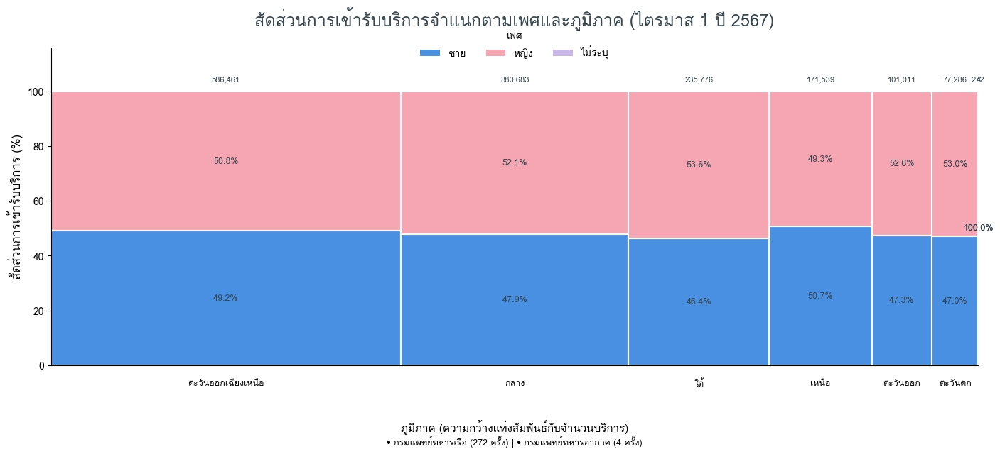

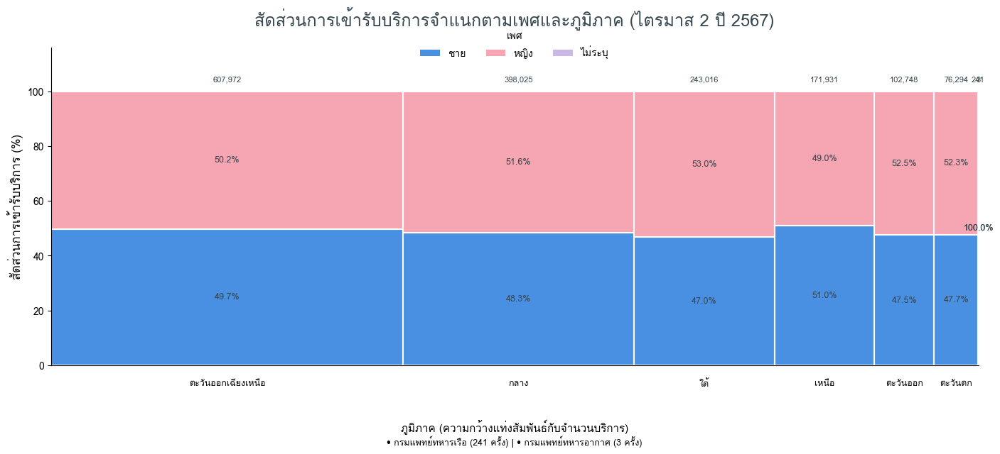

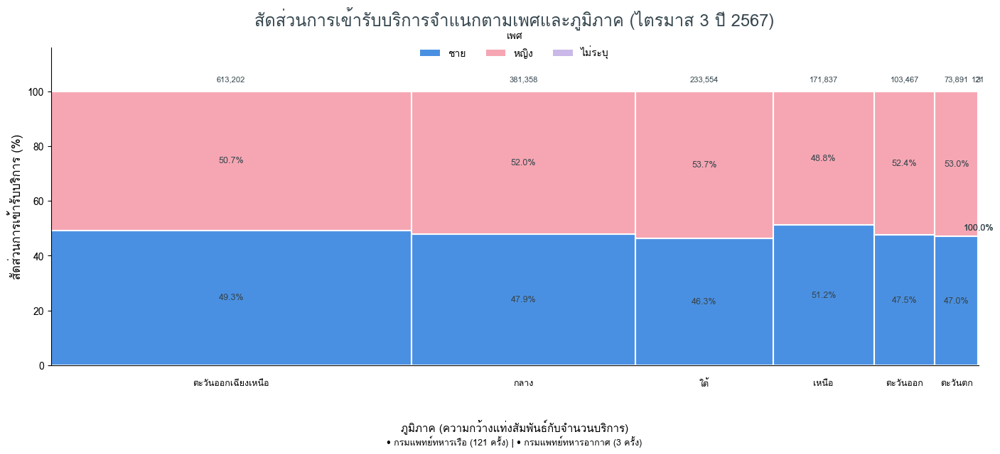

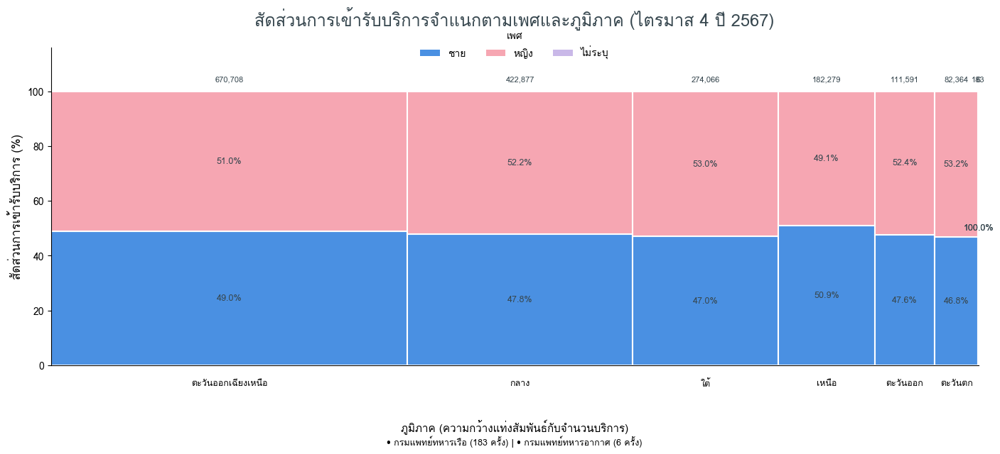

In [42]:
import matplotlib.pyplot as plt
import matplotlib as mpl
import pandas as pd
import os

# ==========================================
# 1. ตั้งค่าฟอนต์
# ==========================================
mpl.rcParams["font.family"] = "Loma"
mpl.rcParams["axes.unicode_minus"] = False

male_color = "#4A90E2"
female_color = "#F6A6B2"
unknown_color = "#C9B8E8"

# ==========================================
# 2. เตรียมข้อมูลจากทั้ง 4 ไตรมาส
# ==========================================
source_data = cleaned_data if "cleaned_data" in globals() else data

quarter_data = {}

for key, df in source_data.items():
    if isinstance(key, int):
        q_num = key
    else:
        name = os.path.basename(str(key)).lower()
        q_num = None
        for q in range(1, 5):
            if f"67q{q}" in name:
                q_num = q
                break
        if q_num is None:
            continue

    quarter_data[f"ไตรมาส {q_num}"] = df.copy()

if not quarter_data:
    raise ValueError(
        "ไม่พบไฟล์ไตรมาส 1–4 กรุณาตรวจสอบชื่อไฟล์ในตัวแปร data"
    )

all_data = pd.concat(
    quarter_data.values(),
    ignore_index=True
)

# ==========================================
# 3. ฟังก์ชันสร้างกราฟ
# ==========================================
def plot_region_gender(df, title):

    required = ["ภาค", "gender", "n_service"]
    missing = [c for c in required if c not in df.columns]

    if missing:
        print(f"ข้าม {title}: ไม่พบคอลัมน์ {missing}")
        return

    plot_data = df[required].copy()

    plot_data["n_service"] = pd.to_numeric(
        plot_data["n_service"], errors="coerce"
    )
    plot_data["gender"] = pd.to_numeric(
        plot_data["gender"], errors="coerce"
    )

    plot_data = plot_data.dropna(
        subset=["ภาค", "n_service"]
    )

    plot_data["ภาค"] = plot_data["ภาค"].astype(str).str.strip()

    plot_data["gender_label"] = plot_data["gender"].map({
        1: "ชาย",
        2: "หญิง"
    }).fillna("ไม่ระบุ")

    # รวมจำนวนบริการตามภาคและเพศ
    region_gender = (
        plot_data.groupby(["ภาค", "gender_label"])["n_service"]
        .sum()
        .unstack(fill_value=0)
    )

    # รวมทั้ง 3 กลุ่ม เพื่อให้สัดส่วนครบ 100%
    gender_order = ["ชาย", "หญิง", "ไม่ระบุ"]

    region_gender = region_gender.reindex(
        columns=gender_order,
        fill_value=0
    )

    # เรียงภาคตามจำนวนบริการรวม
    region_gender["_total"] = region_gender.sum(axis=1)
    region_gender = region_gender.sort_values(
        "_total", ascending=False
    )
    region_gender = region_gender.drop(columns="_total")

    total_region = region_gender.sum(axis=1)
    total_all = total_region.sum()

    if total_all <= 0:
        print(f"ไม่มีจำนวนบริการที่ใช้ได้สำหรับ {title}")
        return

    # ความกว้างแต่ละภาคสัมพันธ์กับจำนวนบริการของภาคนั้น
    widths = total_region / total_all

    fig, ax = plt.subplots(figsize=(15, 8))

    left = 0

    color_map = {
        "ชาย": male_color,
        "หญิง": female_color,
        "ไม่ระบุ": unknown_color
    }

    for region in region_gender.index:

        width = widths[region]
        total = total_region[region]

        if total <= 0:
            left += width
            continue

        center = left + width / 2
        bottom = 0

        for gender in gender_order:

            value = region_gender.loc[region, gender]
            pct = value / total * 100

            ax.bar(
                center,
                pct,
                bottom=bottom,
                width=width,
                color=color_map[gender],
                edgecolor="white",
                linewidth=1.5,
                label=gender
            )

            if pct >= 8:
                ax.text(
                    center,
                    bottom + pct / 2,
                    f"{pct:.1f}%",
                    ha="center",
                    va="center",
                    fontsize=9,
                    fontweight="bold",
                    color="#37474F"
                )

            bottom += pct

        # จำนวนบริการรวมด้านบน
        ax.text(
            center,
            103,
            f"{total:,.0f}",
            ha="center",
            va="bottom",
            fontsize=8,
            color="#37474F"
        )

        # ชื่อภาคใต้แท่ง
        if "กรมแพทย์" not in region:
            ax.text(
                center,
                -5,
                region,
                ha="center",
                va="top",
                fontsize=9,
                fontweight="bold"
            )

        left += width

    ax.set_ylim(0, 116)
    ax.set_xlim(0, 1)

    ax.set_ylabel("สัดส่วนการเข้ารับบริการ (%)", fontsize=12)
    ax.set_xlabel("ภูมิภาค (ความกว้างแท่งสัมพันธ์กับจำนวนบริการ)",
                  fontsize=11, labelpad=55)

    ax.set_title(
        title,
        fontsize=17,
        fontweight="bold",
        color="#37474F",
        pad=22
    )

    ax.set_xticks([])

    ax.yaxis.grid(
        True,
        linestyle="--",
        alpha=0.25
    )
    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # ชื่อหน่วยงานพิเศษด้านล่าง หากมีในข้อมูล
    special_regions = [
        r for r in region_gender.index if "กรมแพทย์" in r
    ]

    if special_regions:
        special_text = [
            f"• {r} ({total_region[r]:,.0f} ครั้ง)"
            for r in special_regions
        ]

        ax.text(
            0.5, -0.22,
            " | ".join(special_text),
            transform=ax.transAxes,
            ha="center",
            va="top",
            fontsize=9
        )

    # กำหนด legend ไม่ให้แสดงรายการซ้ำ
    from matplotlib.patches import Patch

    legend_handles = [
        Patch(facecolor=male_color, label="ชาย"),
        Patch(facecolor=female_color, label="หญิง"),
        Patch(facecolor=unknown_color, label="ไม่ระบุ")
    ]

    ax.legend(
        handles=legend_handles,
        title="เพศ",
        loc="upper center",
        bbox_to_anchor=(0.5, 1.08),
        ncol=3,
        frameon=False
    )

    plt.subplots_adjust(
        bottom=0.30,
        top=0.86,
        left=0.08,
        right=0.95
    )

    plt.show()


# ==========================================
# 4. กราฟรวมทั้ง 4 ไตรมาส
# ==========================================
plot_region_gender(
    all_data,
    "สัดส่วนการเข้ารับบริการจำแนกตามเพศและภูมิภาค (รวมปี 2567)"
)

# ==========================================
# 5. กราฟแยกแต่ละไตรมาส
# ==========================================
for quarter in sorted(
    quarter_data.keys(),
    key=lambda x: int(x.split()[-1])
):
    plot_region_gender(
        quarter_data[quarter],
        f"สัดส่วนการเข้ารับบริการจำแนกตามเพศและภูมิภาค ({quarter} ปี 2567)"
    )

##**จำนวนครั้งเข้ารับบริการจำแนกตามเดือนและเพศ**

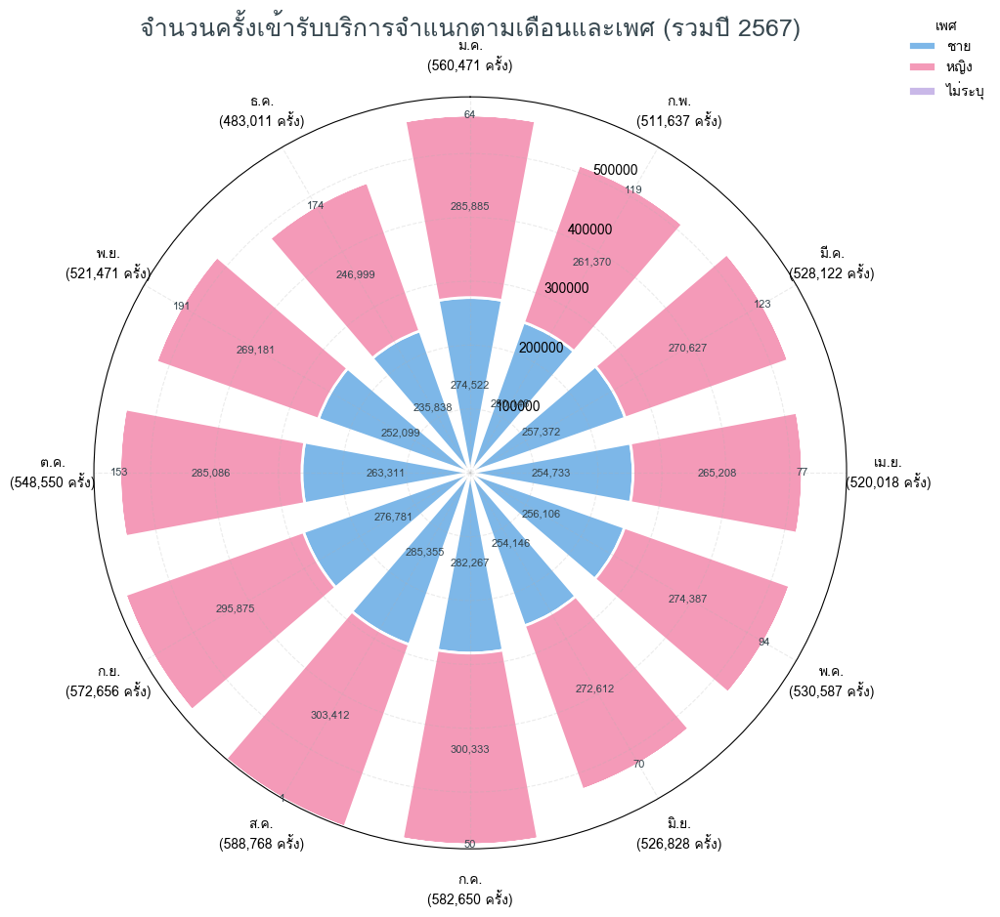

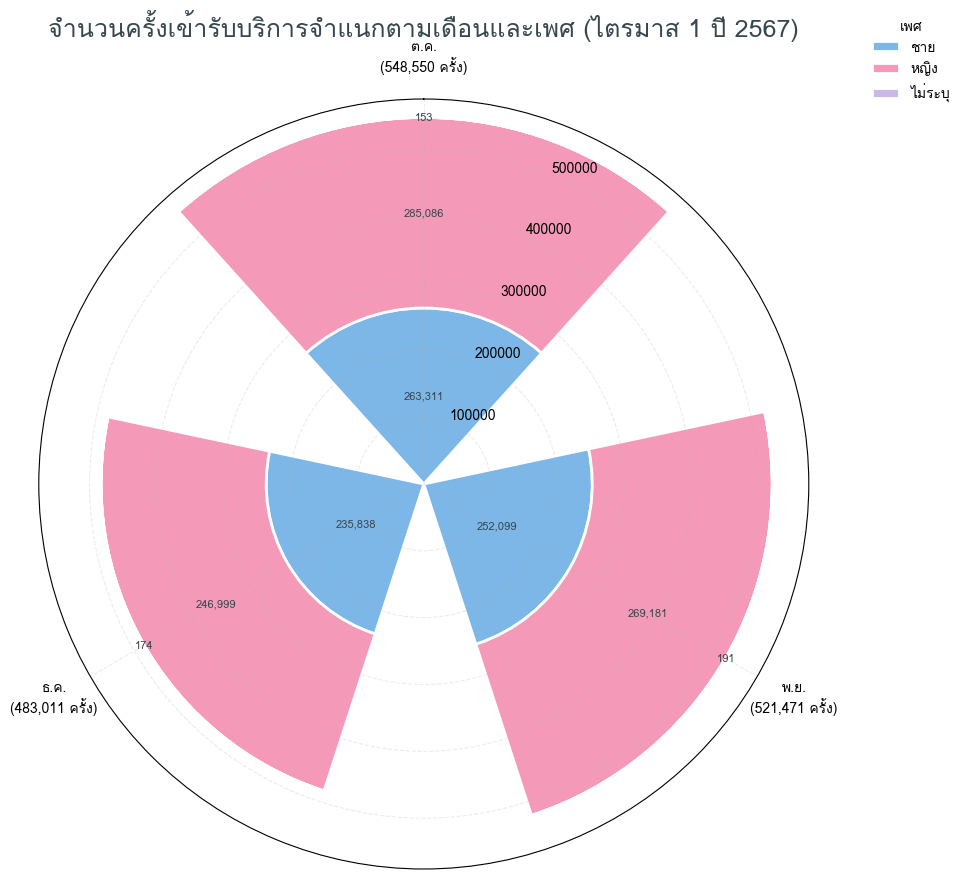

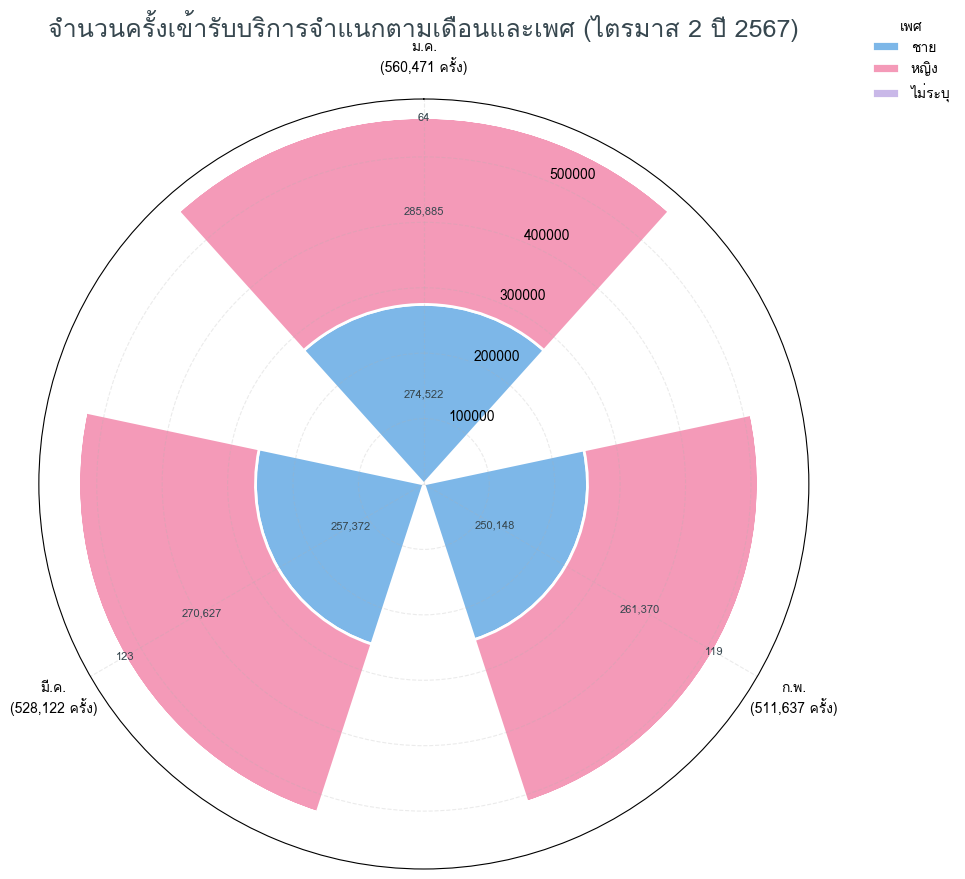

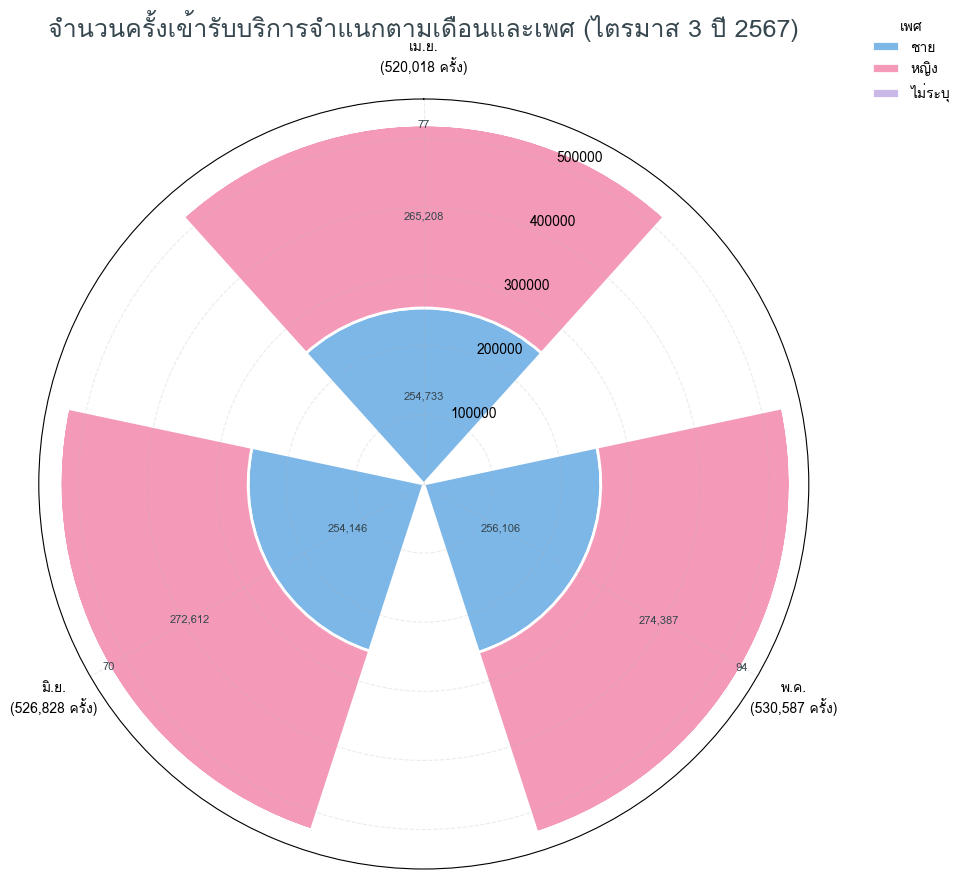

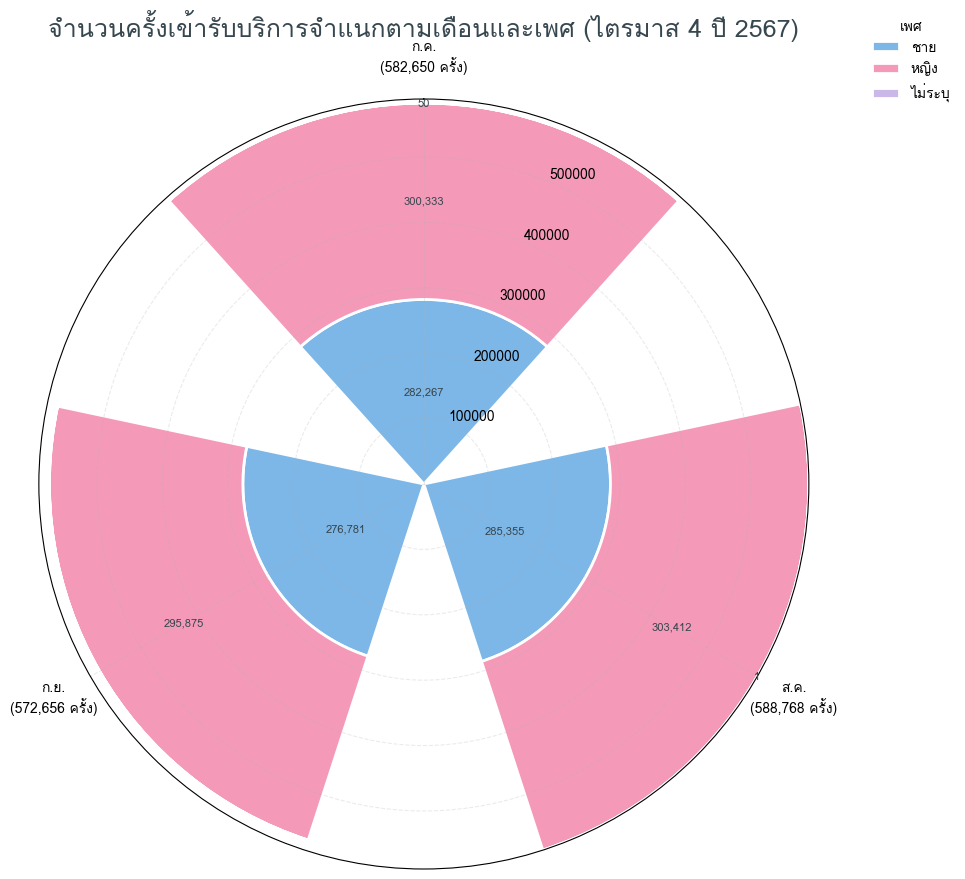

In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import os

# ==========================================
# 1. ตั้งค่าฟอนต์
# ==========================================
mpl.rcParams["font.family"] = "Loma"
mpl.rcParams["axes.unicode_minus"] = False

male_color = "#7DB7E8"
female_color = "#F49AB8"
unknown_color = "#C9B8E8"

month_names = {
    1: "ม.ค.", 2: "ก.พ.", 3: "มี.ค.", 4: "เม.ย.",
    5: "พ.ค.", 6: "มิ.ย.", 7: "ก.ค.", 8: "ส.ค.",
    9: "ก.ย.", 10: "ต.ค.", 11: "พ.ย.", 12: "ธ.ค."
}

# ==========================================
# 2. เตรียมข้อมูลจากทั้ง 4 ไตรมาส
# ==========================================
source_data = cleaned_data if "cleaned_data" in globals() else data

quarter_data = {}

for key, df in source_data.items():
    if isinstance(key, int):
        q_num = key
    else:
        name = os.path.basename(str(key)).lower()
        q_num = None
        for q in range(1, 5):
            if f"67q{q}" in name:
                q_num = q
                break
        if q_num is None:
            continue

    quarter_data[f"ไตรมาส {q_num}"] = df.copy()

if not quarter_data:
    raise ValueError(
        "ไม่พบไฟล์ไตรมาส 1–4 กรุณาตรวจสอบชื่อไฟล์ในตัวแปร data"
    )

all_data = pd.concat(
    quarter_data.values(),
    ignore_index=True
)

# ==========================================
# 3. ฟังก์ชันสร้างกราฟวงกลม
# ==========================================
def plot_monthly_gender(df, title):

    required = ["month_no", "gender", "n_service"]
    missing = [c for c in required if c not in df.columns]

    if missing:
        print(f"ข้าม {title}: ไม่พบคอลัมน์ {missing}")
        return

    df = df[required].copy()

    # แปลงเดือน
    df["date"] = pd.to_datetime(
        df["month_no"].astype(str).str.replace(r"\.0$", "", regex=True),
        format="%Y%m",
        errors="coerce"
    )

    df["month"] = df["date"].dt.month
    df["gender"] = pd.to_numeric(df["gender"], errors="coerce")
    df["n_service"] = pd.to_numeric(df["n_service"], errors="coerce")

    df = df.dropna(subset=["month", "n_service"])

    # แปลงรหัสเพศ
    df["gender_label"] = df["gender"].map({
        1: "ชาย",
        2: "หญิง"
    }).fillna("ไม่ระบุ")

    # รวมจำนวนบริการตามเดือนและเพศ
    monthly_gender = (
        df.groupby(["month", "gender_label"])["n_service"]
        .sum()
        .unstack(fill_value=0)
    )

    if monthly_gender.empty:
        print(f"ไม่มีข้อมูลเดือนที่ใช้ได้สำหรับ {title}")
        return

    # เรียงเดือนตามลำดับจริงที่พบในข้อมูล
    available_months = sorted(monthly_gender.index)

    monthly_gender = monthly_gender.reindex(available_months)

    for gender in ["ชาย", "หญิง", "ไม่ระบุ"]:
        if gender not in monthly_gender.columns:
            monthly_gender[gender] = 0

    male = monthly_gender["ชาย"].to_numpy()
    female = monthly_gender["หญิง"].to_numpy()
    unknown = monthly_gender["ไม่ระบุ"].to_numpy()

    # ==========================================
    # ตำแหน่งรอบวง
    # ==========================================
    n_months = len(available_months)

    theta = np.linspace(
        0, 2 * np.pi,
        n_months,
        endpoint=False
    )

    width = (2 * np.pi / n_months) * 0.70

    # ==========================================
    # สร้างกราฟ
    # ==========================================
    fig, ax = plt.subplots(
        figsize=(11, 11),
        subplot_kw={"projection": "polar"}
    )

    # แท่งชาย
    ax.bar(
        theta,
        male,
        width=width,
        color=male_color,
        edgecolor="white",
        linewidth=2,
        label="ชาย"
    )

    # แท่งหญิงซ้อนต่อจากชาย
    ax.bar(
        theta,
        female,
        width=width,
        bottom=male,
        color=female_color,
        edgecolor="white",
        linewidth=2,
        label="หญิง"
    )

    # แท่งไม่ระบุเพศซ้อนต่อจากหญิง
    ax.bar(
        theta,
        unknown,
        width=width,
        bottom=male + female,
        color=unknown_color,
        edgecolor="white",
        linewidth=2,
        label="ไม่ระบุ"
    )

    # ==========================================
    # ชื่อเดือนและจำนวนบริการรวม
    # ==========================================
    ax.set_xticks(theta)

    labels = [
        f"{month_names.get(m, f'เดือน {m}')}\n"
        f"({monthly_gender.loc[m].sum():,.0f} ครั้ง)"
        for m in available_months
    ]

    ax.set_xticklabels(labels, fontsize=10)
    ax.tick_params(axis="x", pad=20)

    ax.set_title(
        title,
        fontsize=18,
        fontweight="bold",
        color="#37474F",
        pad=45
    )

    # ==========================================
    # แสดงตัวเลขบนแท่ง
    # ==========================================
    for i in range(n_months):

        segments = [
            (male[i], 0),
            (female[i], male[i]),
            (unknown[i], male[i] + female[i])
        ]

        for value, bottom in segments:
            if value > 0:
                ax.text(
                    theta[i],
                    bottom + value / 2,
                    f"{value:,.0f}",
                    ha="center",
                    va="center",
                    fontsize=8,
                    fontweight="bold",
                    color="#37474F"
                )

    # ==========================================
    # Legend และทิศทาง
    # ==========================================
    ax.legend(
        title="เพศ",
        loc="upper right",
        bbox_to_anchor=(1.20, 1.12),
        frameon=False,
        fontsize=10
    )

    ax.grid(linestyle="--", alpha=0.25)

    ax.set_theta_zero_location("N")
    ax.set_theta_direction(-1)

    plt.subplots_adjust(
        top=0.80,
        bottom=0.10,
        left=0.08,
        right=0.86
    )

    plt.show()


# ==========================================
# 4. กราฟรวมทั้งปี 2567
# ==========================================
plot_monthly_gender(
    all_data,
    "จำนวนครั้งเข้ารับบริการจำแนกตามเดือนและเพศ (รวมปี 2567)"
)

# ==========================================
# 5. กราฟแยกไตรมาส 1–4
# ==========================================
for quarter in sorted(
    quarter_data.keys(),
    key=lambda x: int(x.split()[-1])
):
    plot_monthly_gender(
        quarter_data[quarter],
        f"จำนวนครั้งเข้ารับบริการจำแนกตามเดือนและเพศ ({quarter} ปี 2567)"
    )

In [48]:
print("ค่า month_no ที่พบ:")
print(sorted(all_data["month_no"].astype(str).unique()))

print("\nจำนวนข้อมูลแต่ละเดือน:")
print(all_data["month_no"].value_counts().sort_index())

print("\nจำนวนเดือนที่แปลงวันที่ได้:")
print(all_data["date"].dt.to_period("M").value_counts().sort_index())

ค่า month_no ที่พบ:
['202310', '202311', '202312', '202401', '202402', '202403', '202404', '202405', '202406', '202407', '202408', '202409']

จำนวนข้อมูลแต่ละเดือน:
month_no
202310    171749
202311    168324
202312    159845
202401    171732
202402    164636
202403    170192
202404    168485
202405    170886
202406    168366
202407    175977
202408    176694
202409    173466
Name: count, dtype: int64

จำนวนเดือนที่แปลงวันที่ได้:
date
2023-10    171749
2023-11    168324
2023-12    159845
2024-01    171732
2024-02    164636
2024-03    170192
2024-04    168485
2024-05    170886
2024-06    168366
2024-07    175977
2024-08    176694
2024-09    173466
Freq: M, Name: count, dtype: int64


##**สัดส่วนผู้เข้ารับบริการจำแนกตามภูมิภาคและเพศ**

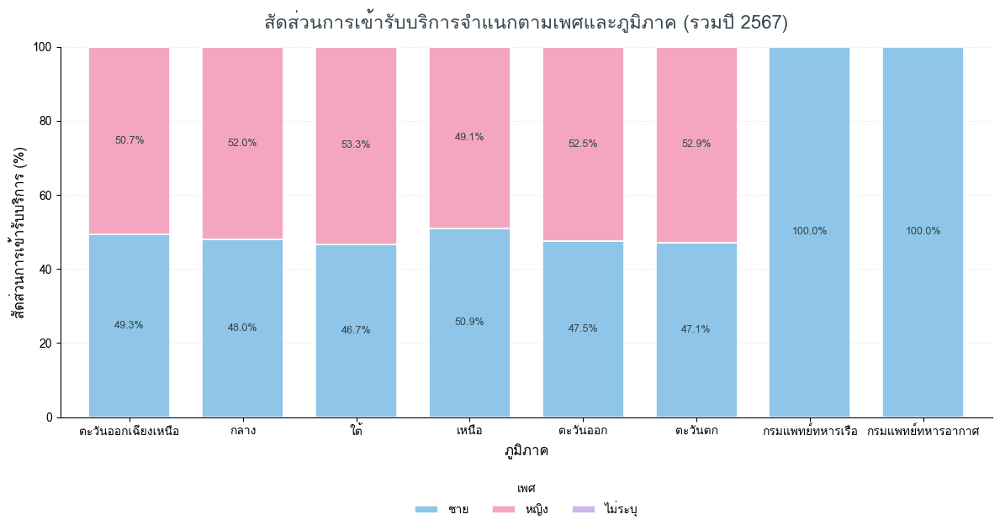

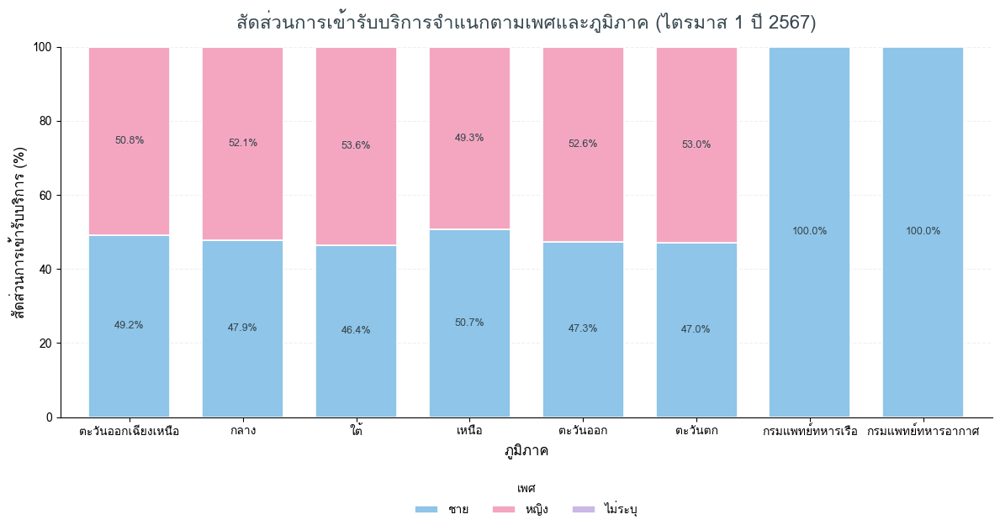

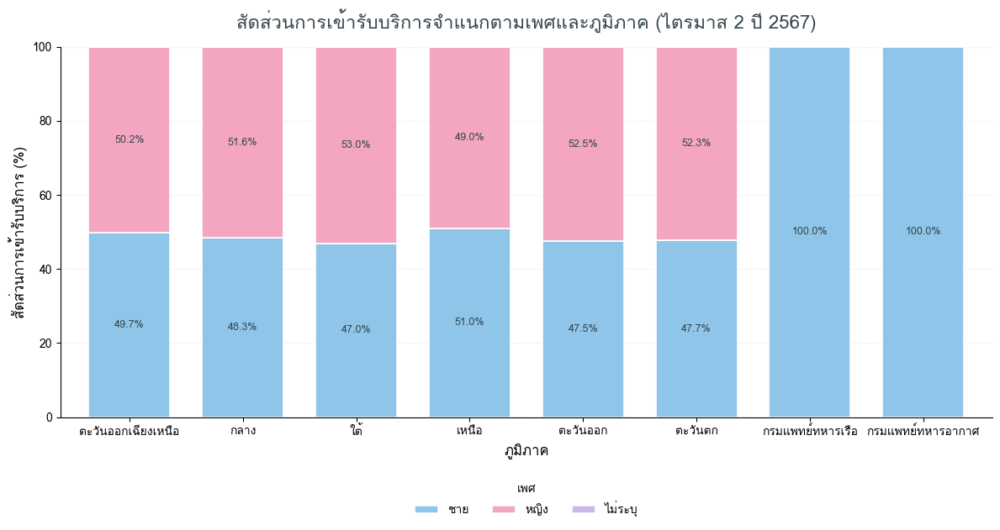

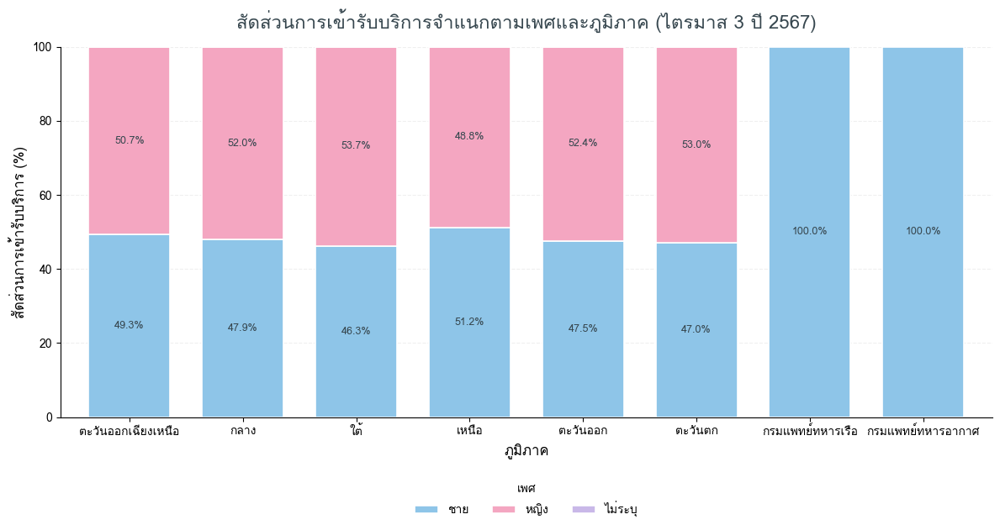

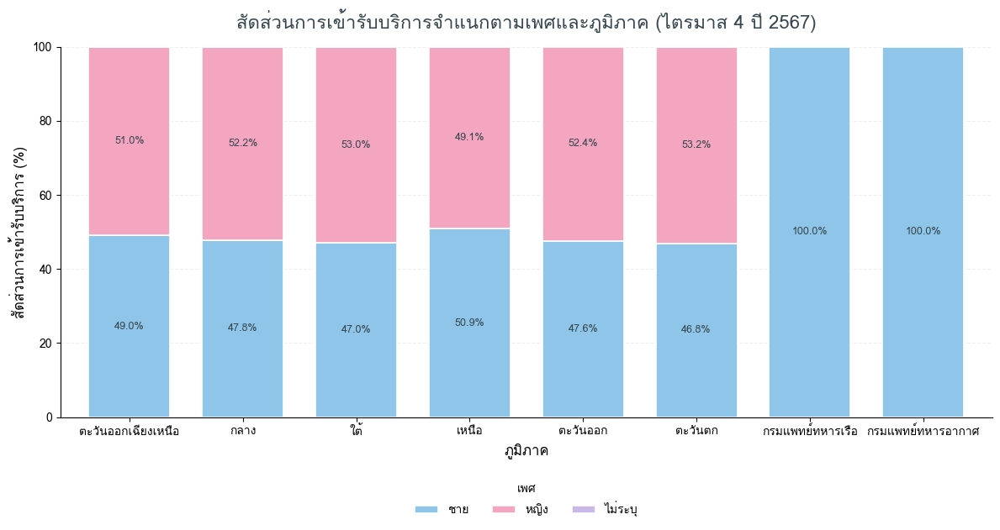

In [50]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import os

# ==========================================
# 1. ตั้งค่าฟอนต์และสี
# ==========================================
mpl.rcParams["font.family"] = "Loma"
mpl.rcParams["axes.unicode_minus"] = False

colors = {
    "ชาย": "#8EC5E8",
    "หญิง": "#F4A6C1",
    "ไม่ระบุ": "#C9B8E8"
}

gender_order = ["ชาย", "หญิง", "ไม่ระบุ"]

# ==========================================
# 2. เตรียมข้อมูลทั้ง 4 ไตรมาส
# ==========================================
source_data = cleaned_data if "cleaned_data" in globals() else data

quarter_data = {}

for key, df in source_data.items():
    if isinstance(key, int):
        # หากคีย์เป็นตัวเลขจำนวนเต็ม
        quarter_data[f"ไตรมาส {key}"] = df.copy()
    else:
        # หากคีย์เป็นข้อความชื่อไฟล์
        name = os.path.basename(str(key)).lower()
        for q in range(1, 5):
            if f"67q{q}" in name:
                quarter_data[f"ไตรมาส {q}"] = df.copy()
                break

if not quarter_data:
    raise ValueError(
        "ไม่พบไฟล์ไตรมาส 1–4 กรุณาตรวจสอบชื่อไฟล์ในตัวแปรข้อมูล"
    )

all_data = pd.concat(
    quarter_data.values(),
    ignore_index=True
)

# ==========================================
# 3. ฟังก์ชันสร้างกราฟ
# ==========================================
def plot_region_gender_pct(df, title):

    required = ["ภาค", "gender", "n_service"]
    missing = [c for c in required if c not in df.columns]

    if missing:
        print(f"ข้าม {title}: ไม่พบคอลัมน์ {missing}")
        return

    plot_data = df[required].copy()

    plot_data["n_service"] = pd.to_numeric(
        plot_data["n_service"], errors="coerce"
    )
    plot_data["gender"] = pd.to_numeric(
        plot_data["gender"], errors="coerce"
    )

    plot_data = plot_data.dropna(
        subset=["ภาค", "n_service"]
    )

    plot_data["ภาค"] = plot_data["ภาค"].astype(str).str.strip()

    plot_data = plot_data[
        (plot_data["ภาค"] != "") &
        (plot_data["ภาค"].str.lower() != "nan")
    ]

    # แปลงรหัสเพศ
    plot_data["gender_label"] = plot_data["gender"].map({
        1: "ชาย",
        2: "หญิง"
    }).fillna("ไม่ระบุ")

    # รวมจำนวนบริการตามภูมิภาคและเพศ
    region_gender = (
        plot_data.groupby(["ภาค", "gender_label"])["n_service"]
        .sum()
        .unstack(fill_value=0)
    )

    # ให้ทุกกราฟมีลำดับเพศเดียวกัน
    region_gender = region_gender.reindex(
        columns=gender_order,
        fill_value=0
    )

    # เรียงภูมิภาคตามจำนวนบริการรวม
    region_gender = region_gender.loc[
        region_gender.sum(axis=1).sort_values(
            ascending=False
        ).index
    ]

    # ตัดภูมิภาคที่ไม่มีจำนวนบริการ
    region_gender = region_gender.loc[
        region_gender.sum(axis=1) > 0
    ]

    if region_gender.empty:
        print(f"ไม่มีข้อมูลที่ใช้ได้สำหรับ {title}")
        return

    # คำนวณเปอร์เซ็นต์ภายในแต่ละภูมิภาค
    region_gender_pct = (
        region_gender.div(
            region_gender.sum(axis=1),
            axis=0
        ) * 100
    )

    # ==========================================
    # วาดกราฟ
    # ==========================================
    fig, ax = plt.subplots(figsize=(12, 6.5))

    plot_colors = [
        colors[col] for col in region_gender_pct.columns
    ]

    region_gender_pct.plot(
        kind="bar",
        stacked=True,
        color=plot_colors,
        edgecolor="white",
        linewidth=1.2,
        ax=ax,
        width=0.72
    )

    ax.set_title(
        title,
        fontsize=16,
        fontweight="bold",
        color="#37474F",
        pad=16
    )

    ax.set_xlabel("ภูมิภาค", fontsize=12)
    ax.set_ylabel("สัดส่วนการเข้ารับบริการ (%)", fontsize=12)

    ax.set_ylim(0, 100)
    ax.set_xticklabels(
        ax.get_xticklabels(),
        rotation=0,
        ha="center"
    )

    # ==========================================
    # ใส่เปอร์เซ็นต์บนแท่ง
    # ==========================================
    for container in ax.containers:

        labels = [
            f"{bar.get_height():.1f}%"
            if bar.get_height() >= 5
            else ""
            for bar in container
        ]

        ax.bar_label(
            container,
            labels=labels,
            label_type="center",
            fontsize=9,
            fontweight="bold",
            color="#37474F"
        )

    # ==========================================
    # Grid และกรอบ
    # ==========================================
    ax.yaxis.grid(
        True,
        linestyle="--",
        alpha=0.2
    )

    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # ==========================================
    # Legend
    # ==========================================
    ax.legend(
        title="เพศ",
        loc="upper center",
        bbox_to_anchor=(0.5, -0.15),
        ncol=3,
        frameon=False
    )

    plt.tight_layout()
    plt.show()


# ==========================================
# 4. กราฟรวมทั้งปี 2567
# ==========================================
plot_region_gender_pct(
    all_data,
    "สัดส่วนการเข้ารับบริการจำแนกตามเพศและภูมิภาค (รวมปี 2567)"
)

# ==========================================
# 5. กราฟแยกไตรมาส 1–4
# ==========================================
for quarter in sorted(
    quarter_data.keys(),
    key=lambda x: int(x.split()[-1])
):
    plot_region_gender_pct(
        quarter_data[quarter],
        f"สัดส่วนการเข้ารับบริการจำแนกตามเพศและภูมิภาค ({quarter} ปี 2567)"
    )

##**TOP 10 กลุ่มโรคที่มีจำนวนครั้งเข้ารับบริการสูงสุด**


Top 10 กลุ่มโรค — รวมทั้งปี 2567


,อันดับ,กลุ่มโรค,จำนวนครั้งเข้ารับบริการ
0,1,Diarrhoea and gastroenteritis of presumed infe...,"313,423"
1,2,Pneumonia organism unspecified,"253,856"
2,3,Senile cataract,"202,493"
3,4,Non-insulin-dependent diabetes mellitus,"141,804"
4,5,Other chronic obstructive pulmonary disease,"136,507"
5,6,Chronic renal failure,"134,969"
6,7,Thalassaemia,"129,834"
7,8,Heart failure,"127,285"
8,9,Cerebral infarction,"124,355"
9,10,Acute bronchitis,"122,137"


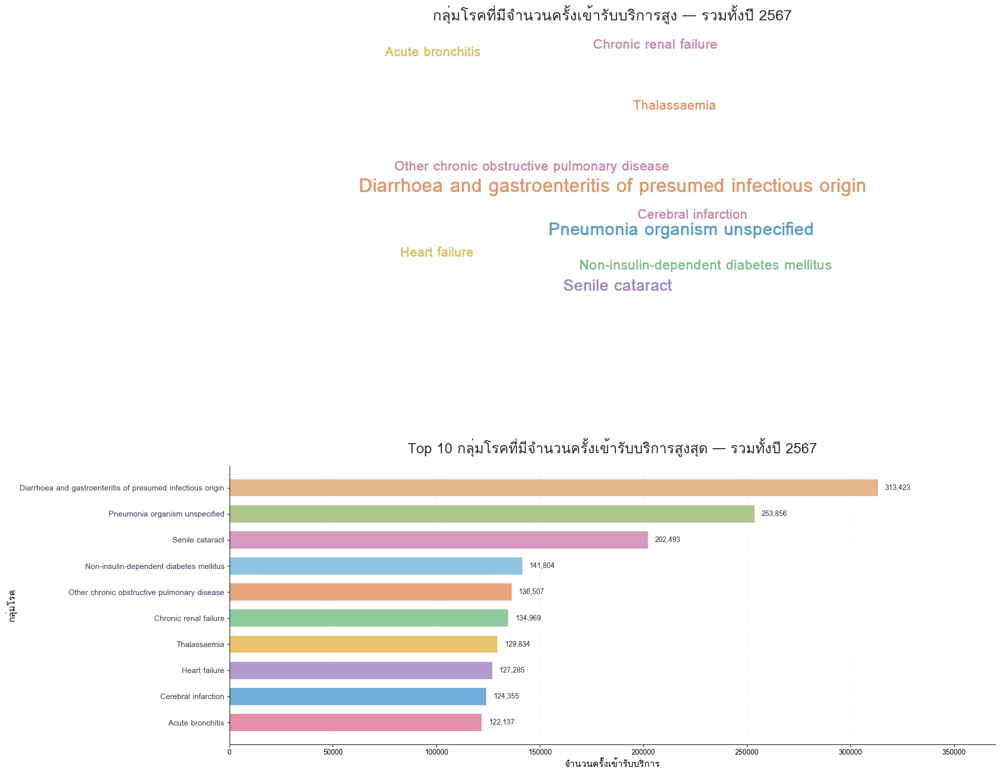


Top 10 กลุ่มโรค — ไตรมาส 1 ปี 2567


,อันดับ,กลุ่มโรค,จำนวนครั้งเข้ารับบริการ
0,1,Pneumonia organism unspecified,"64,763"
1,2,Diarrhoea and gastroenteritis of presumed infe...,"61,317"
2,3,Senile cataract,"45,298"
3,4,Other chronic obstructive pulmonary disease,"33,779"
4,5,Chronic renal failure,"32,824"
5,6,Acute bronchitis,"31,963"
6,7,Heart failure,"31,903"
7,8,Thalassaemia,"30,878"
8,9,Non-insulin-dependent diabetes mellitus,"30,675"
9,10,Cerebral infarction,"29,360"


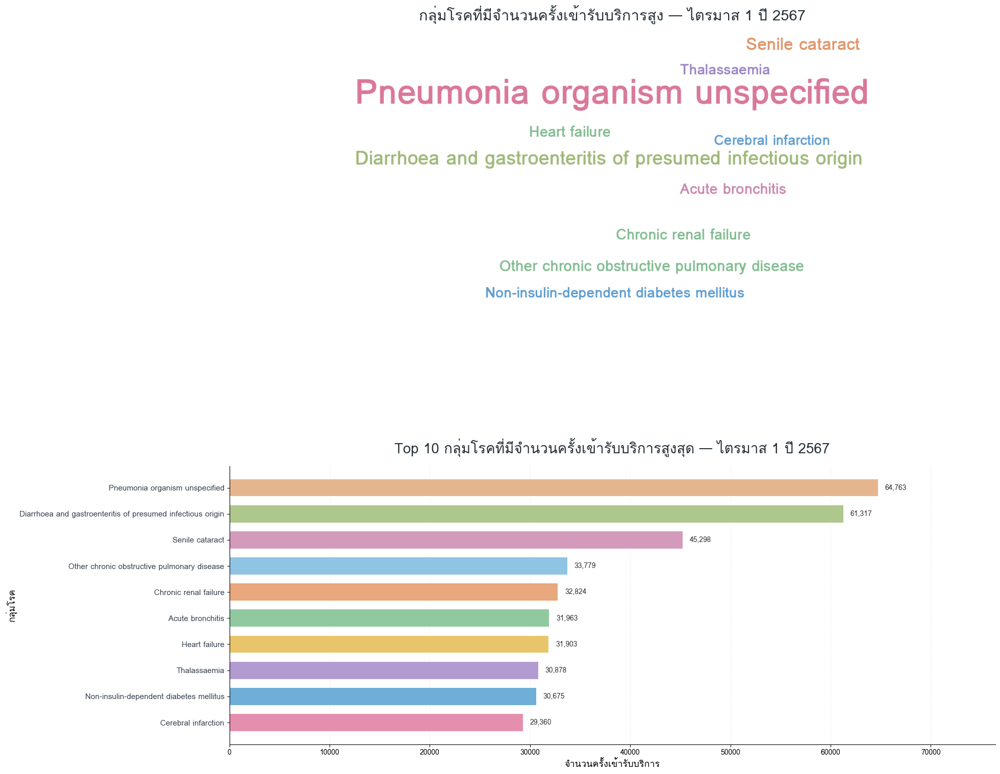


Top 10 กลุ่มโรค — ไตรมาส 2 ปี 2567


,อันดับ,กลุ่มโรค,จำนวนครั้งเข้ารับบริการ
0,1,Diarrhoea and gastroenteritis of presumed infe...,"80,470"
1,2,Pneumonia organism unspecified,"67,459"
2,3,Senile cataract,"54,313"
3,4,Other chronic obstructive pulmonary disease,"37,607"
4,5,Heart failure,"34,328"
5,6,Non-insulin-dependent diabetes mellitus,"34,286"
6,7,Chronic renal failure,"33,973"
7,8,Thalassaemia,"32,159"
8,9,Cerebral infarction,"31,880"
9,10,Acute bronchitis,"31,482"


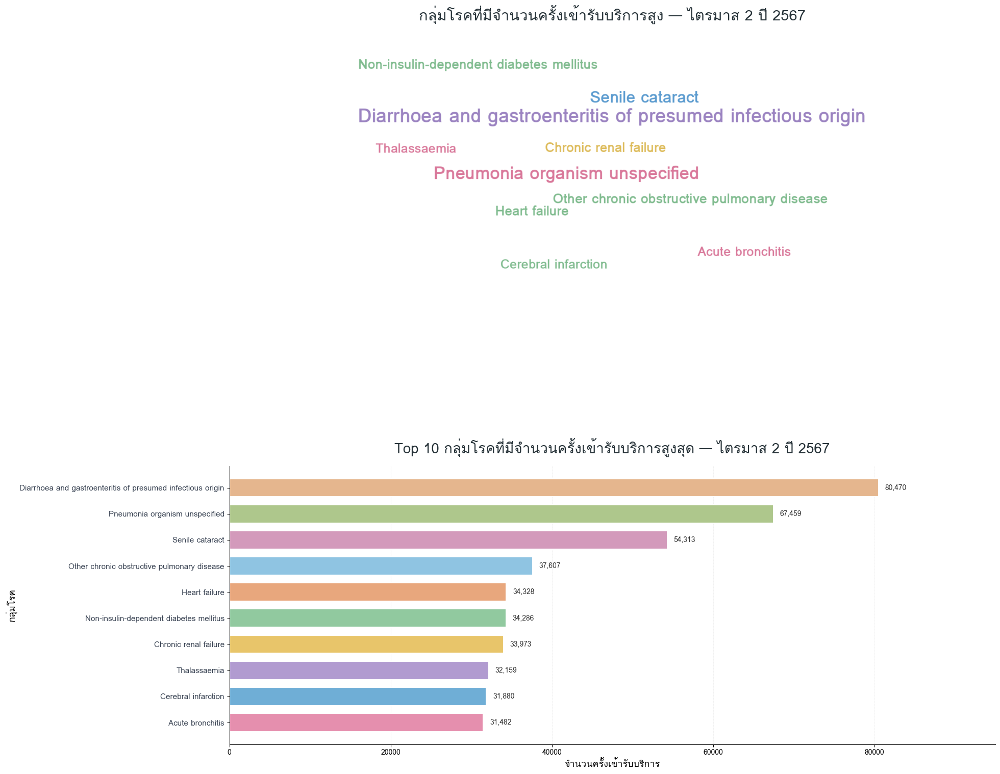


Top 10 กลุ่มโรค — ไตรมาส 3 ปี 2567


,อันดับ,กลุ่มโรค,จำนวนครั้งเข้ารับบริการ
0,1,Diarrhoea and gastroenteritis of presumed infe...,"84,930"
1,2,Pneumonia organism unspecified,"50,406"
2,3,Senile cataract,"49,593"
3,4,Non-insulin-dependent diabetes mellitus,"38,488"
4,5,Thalassaemia,"33,417"
5,6,Chronic renal failure,"33,118"
6,7,Other disorders of urinary system,"31,682"
7,8,Other chronic obstructive pulmonary disease,"31,542"
8,9,Cerebral infarction,"31,210"
9,10,Heart failure,"27,320"


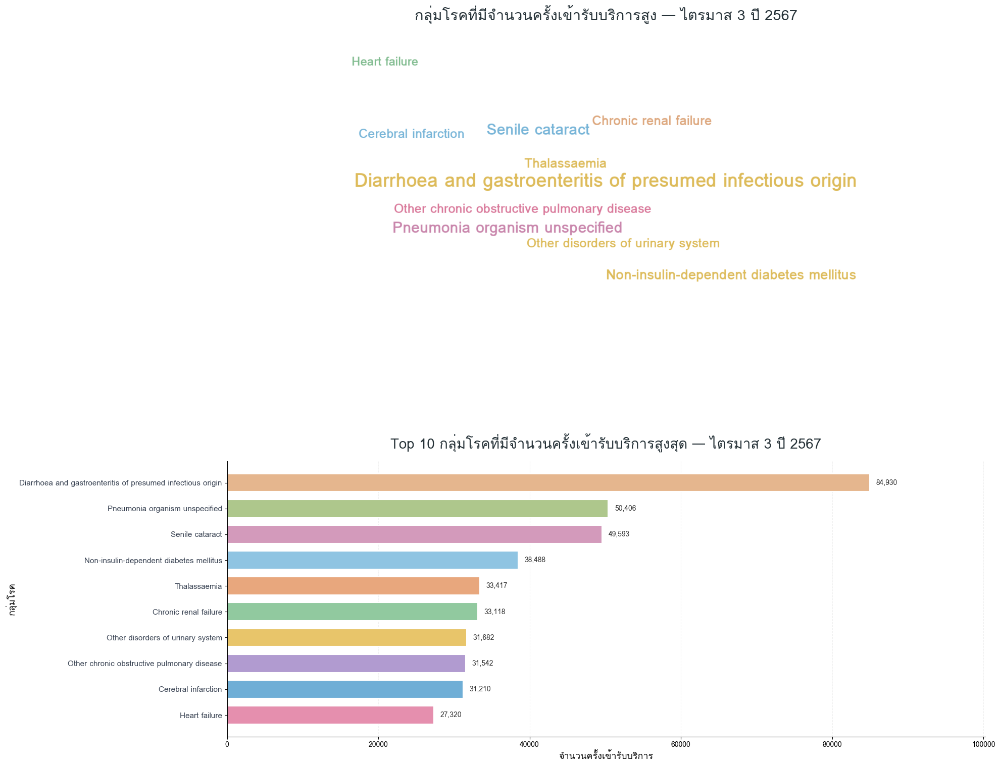


Top 10 กลุ่มโรค — ไตรมาส 4 ปี 2567


,อันดับ,กลุ่มโรค,จำนวนครั้งเข้ารับบริการ
0,1,Diarrhoea and gastroenteritis of presumed infe...,"86,706"
1,2,Pneumonia organism unspecified,"71,228"
2,3,Senile cataract,"53,289"
3,4,Acute bronchitis,"38,455"
4,5,Non-insulin-dependent diabetes mellitus,"38,355"
5,6,Chronic renal failure,"35,054"
6,7,Heart failure,"33,734"
7,8,Other chronic obstructive pulmonary disease,"33,579"
8,9,Thalassaemia,"33,380"
9,10,Cerebral infarction,"31,905"


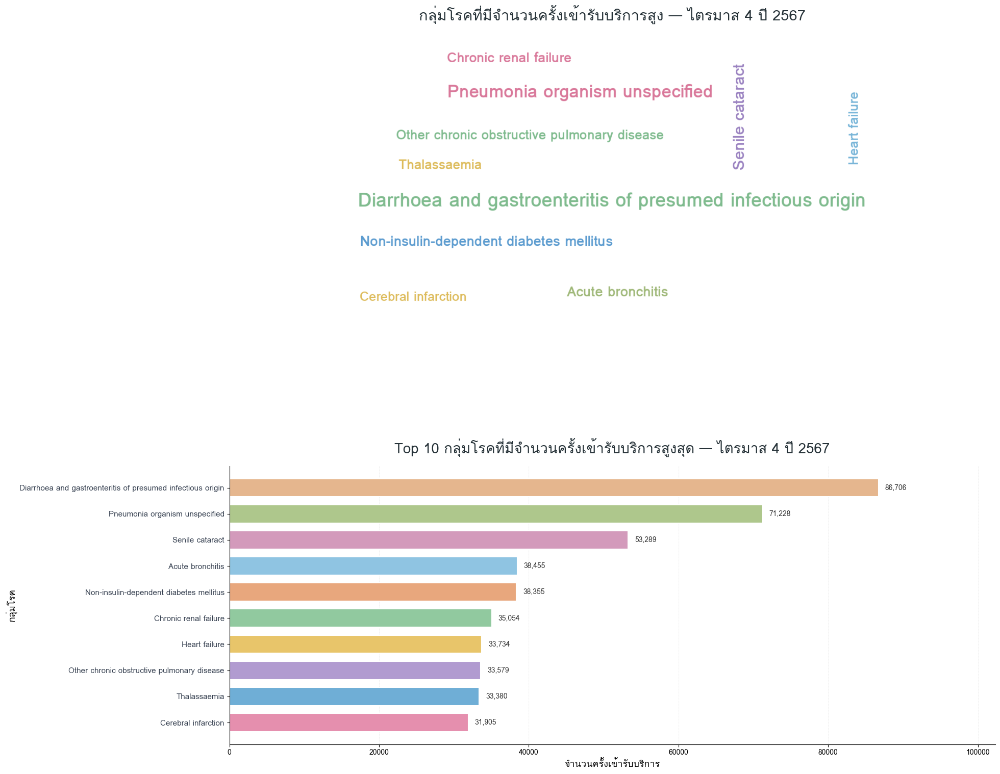

In [52]:
# ============================================================
# TOP 10 กลุ่มโรคที่มีจำนวนครั้งเข้ารับบริการสูงสุด
# รวมทั้งปี + แยก 4 ไตรมาส
# Table + Word Cloud + Bar Chart
# ============================================================

!pip -q install wordcloud

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from wordcloud import WordCloud
from IPython.display import display
import os
import random

# ============================================================
# 1) ตั้งค่าฟอนต์และสี
# ============================================================

mpl.rcParams["font.family"] = "Loma"
mpl.rcParams["axes.unicode_minus"] = False

font_candidates = [
    "/usr/share/fonts/truetype/tlwg/Loma-Bold.ttf",
    "/usr/share/fonts/truetype/tlwg/Loma.ttf"
]

font_path = next(
    (p for p in font_candidates if os.path.exists(p)),
    None
)

pastel_colors = [
    "#E58FAE", "#6FAED6", "#B19BD0", "#E8C56A",
    "#91C99F", "#E8A77D", "#8FC4E2", "#D39ABB",
    "#AEC78C", "#E5B68E"
]

wordcloud_colors = [
    "#D9789A", "#5B9BCF", "#9B83C1", "#DDBB5A",
    "#7FBB8E", "#DF966B", "#78B5D8", "#C986AC",
    "#9FB878", "#DDA77D"
]

def dark_color_func(
    word, font_size, position, orientation,
    random_state=None, **kwargs
):
    return random.choice(wordcloud_colors)

# ============================================================
# 2) เตรียมข้อมูลจาก 4 ไตรมาส
# ============================================================

source_data = cleaned_data if "cleaned_data" in globals() else data

quarter_data = {}

for key, df in source_data.items():
    if isinstance(key, int):
        # หากคีย์เป็นตัวเลขจำนวนเต็ม
        quarter_data[f"ไตรมาส {key}"] = df.copy()
    else:
        # หากคีย์เป็นข้อความชื่อไฟล์
        name = os.path.basename(str(key)).lower()
        for q in range(1, 5):
            if f"67q{q}" in name:
                quarter_data[f"ไตรมาส {q}"] = df.copy()
                break

if not quarter_data:
    raise ValueError(
        "ไม่พบไฟล์ไตรมาส 1–4 กรุณาตรวจสอบชื่อไฟล์ในตัวแปรข้อมูล"
    )

all_data = pd.concat(
    quarter_data.values(),
    ignore_index=True
)

# ============================================================
# 3) ฟังก์ชันสร้างตาราง + Word Cloud + Bar Chart
# ============================================================

def plot_top10_diseases(df, period_title):

    required = ["pdx_name", "n_service"]
    missing = [c for c in required if c not in df.columns]

    if missing:
        print(f"ข้าม {period_title}: ไม่พบคอลัมน์ {missing}")
        return

    plot_data = df[required].copy()

    plot_data["n_service"] = pd.to_numeric(
        plot_data["n_service"], errors="coerce"
    )

    plot_data["pdx_name"] = (
        plot_data["pdx_name"].astype("string").str.strip()
    )

    plot_data = plot_data.dropna(
        subset=["pdx_name", "n_service"]
    )

    plot_data = plot_data[
        (plot_data["pdx_name"] != "") &
        (plot_data["pdx_name"].str.lower() != "nan")
    ]

    disease_counts = (
        plot_data.groupby("pdx_name")["n_service"]
        .sum()
        .sort_values(ascending=False)
    )

    top10 = disease_counts.head(10)

    if top10.empty:
        print(f"ไม่มีข้อมูลกลุ่มโรคสำหรับ {period_title}")
        return

    # --------------------------------------------------------
    # ตาราง Top 10
    # --------------------------------------------------------

    top10_table = top10.reset_index()
    top10_table.columns = [
        "กลุ่มโรค",
        "จำนวนครั้งเข้ารับบริการ"
    ]

    top10_table.insert(
        0, "อันดับ", range(1, len(top10_table) + 1)
    )

    top10_table["จำนวนครั้งเข้ารับบริการ"] = (
        top10_table["จำนวนครั้งเข้ารับบริการ"]
        .map("{:,.0f}".format)
    )

    print(f"\nTop 10 กลุ่มโรค — {period_title}")
    display(top10_table)

    # --------------------------------------------------------
    # Word Cloud
    # --------------------------------------------------------

    top10_wordcloud = {
        str(disease): float(value)
        for disease, value in top10.items()
        if value > 0
    }

    if top10_wordcloud and font_path:
        wordcloud = WordCloud(
            width=1400,
            height=750,
            background_color="white",
            font_path=font_path,
            max_words=10,
            min_font_size=20,
            max_font_size=100,
            relative_scaling=0.45,
            prefer_horizontal=0.95,
            collocations=False,
            margin=12,
            color_func=dark_color_func,
            repeat=False
        ).generate_from_frequencies(top10_wordcloud)
    else:
        wordcloud = None
        if not font_path:
            print(
                "ไม่พบฟอนต์ Loma ในระบบ "
                "จะแสดง Bar Chart ได้ตามปกติ แต่ข้าม Word Cloud"
            )

    # --------------------------------------------------------
    # สร้าง Figure
    # --------------------------------------------------------

    fig, axes = plt.subplots(
        2, 1,
        figsize=(19, 16),
        gridspec_kw={"height_ratios": [1, 1]}
    )

    # Word Cloud
    if wordcloud is not None:
        axes[0].imshow(
            wordcloud,
            interpolation="bilinear"
        )
        axes[0].axis("off")
    else:
        axes[0].text(
            0.5, 0.5,
            "ไม่สามารถสร้าง Word Cloud ได้เนื่องจากไม่มีฟอนต์ภาษาไทย",
            ha="center", va="center",
            transform=axes[0].transAxes,
            fontsize=14
        )
        axes[0].axis("off")

    axes[0].set_title(
        f"กลุ่มโรคที่มีจำนวนครั้งเข้ารับบริการสูง — {period_title}",
        fontsize=21,
        fontweight="bold",
        color="#263238",
        pad=20
    )

    # Bar Chart เรียงจากน้อยไปมากเพื่อให้อันดับ 1 อยู่ด้านบน
    top10_plot = top10.sort_values(ascending=True)

    bars = axes[1].barh(
        top10_plot.index,
        top10_plot.values,
        color=[
            pastel_colors[i % len(pastel_colors)]
            for i in range(len(top10_plot))
        ],
        edgecolor="white",
        linewidth=1.5,
        height=0.7
    )

    axes[1].set_title(
        f"Top 10 กลุ่มโรคที่มีจำนวนครั้งเข้ารับบริการสูงสุด — {period_title}",
        fontsize=20,
        fontweight="bold",
        color="#263238",
        pad=18
    )

    axes[1].set_xlabel(
        "จำนวนครั้งเข้ารับบริการ",
        fontsize=13,
        fontweight="bold"
    )

    axes[1].set_ylabel(
        "กลุ่มโรค",
        fontsize=13,
        fontweight="bold"
    )

    axes[1].tick_params(axis="y", labelsize=11)
    axes[1].tick_params(axis="x", labelsize=10)

    for label in axes[1].get_yticklabels():
        label.set_fontweight("bold")
        label.set_color("#374151")

    # ตัวเลขปลายแท่ง
    max_value = top10.max()

    for bar, value in zip(bars, top10_plot.values):
        axes[1].text(
            value + max_value * 0.01,
            bar.get_y() + bar.get_height() / 2,
            f"{value:,.0f}",
            va="center",
            fontsize=10,
            fontweight="bold",
            color="#333333"
        )

    axes[1].xaxis.grid(
        True,
        linestyle="--",
        linewidth=0.8,
        alpha=0.18
    )

    axes[1].set_axisbelow(True)
    axes[1].spines["top"].set_visible(False)
    axes[1].spines["right"].set_visible(False)

    axes[1].set_xlim(0, max_value * 1.18)

    plt.subplots_adjust(
        hspace=0.55,
        top=0.94,
        bottom=0.07,
        left=0.18,
        right=0.97
    )

    plt.show()

# ============================================================
# 4) กราฟรวมทั้งปี 2567
# ============================================================

plot_top10_diseases(
    all_data,
    "รวมทั้งปี 2567"
)

# ============================================================
# 5) กราฟแยกไตรมาส 1–4
# ============================================================

for quarter in sorted(
    quarter_data.keys(),
    key=lambda x: int(x.split()[-1])
):
    plot_top10_diseases(
        quarter_data[quarter],
        f"{quarter} ปี 2567"
    )

##**แนวโน้มจำนวนครั้งเข้ารับบริการรายเดือน**

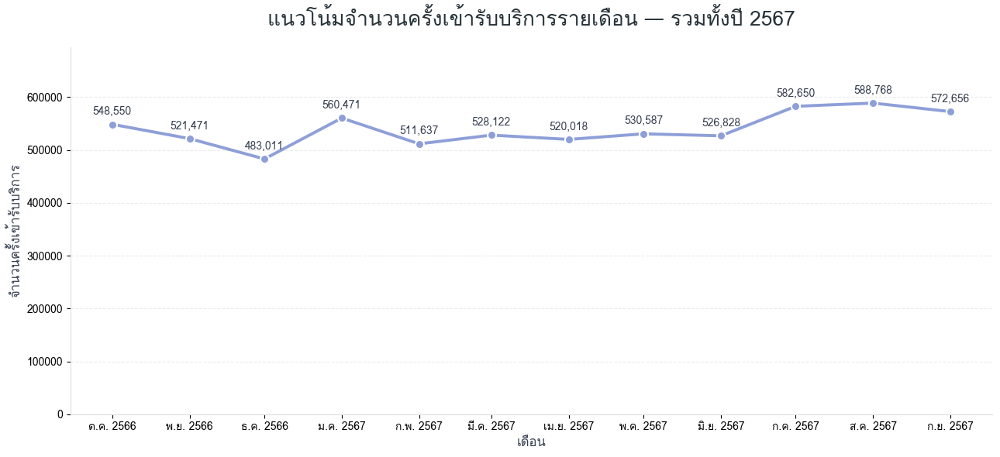

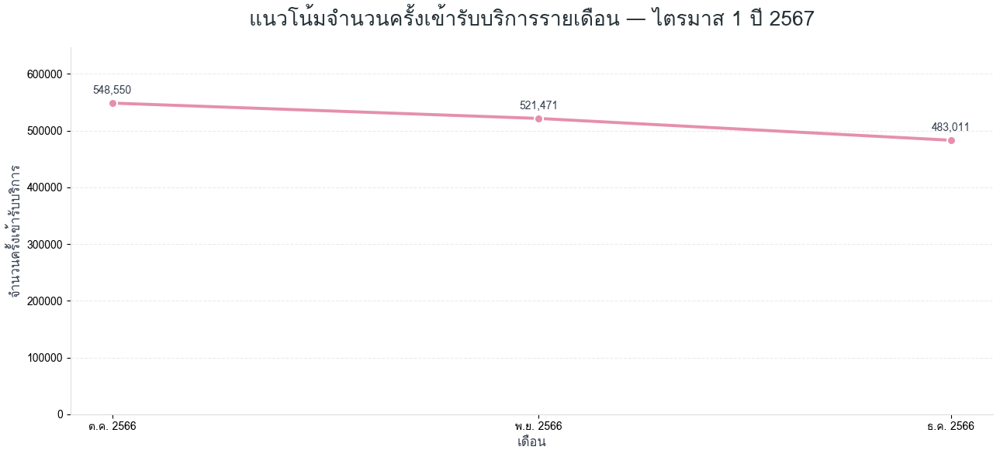

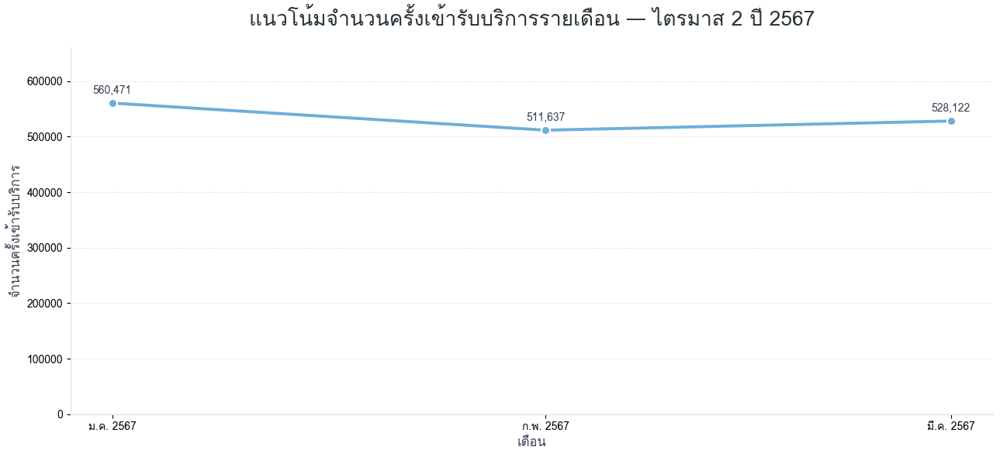

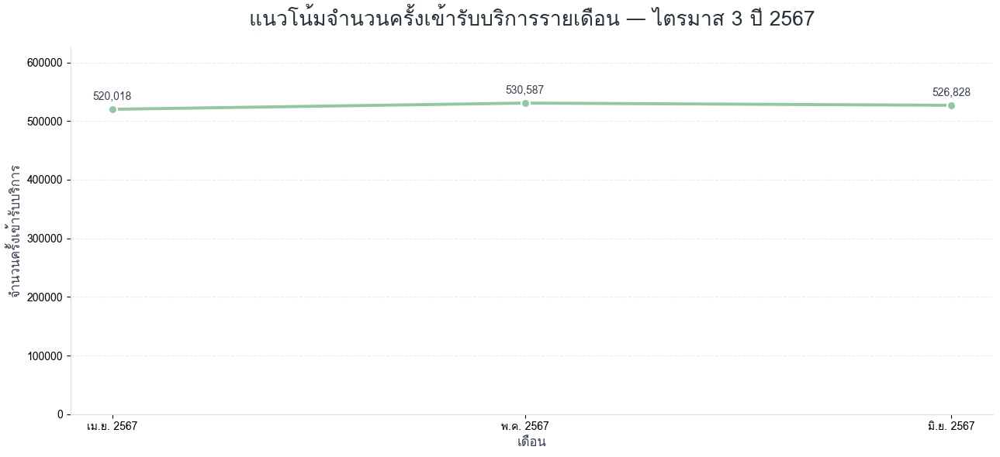

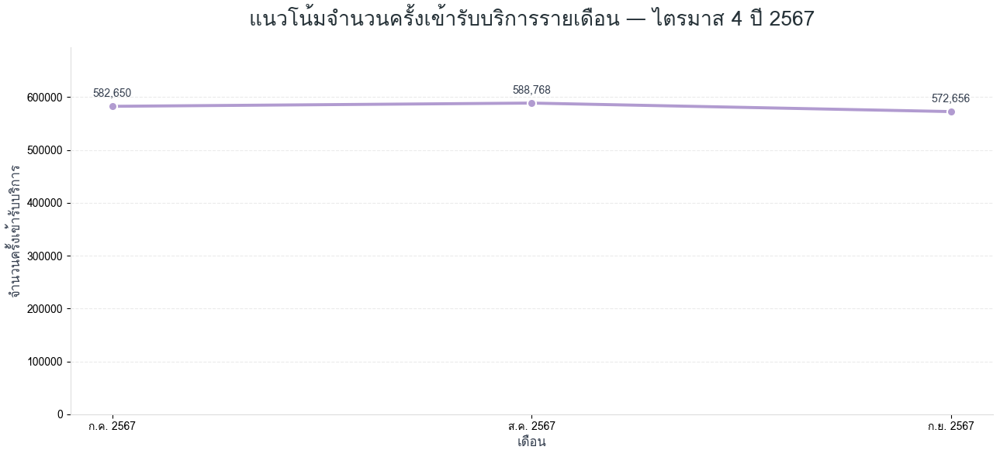

In [56]:
# ============================================================
# แนวโน้มจำนวนครั้งเข้ารับบริการรายเดือน
# รวมทั้งปี 2567 + แยกไตรมาส 1–4
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import os

# ------------------------------------------------------------
# 1) ตั้งค่าฟอนต์และสี
# ------------------------------------------------------------

mpl.rcParams["font.family"] = "Loma"
mpl.rcParams["axes.unicode_minus"] = False

line_colors = {
    "รวมทั้งปี 2567": "#8E9FD8",
    "ไตรมาส 1": "#E58FAE",
    "ไตรมาส 2": "#6FAED6",
    "ไตรมาส 3": "#91C99F",
    "ไตรมาส 4": "#B19BD0"
}

month_names = {
    1: "ม.ค.", 2: "ก.พ.", 3: "มี.ค.", 4: "เม.ย.",
    5: "พ.ค.", 6: "มิ.ย.", 7: "ก.ค.", 8: "ส.ค.",
    9: "ก.ย.", 10: "ต.ค.", 11: "พ.ย.", 12: "ธ.ค."
}

# ------------------------------------------------------------
# 2) เตรียมข้อมูล 4 ไตรมาส
# ------------------------------------------------------------

source_data = cleaned_data if "cleaned_data" in globals() else data

quarter_data = {}

for key, df in source_data.items():
    if isinstance(key, int):
        # หากคีย์เป็นตัวเลขจำนวนเต็ม
        quarter_data[f"ไตรมาส {key}"] = df.copy()
    else:
        # หากคีย์เป็นข้อความชื่อไฟล์
        name = os.path.basename(str(key)).lower()
        for q in range(1, 5):
            if f"67q{q}" in name:
                quarter_data[f"ไตรมาส {q}"] = df.copy()
                break

if not quarter_data:
    raise ValueError(
        "ไม่พบข้อมูลรายไตรมาส กรุณาตรวจสอบว่า data "
        "หรือ cleaned_data เป็น Dictionary ของ DataFrame "
        "และมีข้อมูลครบถ้วน"
    )

# รวมข้อมูลทุกไตรมาส
all_data = pd.concat(
    quarter_data.values(),
    ignore_index=True
)

# ------------------------------------------------------------
# 3) ฟังก์ชันวาดกราฟรายเดือน
# ------------------------------------------------------------

def plot_monthly_service(df, title, color):

    required = ["month_no", "n_service"]
    missing = [c for c in required if c not in df.columns]

    if missing:
        print(f"ข้าม {title}: ไม่พบคอลัมน์ {missing}")
        return

    temp = df[required].copy()

    temp["date"] = pd.to_datetime(
        temp["month_no"].astype("string").str.strip(),
        format="%Y%m",
        errors="coerce"
    )

    temp["n_service"] = pd.to_numeric(
        temp["n_service"],
        errors="coerce"
    )

    temp = temp.dropna(subset=["date", "n_service"])

    monthly_service = (
        temp.groupby("date")["n_service"]
        .sum()
        .sort_index()
    )

    if monthly_service.empty:
        print(f"ไม่มีข้อมูลรายเดือนสำหรับ {title}")
        return

    fig, ax = plt.subplots(figsize=(13, 6))

    ax.plot(
        monthly_service.index,
        monthly_service.values,
        marker="o",
        markersize=8,
        linewidth=2.8,
        color=color,
        markeredgecolor="white",
        markeredgewidth=1.5
    )

    # ใส่ตัวเลขบนจุด
    max_value = monthly_service.max()

    for x, y in zip(
        monthly_service.index,
        monthly_service.values
    ):
        ax.annotate(
            f"{y:,.0f}",
            xy=(x, y),
            xytext=(0, 9),
            textcoords="offset points",
            ha="center",
            fontsize=10,
            fontweight="bold",
            color="#374151"
        )

    # ชื่อเดือนภาษาไทยและปี พ.ศ.
    dynamic_labels = [
        f"{month_names[d.month]} {d.year + 543}"
        for d in monthly_service.index
    ]

    ax.set_xticks(monthly_service.index)
    ax.set_xticklabels(
        dynamic_labels,
        rotation=0,
        fontsize=10
    )

    ax.set_title(
        title,
        fontsize=19,
        fontweight="bold",
        color="#263238",
        pad=20
    )

    ax.set_xlabel(
        "เดือน",
        fontsize=12,
        fontweight="bold",
        color="#374151"
    )

    ax.set_ylabel(
        "จำนวนครั้งเข้ารับบริการ",
        fontsize=12,
        fontweight="bold",
        color="#374151"
    )

    ax.set_ylim(0, max_value * 1.18)

    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.25
    )

    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#DDDDDD")
    ax.spines["bottom"].set_color("#DDDDDD")

    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 4) กราฟรวมทั้งปี 2567
# ------------------------------------------------------------

plot_monthly_service(
    all_data,
    "แนวโน้มจำนวนครั้งเข้ารับบริการรายเดือน — รวมทั้งปี 2567",
    line_colors["รวมทั้งปี 2567"]
)

# ------------------------------------------------------------
# 5) กราฟแยกไตรมาส 1–4
# ------------------------------------------------------------

for quarter in sorted(
    quarter_data.keys(),
    key=lambda x: int(x.split()[-1])
):
    plot_monthly_service(
        quarter_data[quarter],
        f"แนวโน้มจำนวนครั้งเข้ารับบริการรายเดือน — {quarter} ปี 2567",
        line_colors[quarter]
    )

##**Top 5 จังหวัดที่มีจำนวนครั้งเข้ารับบริการสูงสุด**

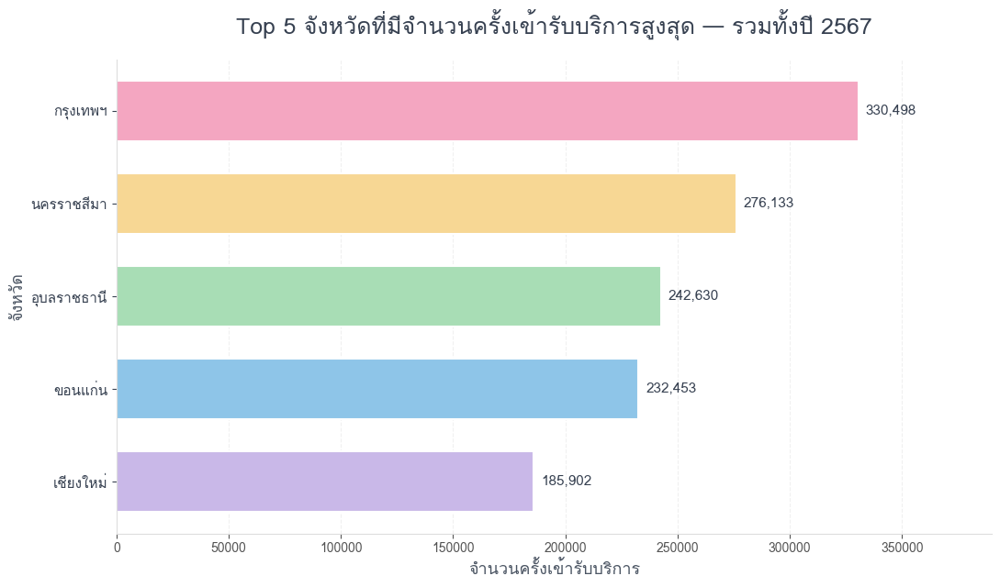

,อันดับ,จังหวัด,จำนวนครั้งเข้ารับบริการ
0,1,กรุงเทพฯ,"330,498"
1,2,นครราชสีมา,"276,133"
2,3,อุบลราชธานี,"242,630"
3,4,ขอนแก่น,"232,453"
4,5,เชียงใหม่,"185,902"


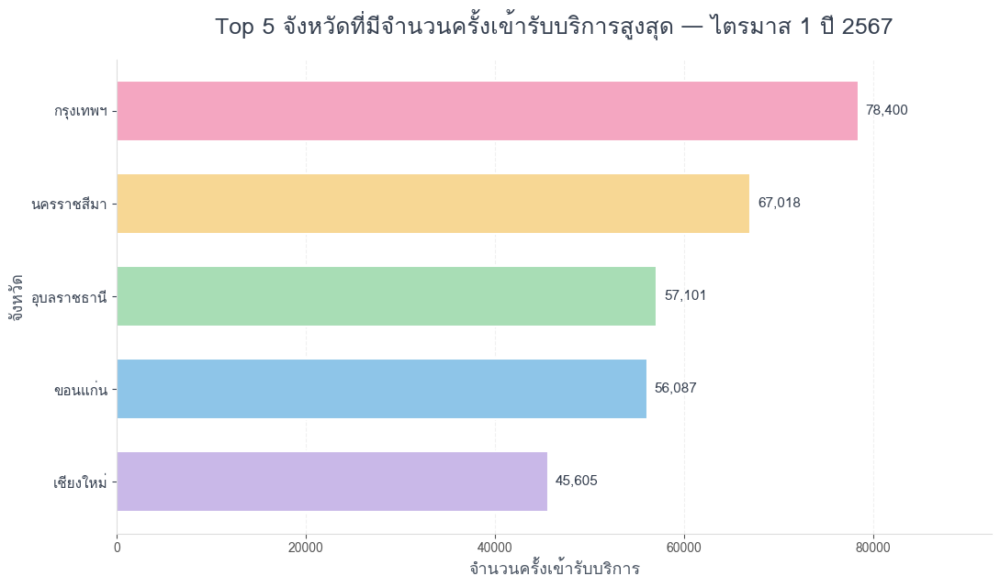

,อันดับ,จังหวัด,จำนวนครั้งเข้ารับบริการ
0,1,กรุงเทพฯ,"78,400"
1,2,นครราชสีมา,"67,018"
2,3,อุบลราชธานี,"57,101"
3,4,ขอนแก่น,"56,087"
4,5,เชียงใหม่,"45,605"


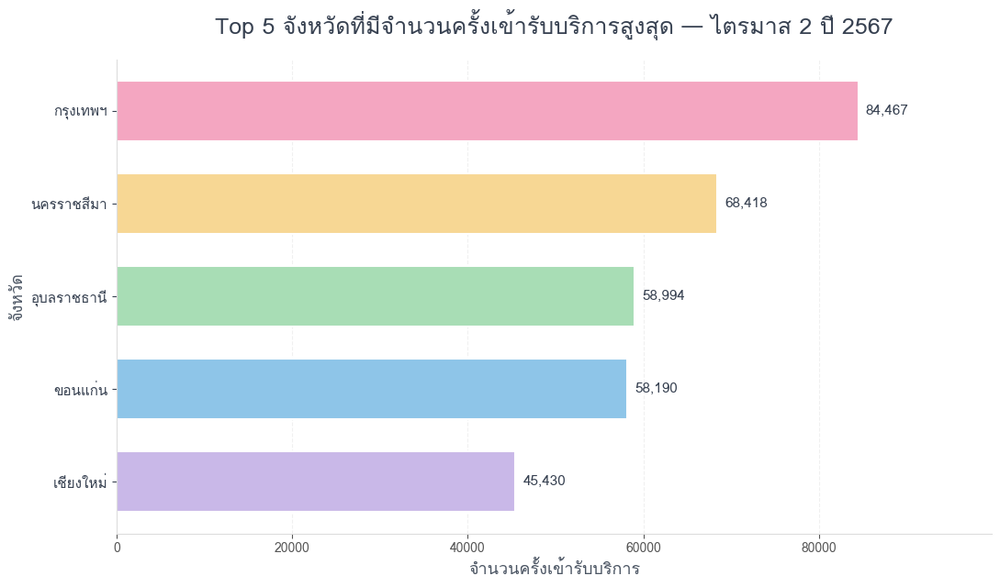

,อันดับ,จังหวัด,จำนวนครั้งเข้ารับบริการ
0,1,กรุงเทพฯ,"84,467"
1,2,นครราชสีมา,"68,418"
2,3,อุบลราชธานี,"58,994"
3,4,ขอนแก่น,"58,190"
4,5,เชียงใหม่,"45,430"


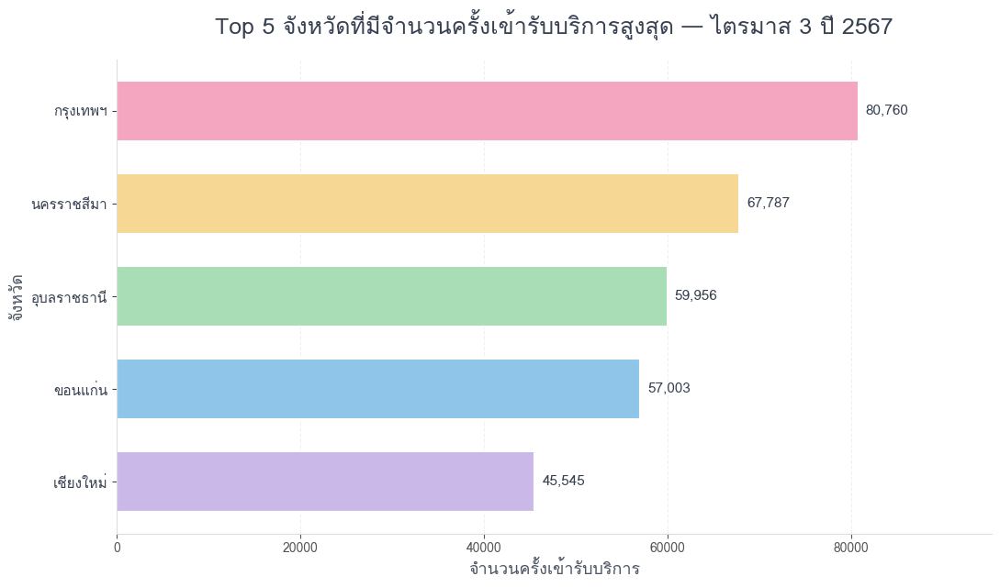

,อันดับ,จังหวัด,จำนวนครั้งเข้ารับบริการ
0,1,กรุงเทพฯ,"80,760"
1,2,นครราชสีมา,"67,787"
2,3,อุบลราชธานี,"59,956"
3,4,ขอนแก่น,"57,003"
4,5,เชียงใหม่,"45,545"


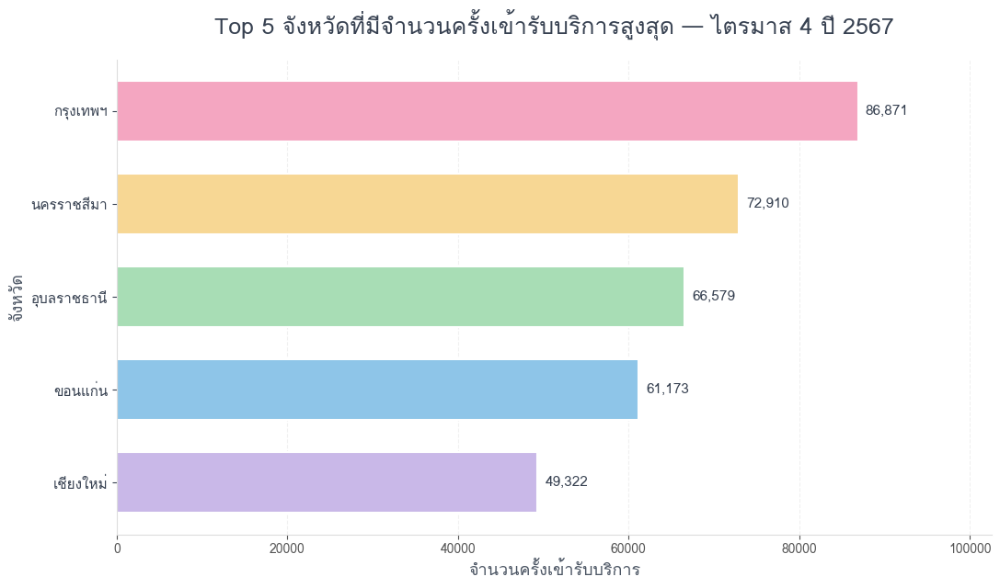

,อันดับ,จังหวัด,จำนวนครั้งเข้ารับบริการ
0,1,กรุงเทพฯ,"86,871"
1,2,นครราชสีมา,"72,910"
2,3,อุบลราชธานี,"66,579"
3,4,ขอนแก่น,"61,173"
4,5,เชียงใหม่,"49,322"


In [58]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import os

# ============================================================
# 1) ตั้งค่าฟอนต์และสี
# ============================================================

mpl.rcParams["font.family"] = "Loma"
mpl.rcParams["axes.unicode_minus"] = False

cute_colors = [
    "#C9B8E8",  # ม่วงพาสเทล
    "#8EC5E8",  # ฟ้าพาสเทล
    "#A8DDB5",  # เขียวพาสเทล
    "#F7D794",  # เหลืองพาสเทล
    "#F4A6C1"   # ชมพูพาสเทล
]

# ============================================================
# 2) เตรียมข้อมูลจากไฟล์ทั้ง 4 ไตรมาส
# ============================================================

source_data = cleaned_data if "cleaned_data" in globals() else data

quarter_data = {}

for key, df in source_data.items():
    if isinstance(key, int):
        # หากคีย์เป็นตัวเลขจำนวนเต็ม (เช่น 1, 2, 3, 4)
        quarter_data[f"ไตรมาส {key}"] = df.copy()
    else:
        # หากคีย์เป็นข้อความชื่อไฟล์
        name = os.path.basename(str(key)).lower()
        for q in range(1, 5):
            if f"67q{q}" in name:
                quarter_data[f"ไตรมาส {q}"] = df.copy()
                break

if not quarter_data:
    raise ValueError(
        "ไม่พบข้อมูลรายไตรมาส กรุณาตรวจสอบว่า data หรือ "
        "cleaned_data เป็น Dictionary ที่เก็บ DataFrame "
        "และมีข้อมูลครบถ้วน"
    )

# รวมข้อมูลทุกไตรมาส
all_data = pd.concat(
    quarter_data.values(),
    ignore_index=True
)

# ============================================================
# 3) ฟังก์ชันสร้างกราฟ Top 5 จังหวัด
# ============================================================

def plot_top5_provinces(df, title):

    required = ["prov", "n_service"]
    missing = [c for c in required if c not in df.columns]

    if missing:
        print(f"ข้าม {title}: ไม่พบคอลัมน์ {missing}")
        return

    temp = df[required].copy()

    temp["n_service"] = pd.to_numeric(
        temp["n_service"],
        errors="coerce"
    )

    temp["prov"] = temp["prov"].astype("string").str.strip()

    temp = temp.dropna(subset=["prov", "n_service"])
    temp = temp[temp["prov"] != ""]

    province_service = (
        temp.groupby("prov")["n_service"]
        .sum()
        .sort_values(ascending=False)
        .head(5)
        .sort_values()
    )

    if province_service.empty:
        print(f"ไม่มีข้อมูลจังหวัดสำหรับ {title}")
        return

    # --------------------------------------------------------
    # สร้างกราฟ
    # --------------------------------------------------------

    fig, ax = plt.subplots(figsize=(11, 6.5))

    bars = ax.barh(
        province_service.index,
        province_service.values,
        color=[
            cute_colors[i % len(cute_colors)]
            for i in range(len(province_service))
        ],
        edgecolor="white",
        linewidth=1.5,
        height=0.65
    )

    ax.set_title(
        title,
        fontsize=18,
        fontweight="bold",
        color="#374151",
        pad=20
    )

    ax.set_xlabel(
        "จำนวนครั้งเข้ารับบริการ",
        fontsize=13,
        fontweight="bold",
        color="#4B5563"
    )

    ax.set_ylabel(
        "จังหวัด",
        fontsize=13,
        fontweight="bold",
        color="#4B5563"
    )

    # --------------------------------------------------------
    # ตัวเลขปลายแท่ง
    # --------------------------------------------------------

    max_value = province_service.max()

    for bar, value in zip(bars, province_service.values):
        ax.text(
            value + max_value * 0.01,
            bar.get_y() + bar.get_height() / 2,
            f"{value:,.0f}",
            va="center",
            ha="left",
            fontsize=11,
            fontweight="bold",
            color="#374151"
        )

    # --------------------------------------------------------
    # ตกแต่งกราฟ
    # --------------------------------------------------------

    ax.tick_params(axis="x", labelsize=10, colors="#555555")
    ax.tick_params(axis="y", labelsize=11, colors="#374151")

    for label in ax.get_yticklabels():
        label.set_fontweight("bold")

    ax.grid(
        axis="x",
        linestyle="--",
        linewidth=0.8,
        alpha=0.18
    )

    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#DDDDDD")
    ax.spines["bottom"].set_color("#DDDDDD")

    ax.set_xlim(0, max_value * 1.18)

    plt.tight_layout()
    plt.show()

    # แสดงตารางตัวเลขจริงประกอบกราฟ
    result_table = province_service.sort_values(
        ascending=False
    ).reset_index()

    result_table.columns = [
        "จังหวัด",
        "จำนวนครั้งเข้ารับบริการ"
    ]

    result_table.insert(
        0, "อันดับ", range(1, len(result_table) + 1)
    )

    result_table["จำนวนครั้งเข้ารับบริการ"] = (
        result_table["จำนวนครั้งเข้ารับบริการ"]
        .map("{:,.0f}".format)
    )

    display(result_table)

# ============================================================
# 4) กราฟรวมทั้งปี 2567
# ============================================================

plot_top5_provinces(
    all_data,
    "Top 5 จังหวัดที่มีจำนวนครั้งเข้ารับบริการสูงสุด — รวมทั้งปี 2567"
)

# ============================================================
# 5) กราฟแยกไตรมาส 1–4
# ============================================================

for quarter in sorted(
    quarter_data.keys(),
    key=lambda x: int(x.split()[-1])
):
    plot_top5_provinces(
        quarter_data[quarter],
        f"Top 5 จังหวัดที่มีจำนวนครั้งเข้ารับบริการสูงสุด — {quarter} ปี 2567"
    )

##**รวมจำนวนครั้งเข้ารับบริการตามภาคและเขตสุขภาพ**


🌸 เขตสุขภาพที่มีจำนวนครั้งเข้ารับบริการสูงสุด — รวมทั้งปี 2567


อันดับ,ภูมิภาค,เขตสุขภาพที่มีจำนวนบริการสูงสุด,จำนวนครั้งเข้ารับบริการ
1,ตะวันออกเฉียงเหนือ,เขต 9 นครราชสีมา,"711,046"
2,เหนือ,เขต 1 เชียงใหม่,"643,765"
3,ใต้,เขต 12 สงขลา,"513,079"
4,ตะวันออก,เขต 6 ระยอง,"418,817"
5,กลาง,เขต 4 สระบุรี,"402,662"
6,ตะวันตก,เขต 5 ราชบุรี,"251,913"
7,กรมแพทย์ทหารเรือ,กรมแพทย์ทหาร,817
8,กรมแพทย์ทหารอากาศ,กรมแพทย์ทหาร,16


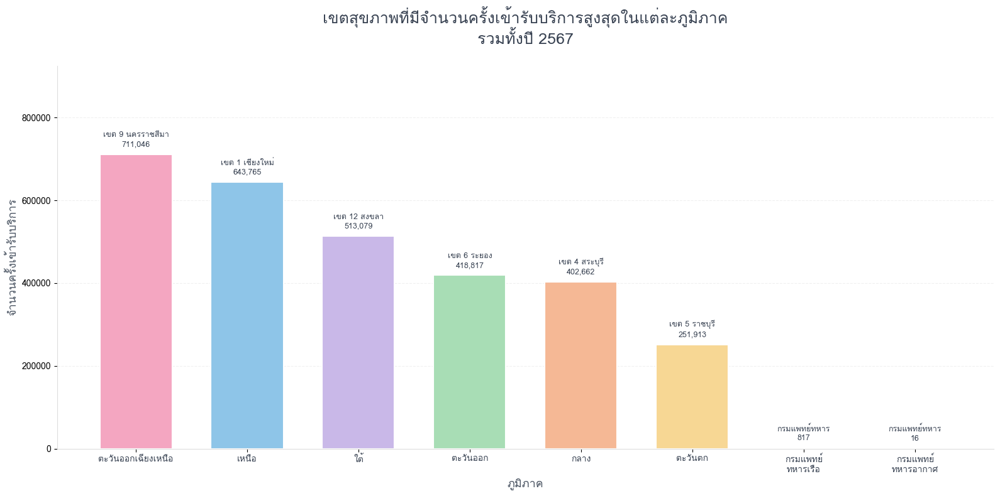

🌸 เขตสุขภาพที่มีจำนวนครั้งเข้ารับบริการสูงสุด — ไตรมาส 1 ปี 2567


อันดับ,ภูมิภาค,เขตสุขภาพที่มีจำนวนบริการสูงสุด,จำนวนครั้งเข้ารับบริการ
1,ตะวันออกเฉียงเหนือ,เขต 9 นครราชสีมา,"174,107"
2,เหนือ,เขต 1 เชียงใหม่,"158,541"
3,ใต้,เขต 12 สงขลา,"123,342"
4,ตะวันออก,เขต 6 ระยอง,"101,011"
5,กลาง,เขต 4 สระบุรี,"96,034"
6,ตะวันตก,เขต 5 ราชบุรี,"62,789"
7,กรมแพทย์ทหารเรือ,กรมแพทย์ทหาร,272
8,กรมแพทย์ทหารอากาศ,กรมแพทย์ทหาร,4


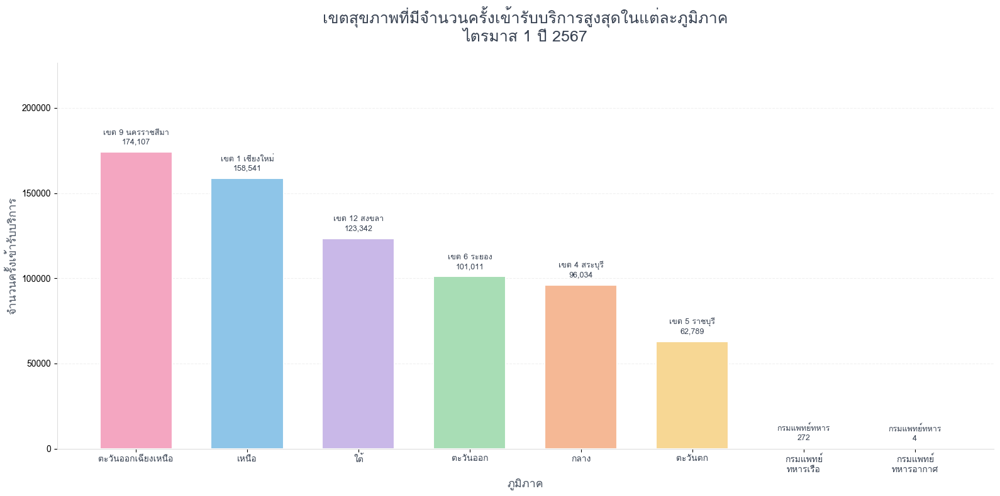

🌸 เขตสุขภาพที่มีจำนวนครั้งเข้ารับบริการสูงสุด — ไตรมาส 2 ปี 2567


อันดับ,ภูมิภาค,เขตสุขภาพที่มีจำนวนบริการสูงสุด,จำนวนครั้งเข้ารับบริการ
1,ตะวันออกเฉียงเหนือ,เขต 9 นครราชสีมา,"176,132"
2,เหนือ,เขต 1 เชียงใหม่,"158,439"
3,ใต้,เขต 12 สงขลา,"124,842"
4,ตะวันออก,เขต 6 ระยอง,"102,748"
5,กลาง,เขต 4 สระบุรี,"101,227"
6,ตะวันตก,เขต 5 ราชบุรี,"62,254"
7,กรมแพทย์ทหารเรือ,กรมแพทย์ทหาร,241
8,กรมแพทย์ทหารอากาศ,กรมแพทย์ทหาร,3


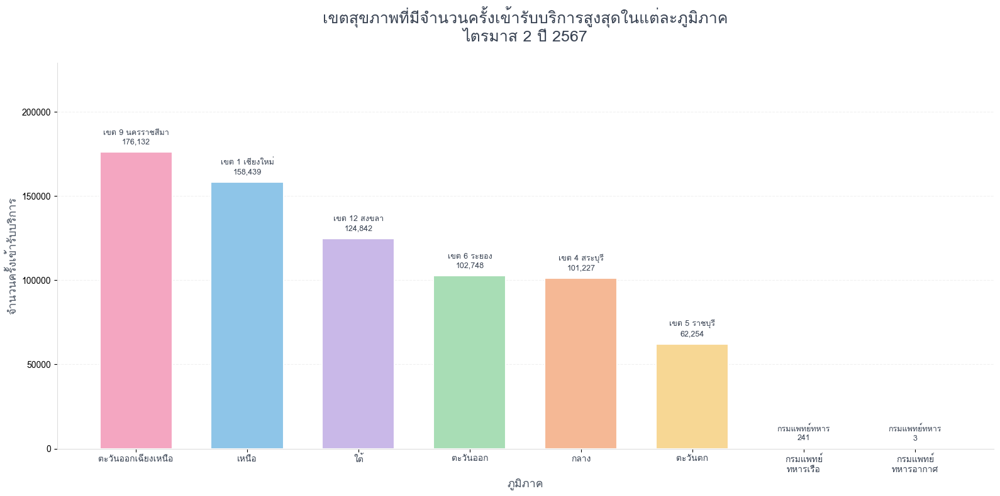

🌸 เขตสุขภาพที่มีจำนวนครั้งเข้ารับบริการสูงสุด — ไตรมาส 3 ปี 2567


อันดับ,ภูมิภาค,เขตสุขภาพที่มีจำนวนบริการสูงสุด,จำนวนครั้งเข้ารับบริการ
1,ตะวันออกเฉียงเหนือ,เขต 9 นครราชสีมา,"171,594"
2,เหนือ,เขต 1 เชียงใหม่,"158,767"
3,ใต้,เขต 12 สงขลา,"120,344"
4,ตะวันออก,เขต 6 ระยอง,"103,467"
5,กลาง,เขต 4 สระบุรี,"97,118"
6,ตะวันตก,เขต 5 ราชบุรี,"59,701"
7,กรมแพทย์ทหารเรือ,กรมแพทย์ทหาร,121
8,กรมแพทย์ทหารอากาศ,กรมแพทย์ทหาร,3


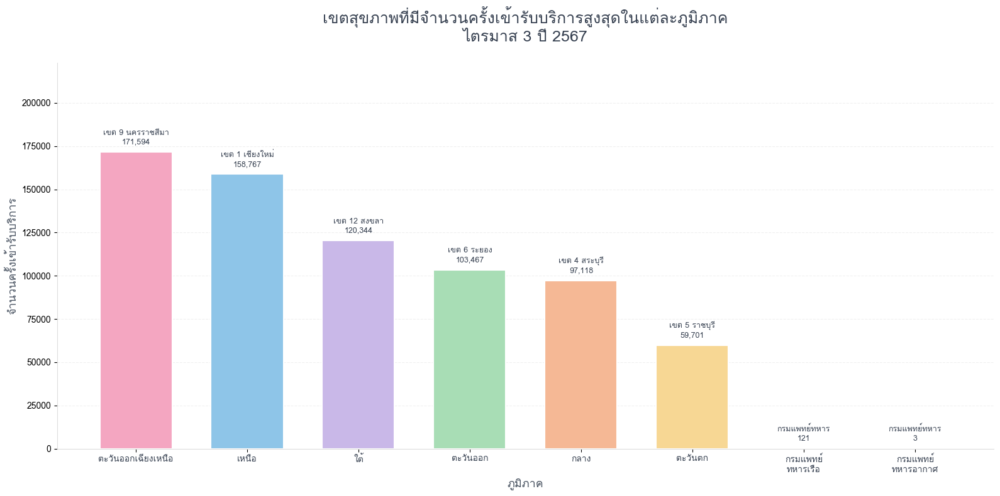

🌸 เขตสุขภาพที่มีจำนวนครั้งเข้ารับบริการสูงสุด — ไตรมาส 4 ปี 2567


อันดับ,ภูมิภาค,เขตสุขภาพที่มีจำนวนบริการสูงสุด,จำนวนครั้งเข้ารับบริการ
1,ตะวันออกเฉียงเหนือ,เขต 9 นครราชสีมา,"189,213"
2,เหนือ,เขต 1 เชียงใหม่,"168,018"
3,ใต้,เขต 12 สงขลา,"144,551"
4,ตะวันออก,เขต 6 ระยอง,"111,591"
5,กลาง,เขต 4 สระบุรี,"108,283"
6,ตะวันตก,เขต 5 ราชบุรี,"67,169"
7,กรมแพทย์ทหารเรือ,กรมแพทย์ทหาร,183
8,กรมแพทย์ทหารอากาศ,กรมแพทย์ทหาร,6


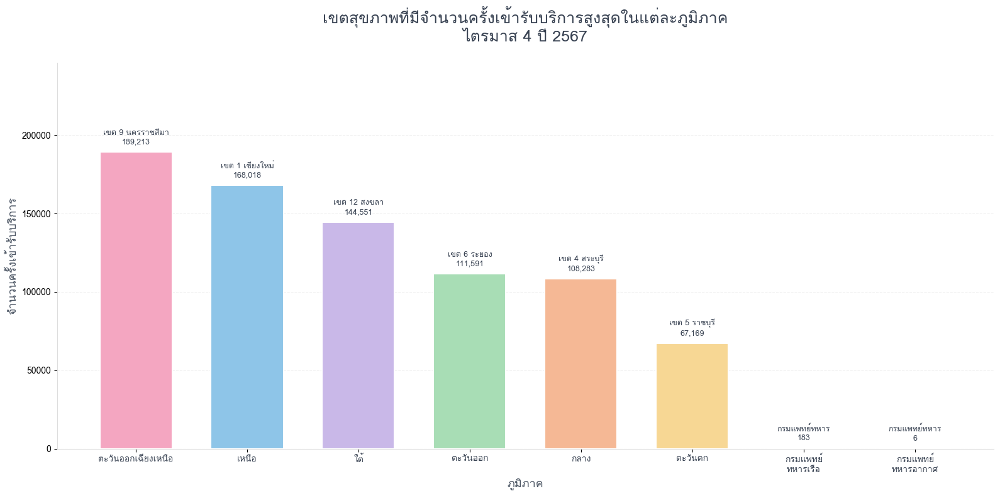

In [62]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import os
from IPython.display import display

# ============================================================
# 1) ตั้งค่าฟอนต์และสี
# ============================================================

mpl.rcParams["font.family"] = "Loma"
mpl.rcParams["axes.unicode_minus"] = False

cute_colors = [
    "#F4A6C1", "#8EC5E8", "#C9B8E8", "#A8DDB5",
    "#F5B895", "#F7D794", "#D9A7C7", "#A8C8E8"
]

# ============================================================
# 2) เตรียมข้อมูลจากทั้ง 4 ไตรมาส
# ============================================================

source_data = cleaned_data if "cleaned_data" in globals() else data

quarter_data = {}

for key, df in source_data.items():
    if isinstance(key, int):
        # หากคีย์เป็นตัวเลขจำนวนเต็ม (เช่น 1, 2, 3, 4)
        quarter_data[f"ไตรมาส {key}"] = df.copy()
    else:
        # หากคีย์เป็นข้อความชื่อไฟล์
        name = os.path.basename(str(key)).lower()
        for q in range(1, 5):
            if f"67q{q}" in name:
                quarter_data[f"ไตรมาส {q}"] = df.copy()
                break

if not quarter_data:
    raise ValueError(
        "ไม่พบข้อมูลรายไตรมาส กรุณาตรวจสอบว่า data หรือ "
        "cleaned_data เป็น Dictionary ของ DataFrame "
        "และมีข้อมูลครบถ้วน"
    )

all_data = pd.concat(
    quarter_data.values(),
    ignore_index=True
)

# ============================================================
# 3) ฟังก์ชันจัดรูปแบบชื่อ
# ============================================================

def format_region_name(name):
    if pd.isna(name):
        return "ไม่ระบุ"

    name = str(name)

    if name == "กรมแพทย์ทหารอากาศ":
        return "กรมแพทย์\nทหารอากาศ"
    elif name == "กรมแพทย์ทหารเรือ":
        return "กรมแพทย์\nทหารเรือ"
    elif len(name) > 12:
        return name.replace(" ", "\n")

    return name


def format_zone_name(name):
    if pd.isna(name):
        return "ไม่ระบุ"

    name = str(name)

    if name == "กรมแพทย์ทหารอากาศ":
        return "กรมแพทย์\nทหารอากาศ"
    elif name == "กรมแพทย์ทหารเรือ":
        return "กรมแพทย์\nทหารเรือ"

    return name


# ============================================================
# 4) ฟังก์ชันสร้างตารางและกราฟ
# ============================================================

def plot_top_zone_by_region(df, period_title):

    required = ["ภาค", "nhso_zonename", "n_service"]
    missing = [c for c in required if c not in df.columns]

    if missing:
        print(
            f"ข้าม {period_title}: ไม่พบคอลัมน์ {missing} "
            "กรุณาตรวจสอบว่าข้อมูลมีคอลัมน์ภาคแล้ว"
        )
        return

    temp = df[required].copy()

    temp["n_service"] = pd.to_numeric(
        temp["n_service"],
        errors="coerce"
    )

    temp = temp.dropna(
        subset=["ภาค", "nhso_zonename", "n_service"]
    )

    # รวมจำนวนบริการตามภาคและเขตสุขภาพ
    region_zone = (
        temp.groupby(["ภาค", "nhso_zonename"])[u"n_service"]
        .sum()
        .reset_index()
    )

    # เลือกเขตสุขภาพที่มีบริการสูงสุดในแต่ละภาค
    top_zone_region = (
        region_zone
        .sort_values(
            ["ภาค", "n_service"],
            ascending=[True, False]
        )
        .groupby("ภาค", sort=False)
        .head(1)
        .reset_index(drop=True)
    )

    # เรียงภาคตามจำนวนบริการของเขตที่ชนะในแต่ละภาค
    top_zone_region = (
        top_zone_region
        .sort_values("n_service", ascending=False)
        .reset_index(drop=True)
    )

    if top_zone_region.empty:
        print(f"ไม่มีข้อมูลสำหรับ {period_title}")
        return

    # --------------------------------------------------------
    # ตารางสรุป
    # --------------------------------------------------------

    table_data = top_zone_region.copy()
    table_data.insert(0, "อันดับ", range(1, len(table_data) + 1))

    table_data = table_data[
        ["อันดับ", "ภาค", "nhso_zonename", "n_service"]
    ]

    table_data.columns = [
        "อันดับ",
        "ภูมิภาค",
        "เขตสุขภาพที่มีจำนวนบริการสูงสุด",
        "จำนวนครั้งเข้ารับบริการ"
    ]

    table_data["จำนวนครั้งเข้ารับบริการ"] = (
        table_data["จำนวนครั้งเข้ารับบริการ"]
        .map("{:,.0f}".format)
    )

    print(f"🌸 เขตสุขภาพที่มีจำนวนครั้งเข้ารับบริการสูงสุด — {period_title}")

    display(
        table_data.style
        .hide(axis="index")
        .set_caption(
            f"เขตสุขภาพที่มีจำนวนครั้งเข้ารับบริการสูงสุดในแต่ละภูมิภาค ({period_title})"
        )
        .set_properties(**{
            "font-size": "13px",
            "text-align": "center",
            "border": "1px solid #E5E7EB"
        })
        .set_table_styles([
            {
                "selector": "caption",
                "props": [
                    ("caption-side", "top"),
                    ("font-size", "16px"),
                    ("font-weight", "bold"),
                    ("color", "#374151"),
                    ("padding", "10px")
                ]
            },
            {
                "selector": "th",
                "props": [
                    ("background-color", "#DCEAF7"),
                    ("color", "#374151"),
                    ("font-weight", "bold"),
                    ("text-align", "center"),
                    ("padding", "10px")
                ]
            },
            {
                "selector": "td",
                "props": [
                    ("padding", "9px"),
                    ("text-align", "center")
                ]
            }
        ])
    )

    # --------------------------------------------------------
    # กราฟแท่ง
    # --------------------------------------------------------

    x_labels = [
        format_region_name(x)
        for x in top_zone_region["ภาค"]
    ]

    fig, ax = plt.subplots(
        figsize=(max(12, len(top_zone_region) * 2.0), 8)
    )

    bars = ax.bar(
        range(len(top_zone_region)),
        top_zone_region["n_service"],
        color=[
            cute_colors[i % len(cute_colors)]
            for i in range(len(top_zone_region))
        ],
        edgecolor="white",
        linewidth=1.5,
        width=0.65
    )

    ax.set_title(
        f"เขตสุขภาพที่มีจำนวนครั้งเข้ารับบริการสูงสุดในแต่ละภูมิภาค\n{period_title}",
        fontsize=18,
        fontweight="bold",
        color="#374151",
        pad=25
    )

    ax.set_xlabel(
        "ภูมิภาค",
        fontsize=13,
        fontweight="bold",
        color="#4B5563"
    )

    ax.set_ylabel(
        "จำนวนครั้งเข้ารับบริการ",
        fontsize=13,
        fontweight="bold",
        color="#4B5563"
    )

    ax.set_xticks(range(len(top_zone_region)))
    ax.set_xticklabels(
        x_labels,
        fontsize=10,
        fontweight="bold",
        color="#374151"
    )

    max_value = top_zone_region["n_service"].max()

    for bar, zone, value in zip(
        bars,
        top_zone_region["nhso_zonename"],
        top_zone_region["n_service"]
    ):
        ax.annotate(
            f"{format_zone_name(zone)}\n{value:,.0f}",
            xy=(bar.get_x() + bar.get_width() / 2, value),
            xytext=(0, 7),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=9,
            fontweight="bold",
            color="#374151",
            linespacing=1.3
        )

    ax.grid(
        axis="y",
        linestyle="--",
        linewidth=0.8,
        alpha=0.18
    )

    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#DDDDDD")
    ax.spines["bottom"].set_color("#DDDDDD")

    ax.set_ylim(0, max_value * 1.3)

    plt.tight_layout()
    plt.show()


# ============================================================
# 5) รวมทั้งปี 2567
# ============================================================

plot_top_zone_by_region(
    all_data,
    "รวมทั้งปี 2567"
)

# ============================================================
# 6) แยกไตรมาส 1–4
# ============================================================

for quarter in sorted(
    quarter_data.keys(),
    key=lambda x: int(x.split()[-1])
):
    plot_top_zone_by_region(
        quarter_data[quarter],
        f"{quarter} ปี 2567"
    )

##**Top 5 กลุ่มโรคที่มีจำนวนครั้งเข้ารับบริการสูงสุดในแต่ละฤดู**


🌸 Top 5 กลุ่มโรคในแต่ละฤดู — รวมทั้งปี 2567


ฤดู,อันดับ,กลุ่มโรค,จำนวนครั้งเข้ารับบริการ
ฤดูร้อน,1,Diarrhoea and gastroenteritis of presumed infectious origin,"80,061"
ฤดูร้อน,2,Pneumonia organism unspecified,"55,276"
ฤดูร้อน,3,Senile cataract,"51,282"
ฤดูร้อน,4,Non-insulin-dependent diabetes mellitus,"38,210"
ฤดูร้อน,5,Other chronic obstructive pulmonary disease,"34,032"
ฤดูฝน,1,Diarrhoea and gastroenteritis of presumed infectious origin,"134,927"
ฤดูฝน,2,Pneumonia organism unspecified,"112,150"
ฤดูฝน,3,Senile cataract,"87,126"
ฤดูฝน,4,Non-insulin-dependent diabetes mellitus,"60,952"
ฤดูฝน,5,Acute bronchitis,"58,340"


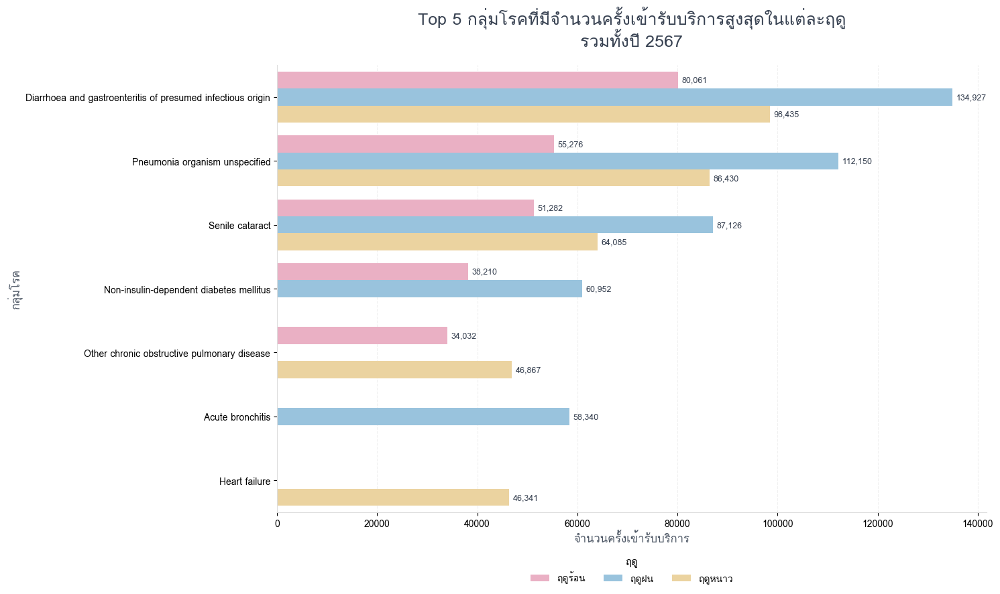


🌸 Top 5 กลุ่มโรคในแต่ละฤดู — ไตรมาส 1 ปี 2567


ฤดู,อันดับ,กลุ่มโรค,จำนวนครั้งเข้ารับบริการ
ฤดูฝน,1,Pneumonia organism unspecified,"24,562"
ฤดูฝน,2,Diarrhoea and gastroenteritis of presumed infectious origin,"19,647"
ฤดูฝน,3,Senile cataract,"16,418"
ฤดูฝน,4,Other chronic obstructive pulmonary disease,"12,212"
ฤดูฝน,5,Acute bronchitis,"11,775"
ฤดูหนาว,1,Diarrhoea and gastroenteritis of presumed infectious origin,"41,670"
ฤดูหนาว,2,Pneumonia organism unspecified,"40,201"
ฤดูหนาว,3,Senile cataract,"28,880"
ฤดูหนาว,4,Heart failure,"22,053"
ฤดูหนาว,5,Other chronic obstructive pulmonary disease,"21,567"


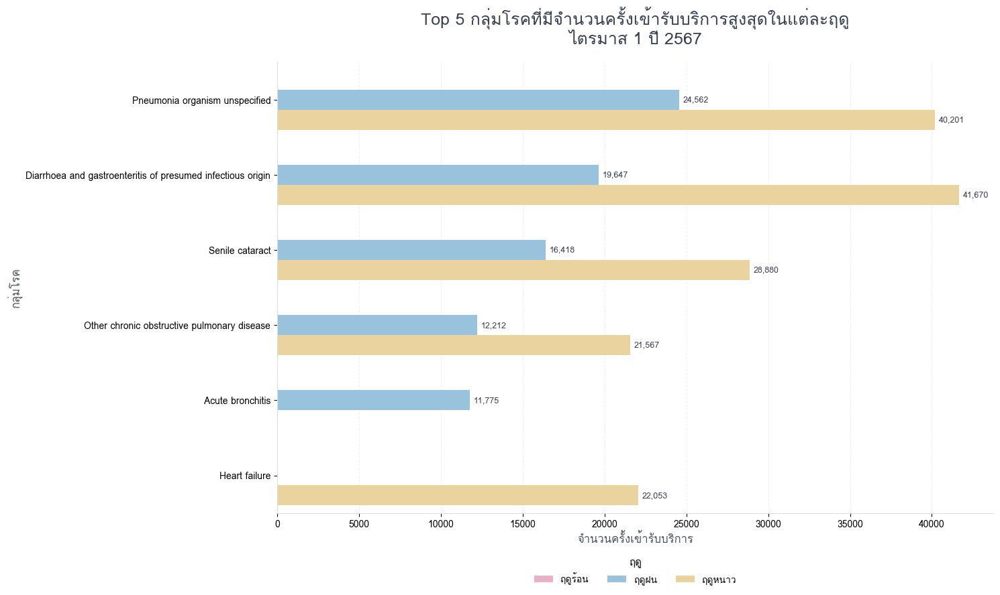


🌸 Top 5 กลุ่มโรคในแต่ละฤดู — ไตรมาส 2 ปี 2567


ฤดู,อันดับ,กลุ่มโรค,จำนวนครั้งเข้ารับบริการ
ฤดูร้อน,1,Diarrhoea and gastroenteritis of presumed infectious origin,"23,705"
ฤดูร้อน,2,Pneumonia organism unspecified,"21,230"
ฤดูร้อน,3,Senile cataract,"19,108"
ฤดูร้อน,4,Other chronic obstructive pulmonary disease,"12,307"
ฤดูร้อน,5,Non-insulin-dependent diabetes mellitus,"11,923"
ฤดูหนาว,1,Diarrhoea and gastroenteritis of presumed infectious origin,"56,765"
ฤดูหนาว,2,Pneumonia organism unspecified,"46,229"
ฤดูหนาว,3,Senile cataract,"35,205"
ฤดูหนาว,4,Other chronic obstructive pulmonary disease,"25,300"
ฤดูหนาว,5,Heart failure,"24,288"


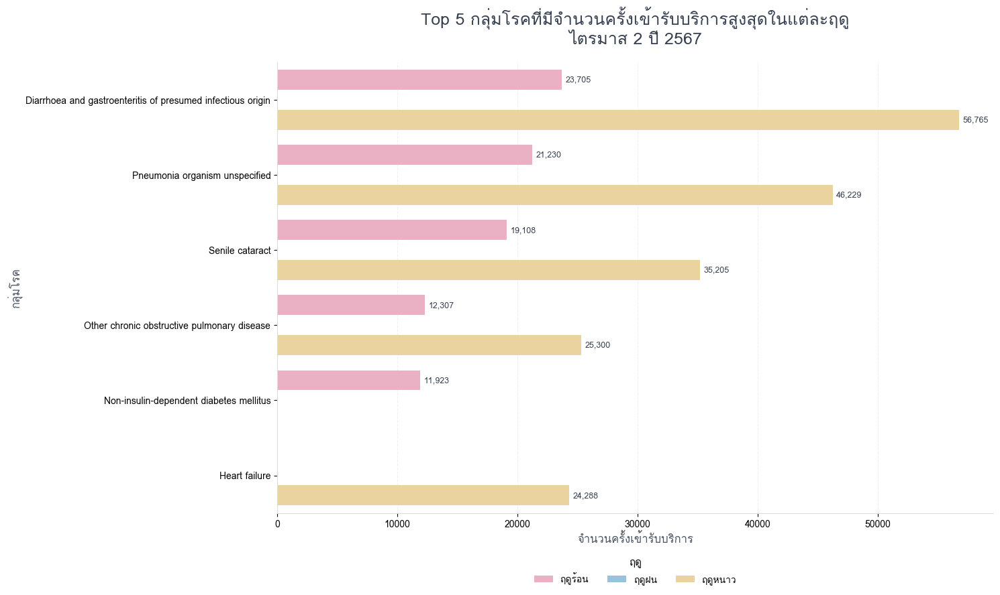


🌸 Top 5 กลุ่มโรคในแต่ละฤดู — ไตรมาส 3 ปี 2567


ฤดู,อันดับ,กลุ่มโรค,จำนวนครั้งเข้ารับบริการ
ฤดูร้อน,1,Diarrhoea and gastroenteritis of presumed infectious origin,"56,356"
ฤดูร้อน,2,Pneumonia organism unspecified,"34,046"
ฤดูร้อน,3,Senile cataract,"32,174"
ฤดูร้อน,4,Non-insulin-dependent diabetes mellitus,"26,287"
ฤดูร้อน,5,Thalassaemia,"22,779"
ฤดูฝน,1,Diarrhoea and gastroenteritis of presumed infectious origin,"28,574"
ฤดูฝน,2,Senile cataract,"17,419"
ฤดูฝน,3,Pneumonia organism unspecified,"16,360"
ฤดูฝน,4,Non-insulin-dependent diabetes mellitus,"12,201"
ฤดูฝน,5,Chronic renal failure,"10,880"


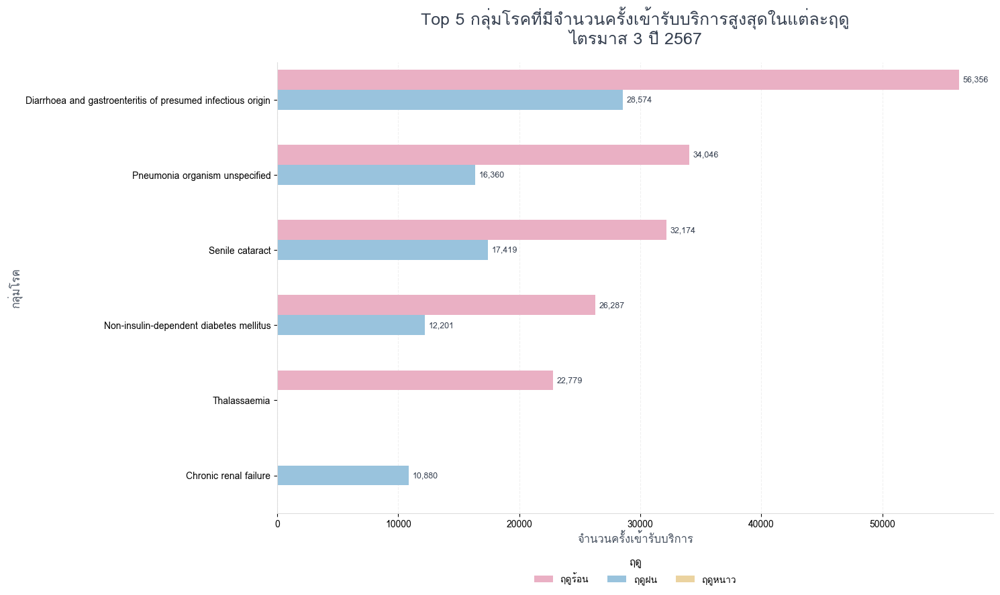


🌸 Top 5 กลุ่มโรคในแต่ละฤดู — ไตรมาส 4 ปี 2567


ฤดู,อันดับ,กลุ่มโรค,จำนวนครั้งเข้ารับบริการ
ฤดูฝน,1,Diarrhoea and gastroenteritis of presumed infectious origin,"86,706"
ฤดูฝน,2,Pneumonia organism unspecified,"71,228"
ฤดูฝน,3,Senile cataract,"53,289"
ฤดูฝน,4,Acute bronchitis,"38,455"
ฤดูฝน,5,Non-insulin-dependent diabetes mellitus,"38,355"


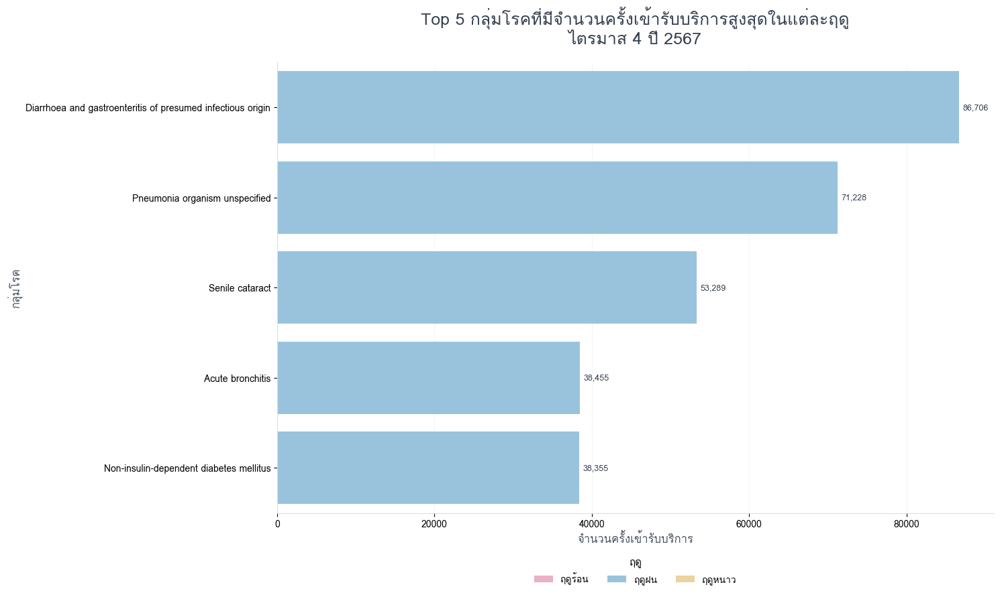

In [64]:
# ============================================================
# TOP 5 กลุ่มโรคตามฤดู
# รวมทั้งปี 2567 + แยกไตรมาส 1–4
# ตาราง + Grouped Bar Chart
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
import os
from IPython.display import display

# ============================================================
# 1) ตั้งค่าฟอนต์และสี
# ============================================================

mpl.rcParams["font.family"] = "Loma"
mpl.rcParams["axes.unicode_minus"] = False

season_order = ["ฤดูร้อน", "ฤดูฝน", "ฤดูหนาว"]

season_colors = {
    "ฤดูร้อน": "#F4A6C1",
    "ฤดูฝน": "#8EC5E8",
    "ฤดูหนาว": "#F7D794"
}

month_names = {
    1: "ม.ค.", 2: "ก.พ.", 3: "มี.ค.", 4: "เม.ย.",
    5: "พ.ค.", 6: "มิ.ย.", 7: "ก.ค.", 8: "ส.ค.",
    9: "ก.ย.", 10: "ต.ค.", 11: "พ.ย.", 12: "ธ.ค."
}

# ============================================================
# 2) เตรียมข้อมูลจากทั้ง 4 ไตรมาส
# ============================================================

source_data = cleaned_data if "cleaned_data" in globals() else data

quarter_data = {}

for key, df in source_data.items():
    if isinstance(key, int):
        quarter_data[f"ไตรมาส {key}"] = df.copy()
    else:
        name = os.path.basename(str(key)).lower()
        for q in range(1, 5):
            if f"67q{q}" in name:
                quarter_data[f"ไตรมาส {q}"] = df.copy()
                break

if not quarter_data:
    raise ValueError(
        "ไม่พบข้อมูลรายไตรมาส กรุณาตรวจสอบว่า data หรือ "
        "cleaned_data เป็น Dictionary ของ DataFrame "
        "และมีข้อมูลครบถ้วน"
    )

all_data = pd.concat(
    quarter_data.values(),
    ignore_index=True
)

# ============================================================
# 3) ฟังก์ชันแบ่งฤดู
# ============================================================

def get_season(month):
    if month in [3, 4, 5]:
        return "ฤดูร้อน"
    elif month in [6, 7, 8, 9, 10]:
        return "ฤดูฝน"
    elif month in [11, 12, 1, 2]:
        return "ฤดูหนาว"
    return None

# ============================================================
# 4) ฟังก์ชันวิเคราะห์และวาดกราฟ
# ============================================================

def plot_top5_season_disease(df, period_title):

    required = ["month_no", "pdx_name", "n_service"]
    missing = [c for c in required if c not in df.columns]

    if missing:
        print(f"ข้าม {period_title}: ไม่พบคอลัมน์ {missing}")
        return

    temp = df[required].copy()

    # แปลงข้อมูลเดือน
    temp["date"] = pd.to_datetime(
        temp["month_no"].astype("string").str.strip(),
        format="%Y%m",
        errors="coerce"
    )

    temp["month"] = temp["date"].dt.month
    temp["season"] = temp["month"].apply(get_season)

    temp["n_service"] = pd.to_numeric(
        temp["n_service"],
        errors="coerce"
    )

    temp["pdx_name"] = (
        temp["pdx_name"].astype("string").str.strip()
    )

    temp = temp.dropna(
        subset=["season", "pdx_name", "n_service"]
    )

    temp = temp[
        (temp["pdx_name"] != "") &
        (temp["pdx_name"].str.lower() != "nan")
    ]

    # รวมจำนวนบริการตามฤดูและกลุ่มโรค
    season_disease = (
        temp.groupby(["season", "pdx_name"])["n_service"]
        .sum()
        .reset_index()
    )

    # เลือก Top 5 ของแต่ละฤดู
    top5_season = (
        season_disease
        .sort_values("n_service", ascending=False)
        .groupby("season", sort=False)
        .head(5)
        .copy()
    )

    if top5_season.empty:
        print(f"ไม่มีข้อมูลสำหรับ {period_title}")
        return

    top5_season["season"] = pd.Categorical(
        top5_season["season"],
        categories=season_order,
        ordered=True
    )

    top5_season = top5_season.sort_values(
        ["season", "n_service"],
        ascending=[True, False]
    )

    # --------------------------------------------------------
    # ตาราง Top 5
    # --------------------------------------------------------

    table_data = top5_season.copy()

    table_data["อันดับ"] = (
        table_data.groupby("season", observed=True)
        .cumcount() + 1
    )

    table_data = table_data[
        ["season", "อันดับ", "pdx_name", "n_service"]
    ]

    table_data.columns = [
        "ฤดู",
        "อันดับ",
        "กลุ่มโรค",
        "จำนวนครั้งเข้ารับบริการ"
    ]

    table_data["จำนวนครั้งเข้ารับบริการ"] = (
        table_data["จำนวนครั้งเข้ารับบริการ"]
        .map("{:,.0f}".format)
    )

    print(f"\n🌸 Top 5 กลุ่มโรคในแต่ละฤดู — {period_title}")

    display(
        table_data.style
        .hide(axis="index")
        .set_caption(
            f"Top 5 กลุ่มโรคจำแนกตามฤดู ({period_title})"
        )
        .set_properties(**{
            "font-size": "13px",
            "text-align": "center",
            "border": "1px solid #E5E7EB"
        })
        .set_table_styles([
            {
                "selector": "caption",
                "props": [
                    ("caption-side", "top"),
                    ("font-size", "17px"),
                    ("font-weight", "bold"),
                    ("color", "#374151"),
                    ("padding", "10px")
                ]
            },
            {
                "selector": "th",
                "props": [
                    ("background-color", "#F3DDE6"),
                    ("color", "#374151"),
                    ("font-weight", "bold"),
                    ("text-align", "center"),
                    ("padding", "10px")
                ]
            },
            {
                "selector": "td",
                "props": [
                    ("padding", "8px"),
                    ("text-align", "center")
                ]
            },
            {
                "selector": "tbody tr:nth-child(even)",
                "props": [("background-color", "#FFF8FA")]
            },
            {
                "selector": "tbody tr:nth-child(odd)",
                "props": [("background-color", "#FFFFFF")]
            }
        ])
    )

    # --------------------------------------------------------
    # กราฟแท่งเปรียบเทียบ Top 5 ในแต่ละฤดู
    # --------------------------------------------------------

    fig, ax = plt.subplots(figsize=(15, 9))

    sns.barplot(
        data=top5_season,
        x="n_service",
        y="pdx_name",
        hue="season",
        hue_order=season_order,
        palette=season_colors,
        ax=ax
    )

    ax.set_title(
        f"Top 5 กลุ่มโรคที่มีจำนวนครั้งเข้ารับบริการสูงสุดในแต่ละฤดู\n{period_title}",
        fontsize=18,
        fontweight="bold",
        color="#374151",
        pad=20
    )

    ax.set_xlabel(
        "จำนวนครั้งเข้ารับบริการ",
        fontsize=12,
        fontweight="bold",
        color="#4B5563"
    )

    ax.set_ylabel(
        "กลุ่มโรค",
        fontsize=12,
        fontweight="bold",
        color="#4B5563"
    )

    # ตัวเลขปลายแท่ง
    for container in ax.containers:
        labels = [
            f"{bar.get_width():,.0f}" if bar.get_width() > 0 else ""
            for bar in container
        ]

        ax.bar_label(
            container,
            labels=labels,
            padding=4,
            fontsize=9,
            fontweight="bold",
            color="#374151"
        )

    ax.legend(
        title="ฤดู",
        title_fontsize=11,
        fontsize=10,
        loc="upper center",
        bbox_to_anchor=(0.5, -0.08),
        ncol=3,
        frameon=False
    )

    ax.xaxis.grid(
        True,
        linestyle="--",
        linewidth=0.8,
        alpha=0.18
    )

    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#DDDDDD")
    ax.spines["bottom"].set_color("#DDDDDD")

    plt.tight_layout()
    plt.show()


# ============================================================
# 5) วิเคราะห์รวมทั้งปี 2567
# ============================================================

plot_top5_season_disease(
    all_data,
    "รวมทั้งปี 2567"
)

# ============================================================
# 6) วิเคราะห์แยกไตรมาส 1–4
# ============================================================

for quarter in sorted(
    quarter_data.keys(),
    key=lambda x: int(x.split()[-1])
):
    plot_top5_season_disease(
        quarter_data[quarter],
        f"{quarter} ปี 2567"
    )


##**แนวโน้มจำนวนครั้งเข้ารับบริการจำแนกตามภูมิภาค**

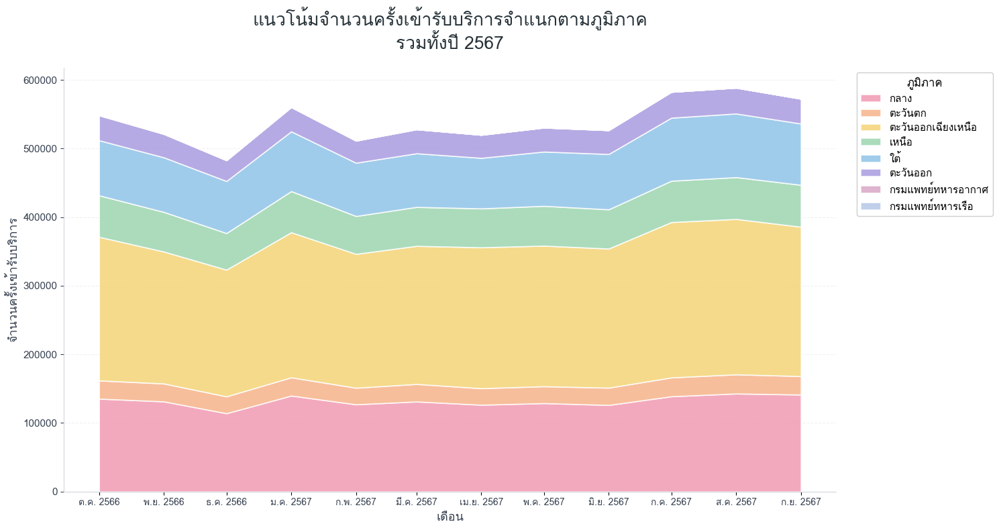

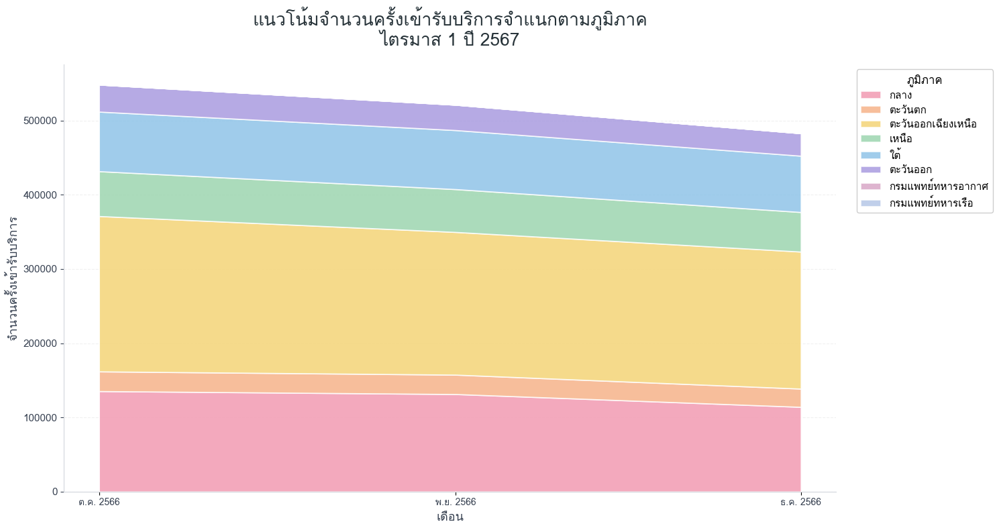

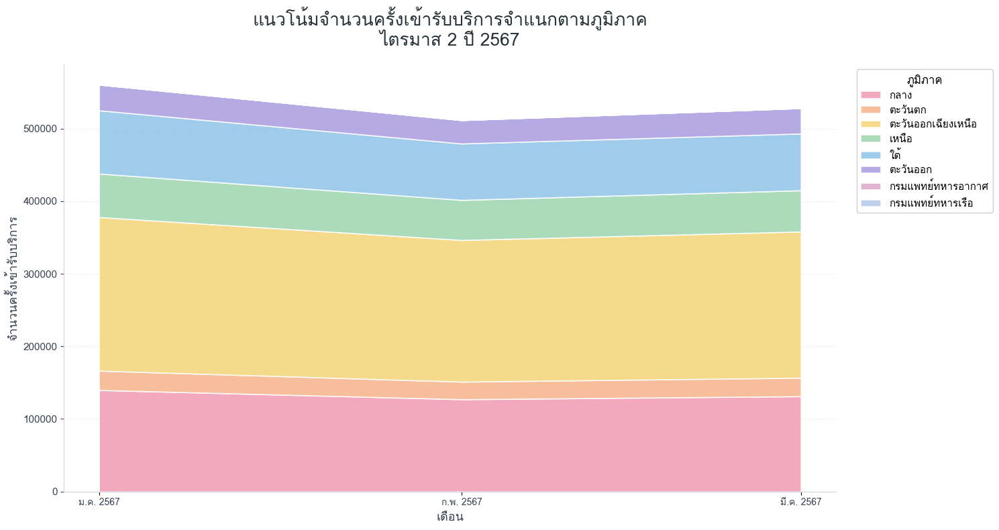

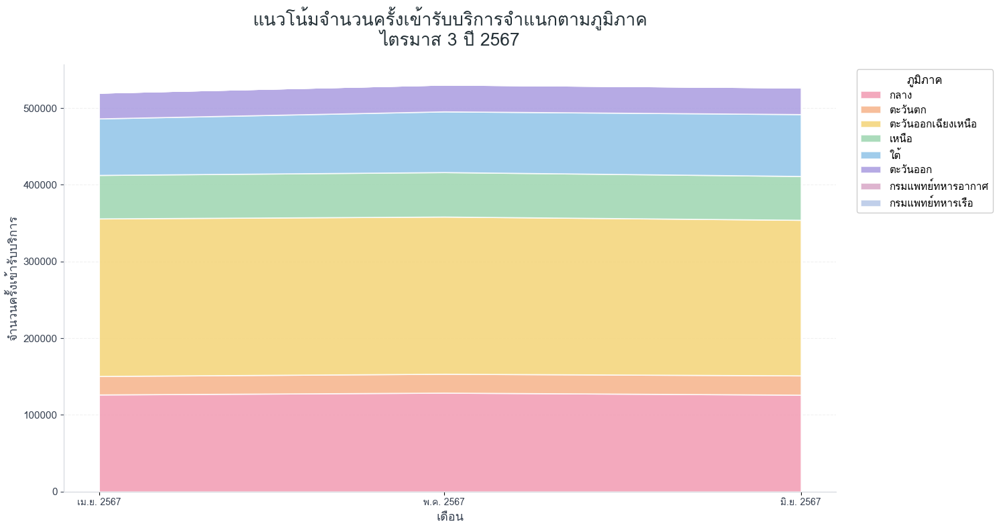

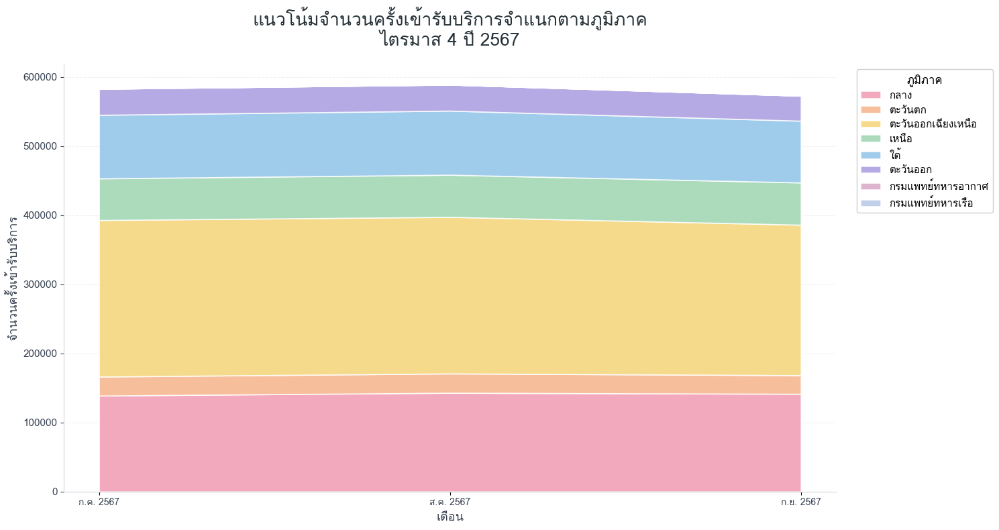

In [68]:
# ============================================================
# Stacked Area Chart
# แนวโน้มจำนวนครั้งเข้ารับบริการตามภูมิภาค
# รวมทั้งปี 2567 + แยกไตรมาส 1–4
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import os

# ============================================================
# 1) ตั้งค่าฟอนต์และสี
# ============================================================

mpl.rcParams["font.family"] = "Loma"
mpl.rcParams["axes.unicode_minus"] = False

region_colors = {
    "กลาง": "#F29AB2",
    "ตะวันตก": "#F6B38A",
    "ตะวันออกเฉียงเหนือ": "#F4D477",
    "เหนือ": "#9DD5B0",
    "ใต้": "#8FC4E8",
    "ตะวันออก": "#A99BE0"
}

region_order_default = [
    "กลาง",
    "ตะวันตก",
    "ตะวันออกเฉียงเหนือ",
    "เหนือ",
    "ใต้",
    "ตะวันออก"
]

month_names = {
    1: "ม.ค.", 2: "ก.พ.", 3: "มี.ค.", 4: "เม.ย.",
    5: "พ.ค.", 6: "มิ.ย.", 7: "ก.ค.", 8: "ส.ค.",
    9: "ก.ย.", 10: "ต.ค.", 11: "พ.ย.", 12: "ธ.ค."
}

# ============================================================
# 2) เตรียมข้อมูลจาก 4 ไตรมาส
# ============================================================

source_data = cleaned_data if "cleaned_data" in globals() else data

quarter_data = {}

for key, df in source_data.items():
    if isinstance(key, int):
        # หากคีย์เป็นตัวเลขจำนวนเต็ม
        quarter_data[f"ไตรมาส {key}"] = df.copy()
    else:
        # หากคีย์เป็นข้อความ
        name = os.path.basename(str(key)).lower()
        for q in range(1, 5):
            if f"67q{q}" in name:
                quarter_data[f"ไตรมาส {q}"] = df.copy()
                break

if not quarter_data:
    raise ValueError(
        "ไม่พบข้อมูลรายไตรมาส กรุณาตรวจสอบว่า data หรือ "
        "cleaned_data เป็น Dictionary ของ DataFrame "
        "และมีข้อมูลครบถ้วน"
    )

all_data = pd.concat(
    quarter_data.values(),
    ignore_index=True
)

# ============================================================
# 3) ฟังก์ชันสร้างกราฟ
# ============================================================

def plot_region_area(df, title):
    required = ["month_no", "ภาค", "n_service"]
    missing = [c for c in required if c not in df.columns]

    if missing:
        print(f"ข้าม {title}: ไม่พบคอลัมน์ {missing}")
        return

    temp = df[required].copy()

    # แปลงเดือนเป็นวันที่จริง
    temp["date"] = pd.to_datetime(
        temp["month_no"].astype("string").str.strip(),
        format="%Y%m",
        errors="coerce"
    )

    temp["n_service"] = pd.to_numeric(
        temp["n_service"],
        errors="coerce"
    )

    temp["ภาค"] = temp["ภาค"].astype("string").str.strip()

    temp = temp.dropna(
        subset=["date", "ภาค", "n_service"]
    )

    # รวมจำนวนบริการตามเดือนและภูมิภาค
    region_month = (
        temp.groupby(["date", "ภาค"])["n_service"]
        .sum()
        .unstack(fill_value=0)
        .sort_index()
    )

    if region_month.empty:
        print(f"ไม่มีข้อมูลสำหรับ {title}")
        return

    # เรียงภูมิภาคตามลำดับที่กำหนด
    region_order = [
        region for region in region_order_default
        if region in region_month.columns
    ]

    # รองรับชื่อภูมิภาคอื่นที่มีอยู่จริงในข้อมูล
    other_regions = [
        region for region in region_month.columns
        if region not in region_order
    ]

    region_order += sorted(other_regions)
    region_month = region_month[region_order]

    # สีสำรองสำหรับภูมิภาคอื่นที่มีอยู่จริง
    fallback_colors = [
        "#D9A7C7", "#B5C7E7", "#C4D8A8",
        "#F3C4A8", "#B8D9D3", "#D6C5E8"
    ]

    colors = [
        region_colors.get(
            region,
            fallback_colors[i % len(fallback_colors)]
        )
        for i, region in enumerate(region_order)
    ]

    # --------------------------------------------------------
    # วาดกราฟ
    # --------------------------------------------------------

    fig, ax = plt.subplots(figsize=(15, 8))

    ax.stackplot(
        region_month.index,
        *[
            region_month[region].values
            for region in region_order
        ],
        labels=region_order,
        colors=colors,
        alpha=0.85,
        edgecolor="white",
        linewidth=1.2
    )

    ax.set_title(
        f"แนวโน้มจำนวนครั้งเข้ารับบริการจำแนกตามภูมิภาค\n{title}",
        fontsize=19,
        fontweight="bold",
        color="#263238",
        pad=20
    )

    ax.set_xlabel(
        "เดือน",
        fontsize=13,
        fontweight="bold",
        color="#374151"
    )

    ax.set_ylabel(
        "จำนวนครั้งเข้ารับบริการ",
        fontsize=13,
        fontweight="bold",
        color="#374151"
    )

    # ชื่อเดือนภาษาไทยและปี พ.ศ. จากข้อมูลจริง
    ax.set_xticks(region_month.index)
    ax.set_xticklabels(
        [
            f"{month_names[d.month]} {d.year + 543}"
            for d in region_month.index
        ],
        fontsize=10,
        fontweight="bold",
        color="#374151",
        rotation=0
    )

    ax.legend(
        title="ภูมิภาค",
        title_fontsize=12,
        fontsize=11,
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        frameon=True,
        fancybox=True,
        framealpha=0.95
    )

    ax.grid(
        axis="y",
        linestyle="--",
        linewidth=0.8,
        alpha=0.18
    )

    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#D1D5DB")
    ax.spines["bottom"].set_color("#D1D5DB")

    ax.tick_params(
        axis="y",
        labelsize=11,
        colors="#374151"
    )

    plt.tight_layout()
    plt.show()

# ============================================================
# 4) กราฟรวมทั้งปี 2567
# ============================================================

plot_region_area(
    all_data,
    "รวมทั้งปี 2567"
)

# ============================================================
# 5) กราฟแยกไตรมาส 1–4
# ============================================================

for quarter in sorted(
    quarter_data.keys(),
    key=lambda x: int(x.split()[-1])
):
    plot_region_area(
        quarter_data[quarter],
        f"{quarter} ปี 2567"
    )

##**Top 5 โรคที่มีจำนวนครั้งเข้ารับบริการสูงสุด จำแนกตามเดือน**


🌸 รวมทุกไตรมาส ปี 2567


เดือน,อันดับ,กลุ่มโรค,จำนวนครั้งเข้ารับบริการ
ต.ค. 2566,1,Pneumonia organism unspecified,"24,562"
ต.ค. 2566,2,Diarrhoea and gastroenteritis of presumed infectious origin,"19,647"
ต.ค. 2566,3,Senile cataract,"16,418"
ต.ค. 2566,4,Other chronic obstructive pulmonary disease,"12,212"
ต.ค. 2566,5,Acute bronchitis,"11,775"
พ.ย. 2566,1,Pneumonia organism unspecified,"20,091"
พ.ย. 2566,2,Diarrhoea and gastroenteritis of presumed infectious origin,"18,900"
พ.ย. 2566,3,Senile cataract,"15,947"
พ.ย. 2566,4,Chronic renal failure,"11,059"
พ.ย. 2566,5,Thalassaemia,"10,671"


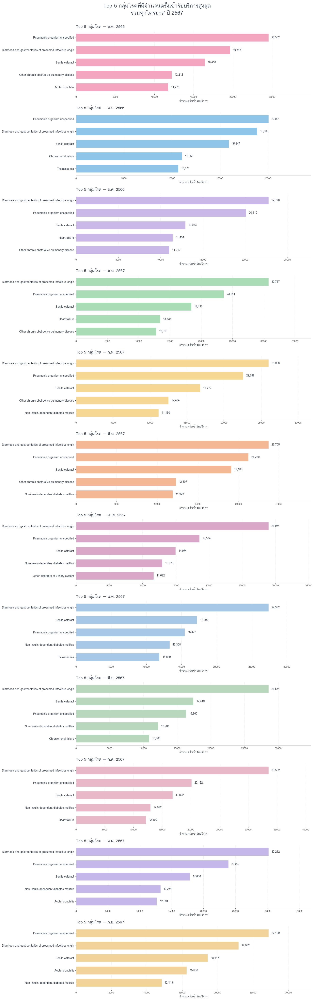


🌸 ไตรมาส 1 ปี 2567


เดือน,อันดับ,กลุ่มโรค,จำนวนครั้งเข้ารับบริการ
ต.ค. 2566,1,Pneumonia organism unspecified,"24,562"
ต.ค. 2566,2,Diarrhoea and gastroenteritis of presumed infectious origin,"19,647"
ต.ค. 2566,3,Senile cataract,"16,418"
ต.ค. 2566,4,Other chronic obstructive pulmonary disease,"12,212"
ต.ค. 2566,5,Acute bronchitis,"11,775"
พ.ย. 2566,1,Pneumonia organism unspecified,"20,091"
พ.ย. 2566,2,Diarrhoea and gastroenteritis of presumed infectious origin,"18,900"
พ.ย. 2566,3,Senile cataract,"15,947"
พ.ย. 2566,4,Chronic renal failure,"11,059"
พ.ย. 2566,5,Thalassaemia,"10,671"


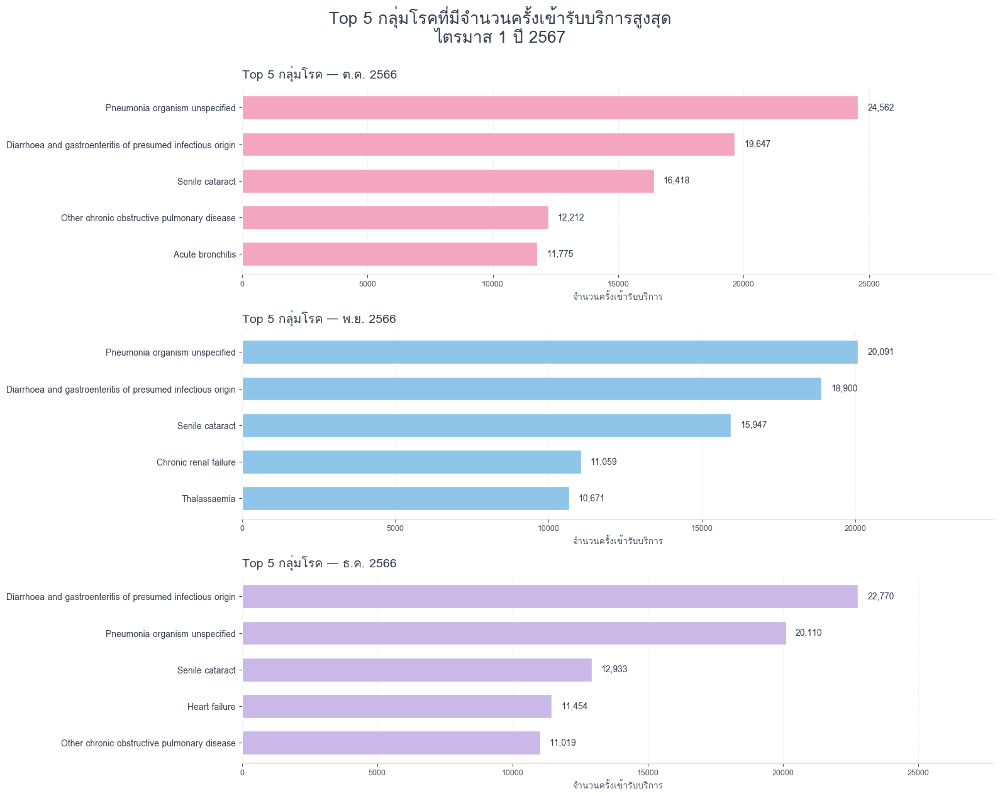


🌸 ไตรมาส 2 ปี 2567


เดือน,อันดับ,กลุ่มโรค,จำนวนครั้งเข้ารับบริการ
ม.ค. 2567,1,Diarrhoea and gastroenteritis of presumed infectious origin,"30,767"
ม.ค. 2567,2,Pneumonia organism unspecified,"23,641"
ม.ค. 2567,3,Senile cataract,"18,433"
ม.ค. 2567,4,Heart failure,"13,435"
ม.ค. 2567,5,Other chronic obstructive pulmonary disease,"12,816"
ก.พ. 2567,1,Diarrhoea and gastroenteritis of presumed infectious origin,"25,998"
ก.พ. 2567,2,Pneumonia organism unspecified,"22,588"
ก.พ. 2567,3,Senile cataract,"16,772"
ก.พ. 2567,4,Other chronic obstructive pulmonary disease,"12,484"
ก.พ. 2567,5,Non-insulin-dependent diabetes mellitus,"11,160"


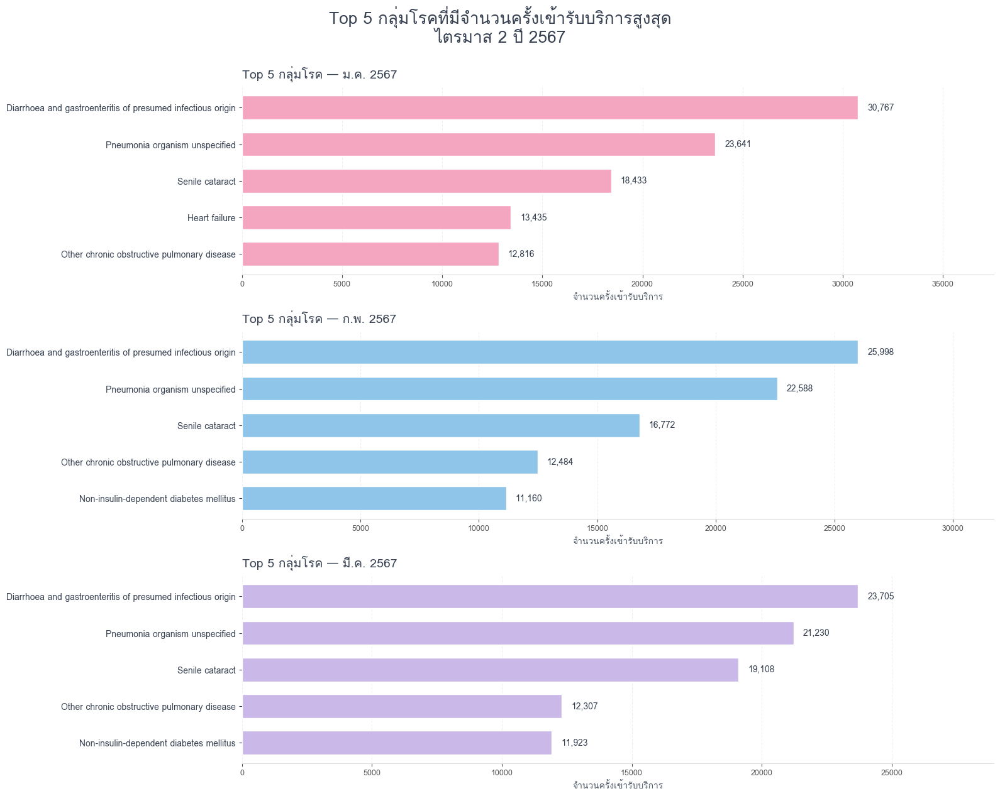


🌸 ไตรมาส 3 ปี 2567


เดือน,อันดับ,กลุ่มโรค,จำนวนครั้งเข้ารับบริการ
เม.ย. 2567,1,Diarrhoea and gastroenteritis of presumed infectious origin,"28,974"
เม.ย. 2567,2,Pneumonia organism unspecified,"18,574"
เม.ย. 2567,3,Senile cataract,"14,974"
เม.ย. 2567,4,Non-insulin-dependent diabetes mellitus,"12,979"
เม.ย. 2567,5,Other disorders of urinary system,"11,682"
พ.ค. 2567,1,Diarrhoea and gastroenteritis of presumed infectious origin,"27,382"
พ.ค. 2567,2,Senile cataract,"17,200"
พ.ค. 2567,3,Pneumonia organism unspecified,"15,472"
พ.ค. 2567,4,Non-insulin-dependent diabetes mellitus,"13,308"
พ.ค. 2567,5,Thalassaemia,"11,869"


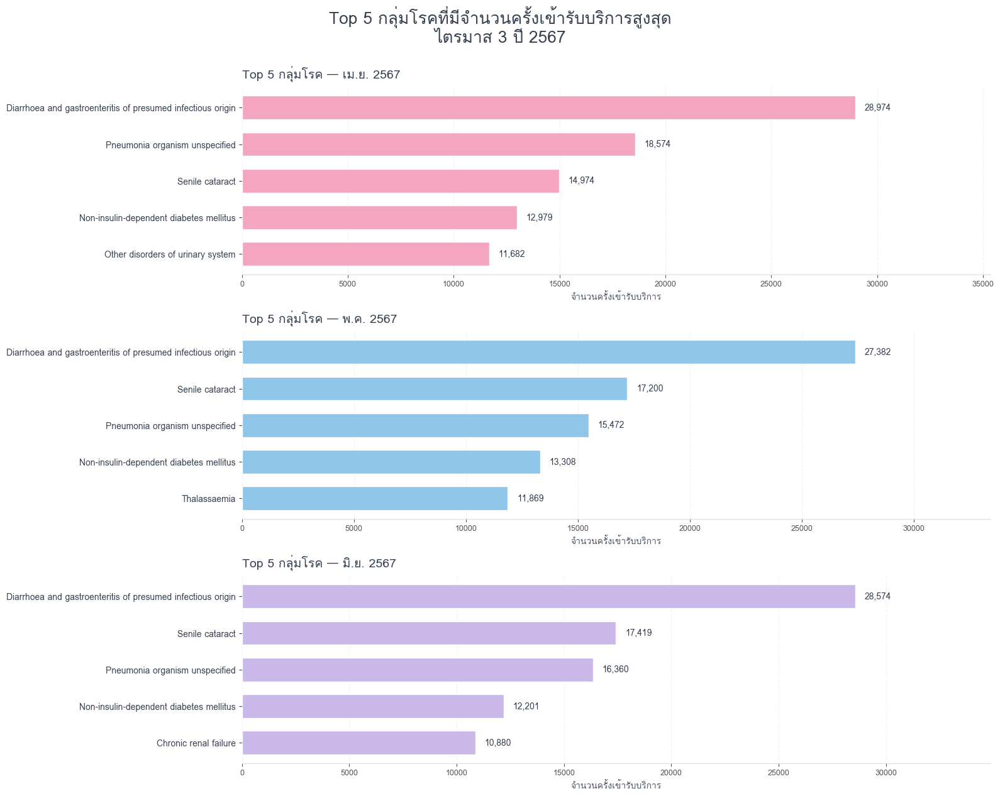


🌸 ไตรมาส 4 ปี 2567


เดือน,อันดับ,กลุ่มโรค,จำนวนครั้งเข้ารับบริการ
ก.ค. 2567,1,Diarrhoea and gastroenteritis of presumed infectious origin,"33,532"
ก.ค. 2567,2,Pneumonia organism unspecified,"20,122"
ก.ค. 2567,3,Senile cataract,"16,822"
ก.ค. 2567,4,Non-insulin-dependent diabetes mellitus,"12,982"
ก.ค. 2567,5,Heart failure,"12,190"
ส.ค. 2567,1,Diarrhoea and gastroenteritis of presumed infectious origin,"30,212"
ส.ค. 2567,2,Pneumonia organism unspecified,"23,907"
ส.ค. 2567,3,Senile cataract,"17,850"
ส.ค. 2567,4,Non-insulin-dependent diabetes mellitus,"13,254"
ส.ค. 2567,5,Acute bronchitis,"12,694"


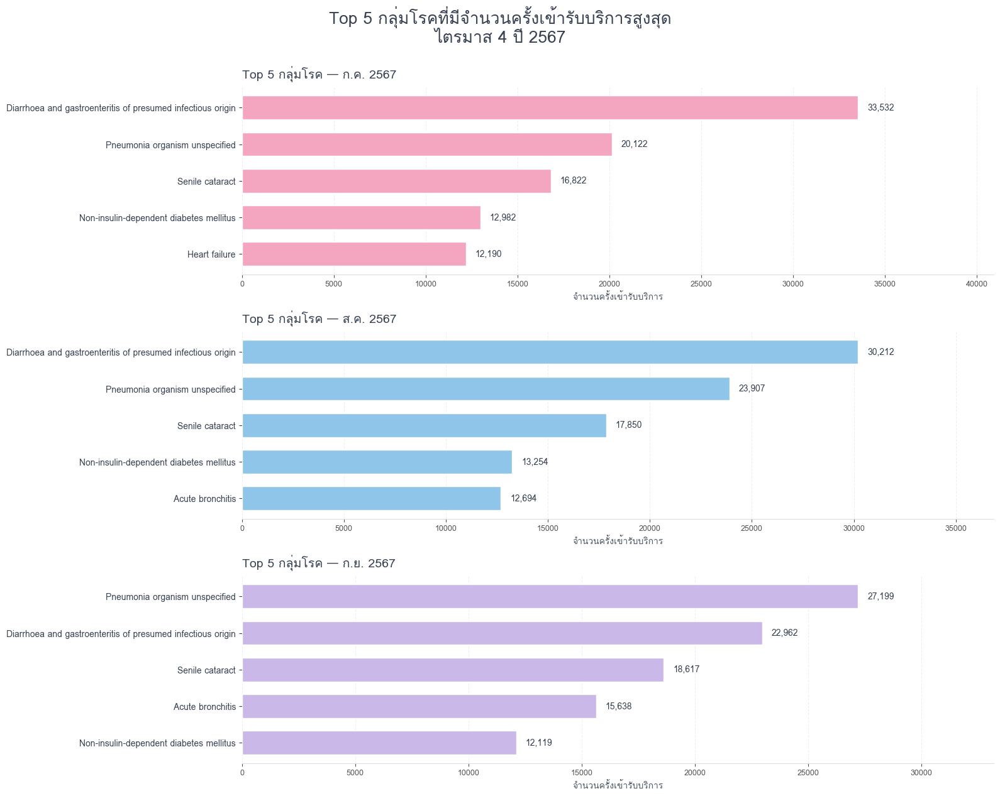

In [74]:

def plot_top5_month(df, title):
    required = ["month_no", "pdx_name", "n_service"]
    missing = [col for col in required if col not in df.columns]

    if missing:
        print(f"ข้าม {title}: ไม่พบคอลัมน์ {missing}")
        return

    temp = df[required].copy()

    temp["date"] = pd.to_datetime(
        temp["month_no"].astype(str).str.replace(
            r"\.0$", "", regex=True
        ),
        format="%Y%m",
        errors="coerce"
    )

    temp["n_service"] = pd.to_numeric(
        temp["n_service"], errors="coerce"
    )
    temp["pdx_name"] = temp["pdx_name"].astype("string").str.strip()

    temp = temp.dropna(subset=["date", "pdx_name", "n_service"])
    temp = temp[temp["pdx_name"] != ""]

    if temp.empty:
        print(f"ไม่มีข้อมูลสำหรับ {title}")
        return

    temp["month_start"] = (
        temp["date"].dt.to_period("M").dt.to_timestamp()
    )

    # รวมจำนวนบริการรายเดือนและกลุ่มโรค
    month_disease = (
        temp.groupby(
            ["month_start", "pdx_name"],
            as_index=False
        )["n_service"].sum()
    )

    # Top 5 ของแต่ละเดือน
    top5_month = (
        month_disease
        .sort_values(
            ["month_start", "n_service"],
            ascending=[True, False]
        )
        .groupby("month_start", sort=False)
        .head(5)
        .copy()
    )

    top5_month["month_name"] = top5_month["month_start"].apply(
        lambda d: f"{month_names[d.month]} {d.year + 543}"
    )

    month_order = [
        f"{month_names[d.month]} {d.year + 543}"
        for d in sorted(top5_month["month_start"].unique())
    ]

    # เรียงชื่อโรคตามจำนวนบริการรวม เพื่อให้แกน Y อ่านง่าย
    disease_order = (
        top5_month.groupby("pdx_name")["n_service"]
        .sum()
        .sort_values(ascending=True)
        .index.tolist()
    )

    top5_month["month_name"] = pd.Categorical(
        top5_month["month_name"],
        categories=month_order,
        ordered=True
    )

    # ========================================================
    # ตาราง Top 5
    # ========================================================
    table = top5_month.sort_values(
        ["month_start", "n_service"],
        ascending=[True, False]
    ).copy()

    table["อันดับ"] = table.groupby("month_start").cumcount() + 1

    table = table[
        ["month_name", "อันดับ", "pdx_name", "n_service"]
    ].copy()

    table.columns = [
        "เดือน", "อันดับ", "กลุ่มโรค", "จำนวนครั้งเข้ารับบริการ"
    ]

    print(f"\n🌸 {title}")

    display(
        table.style
        .hide(axis="index")
        .format({"จำนวนครั้งเข้ารับบริการ": "{:,.0f}"})
        .set_properties(**{
            "text-align": "center",
            "padding": "8px",
            "border": "1px solid #E5E7EB"
        })
        .set_table_styles([
            {
                "selector": "th",
                "props": [
                    ("background-color", "#F3DDE6"),
                    ("color", "#374151"),
                    ("font-weight", "bold"),
                    ("text-align", "center")
                ]
            },
            {
                "selector": "tbody tr:nth-child(even)",
                "props": [("background-color", "#FFF8FA")]
            }
        ])
    )

    # ========================================================
    # กราฟ: แยกเดือนเป็นช่องย่อย ลดการทับซ้อน
    # ========================================================
    n_months = len(month_order)
    fig, axes = plt.subplots(
        nrows=max(n_months, 1),
        ncols=1,
        figsize=(16, max(5, n_months * 4.2)),
        squeeze=False
    )

    axes = axes.flatten()
    palette = {
        month: cute_palette[i % len(cute_palette)]
        for i, month in enumerate(month_order)
    }

    for i, month in enumerate(month_order):
        ax = axes[i]

        month_df = top5_month[
            top5_month["month_name"] == month
        ].copy()

        month_df = month_df.sort_values(
            "n_service", ascending=True
        )

        bars = ax.barh(
            month_df["pdx_name"].astype(str),
            month_df["n_service"],
            color=palette[month],
            height=0.65,
            edgecolor="white",
            linewidth=1
        )

        max_value = month_df["n_service"].max()
        max_value = max_value if max_value > 0 else 1

        ax.set_xlim(0, max_value * 1.22)

        # แสดงตัวเลขปลายแท่ง
        for bar, value in zip(bars, month_df["n_service"]):
            ax.text(
                bar.get_width() + max_value * 0.015,
                bar.get_y() + bar.get_height() / 2,
                f"{value:,.0f}",
                va="center",
                ha="left",
                fontsize=10,
                color="#374151",
                fontweight="bold"
            )

        ax.set_title(
            f"Top 5 กลุ่มโรค — {month}",
            fontsize=14,
            fontweight="bold",
            color="#374151",
            loc="left",
            pad=10
        )

        ax.set_xlabel(
            "จำนวนครั้งเข้ารับบริการ",
            fontsize=10,
            color="#4B5563"
        )
        ax.set_ylabel("")

        ax.tick_params(axis="y", labelsize=10, colors="#374151")
        ax.tick_params(axis="x", labelsize=9, colors="#555555")

        ax.grid(axis="x", linestyle="--", alpha=0.2)
        ax.set_axisbelow(True)

        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.spines["left"].set_visible(False)
        ax.spines["bottom"].set_color("#DDDDDD")

    fig.suptitle(
        f"Top 5 กลุ่มโรคที่มีจำนวนครั้งเข้ารับบริการสูงสุด\n{title}",
        fontsize=19,
        fontweight="bold",
        color="#374151",
        y=1.002
    )

    plt.tight_layout()
    plt.show()

plot_top5_month(all_data, "รวมทุกไตรมาส ปี 2567")

for quarter in sorted(
    quarter_data.keys(),
    key=lambda x: int(x.split()[-1])
):
    plot_top5_month(
        quarter_data[quarter],
        f"{quarter} ปี 2567"
    )



🌸 รวมทุกไตรมาส ปี 2567 — Top 5 กลุ่มโรคของแต่ละเดือน


เดือน,อันดับ,กลุ่มโรค,จำนวนครั้งเข้ารับบริการ
ต.ค. 2566,1,Pneumonia organism unspecified,"24,562"
ต.ค. 2566,2,Diarrhoea and gastroenteritis of presumed infectious origin,"19,647"
ต.ค. 2566,3,Senile cataract,"16,418"
ต.ค. 2566,4,Other chronic obstructive pulmonary disease,"12,212"
ต.ค. 2566,5,Acute bronchitis,"11,775"
พ.ย. 2566,1,Pneumonia organism unspecified,"20,091"
พ.ย. 2566,2,Diarrhoea and gastroenteritis of presumed infectious origin,"18,900"
พ.ย. 2566,3,Senile cataract,"15,947"
พ.ย. 2566,4,Chronic renal failure,"11,059"
พ.ย. 2566,5,Thalassaemia,"10,671"


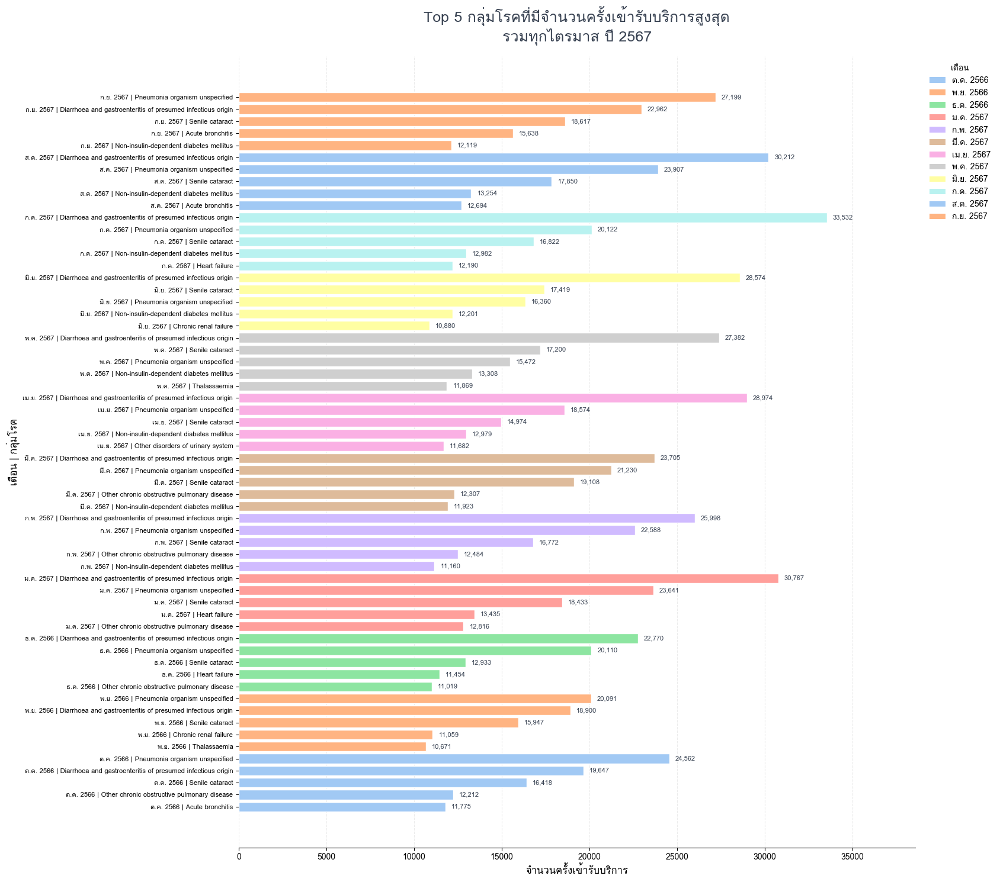

In [77]:
def plot_top5_month(df, title):
    import pandas as pd
    import matplotlib.pyplot as plt
    import seaborn as sns

    required = ["month_no", "pdx_name", "n_service"]
    missing = [c for c in required if c not in df.columns]

    if missing:
        print(f"ไม่พบคอลัมน์: {missing}")
        return

    temp = df[required].copy()

    # แปลงเดือนและจำนวนครั้งเข้ารับบริการ
    temp["date"] = pd.to_datetime(
        temp["month_no"].astype(str).str.replace(
            r"\.0$", "", regex=True
        ),
        format="%Y%m",
        errors="coerce"
    )
    temp["n_service"] = pd.to_numeric(
        temp["n_service"], errors="coerce"
    )
    temp["pdx_name"] = temp["pdx_name"].astype("string").str.strip()

    temp = temp.dropna(
        subset=["date", "pdx_name", "n_service"]
    )
    temp = temp[temp["pdx_name"] != ""]

    if temp.empty:
        print("ไม่พบข้อมูลที่ใช้สร้างกราฟ")
        return

    # สร้างคอลัมน์ period ล่วงหน้าเพื่อหลีกเลี่ยงข้อผิดพลาดเรื่องชื่อ index ใน groupby
    temp["period"] = temp["date"].dt.to_period("M")

    # รวมจำนวนบริการตามเดือนและกลุ่มโรค
    monthly = (
        temp.groupby(
            ["period", "pdx_name"],
            as_index=False
        )["n_service"].sum()
    )
    monthly["month_start"] = monthly["period"].dt.to_timestamp()

    # เลือก Top 5 โรคของแต่ละเดือน
    top5 = (
        monthly.sort_values(
            ["month_start", "n_service"],
            ascending=[True, False]
        )
        .groupby("month_start", sort=False)
        .head(5)
        .copy()
    )

    month_names = {
        1: "ม.ค.", 2: "ก.พ.", 3: "มี.ค.",
        4: "เม.ย.", 5: "พ.ค.", 6: "มิ.ย.",
        7: "ก.ค.", 8: "ส.ค.", 9: "ก.ย.",
        10: "ต.ค.", 11: "พ.ย.", 12: "ธ.ค."
    }

    top5["เดือน"] = top5["month_start"].apply(
        lambda d: f"{month_names[d.month]} {d.year + 543}"
    )

    # เรียงเดือนตามลำดับเวลา
    month_order = (
        top5[["month_start", "เดือน"]]
        .drop_duplicates()
        .sort_values("month_start")["เดือน"]
        .tolist()
    )

    # ตารางผลลัพธ์
    table = top5.sort_values(
        ["month_start", "n_service"],
        ascending=[True, False]
    ).copy()
    table["อันดับ"] = table.groupby("month_start").cumcount() + 1

    print(f"\n🌸 {title} — Top 5 กลุ่มโรคของแต่ละเดือน")
    display(
        table[["เดือน", "อันดับ", "pdx_name", "n_service"]]
        .rename(columns={
            "pdx_name": "กลุ่มโรค",
            "n_service": "จำนวนครั้งเข้ารับบริการ"
        })
        .style.hide(axis="index")
        .format({"จำนวนครั้งเข้ารับบริการ": "{:,.0f}"})
    )

    # สร้างกราฟเดียว รวมทุกเดือน
    top5["รายการ"] = top5["เดือน"] + " | " + top5["pdx_name"]

    top5 = top5.sort_values(
        ["month_start", "n_service"],
        ascending=[True, True]
    )

    fig, ax = plt.subplots(figsize=(17, 15))

    colors = sns.color_palette("pastel", n_colors=len(month_order))
    color_map = dict(zip(month_order, colors))

    bars = ax.barh(
        top5["รายการ"],
        top5["n_service"],
        color=[color_map[m] for m in top5["เดือน"]],
        edgecolor="white"
    )

    max_value = top5["n_service"].max()
    ax.set_xlim(0, max_value * 1.15)

    for bar, value in zip(bars, top5["n_service"]):
        ax.text(
            bar.get_width() + max_value * 0.01,
            bar.get_y() + bar.get_height() / 2,
            f"{value:,.0f}",
            va="center",
            fontsize=8,
            color="#374151"
        )

    ax.set_title(
        f"Top 5 กลุ่มโรคที่มีจำนวนครั้งเข้ารับบริการสูงสุด\n{title}",
        fontsize=18,
        fontweight="bold",
        color="#374151",
        pad=18
    )
    ax.set_xlabel("จำนวนครั้งเข้ารับบริการ", fontsize=12)
    ax.set_ylabel("เดือน | กลุ่มโรค", fontsize=12)
    ax.tick_params(axis="y", labelsize=8)
    ax.grid(axis="x", linestyle="--", alpha=0.25)
    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(False)

    # คำอธิบายสีของแต่ละเดือน
    from matplotlib.patches import Patch
    legend_handles = [
        Patch(facecolor=color_map[m], label=m)
        for m in month_order
    ]
    ax.legend(
        handles=legend_handles,
        title="เดือน",
        bbox_to_anchor=(1.01, 1),
        loc="upper left",
        ncol=1,
        frameon=False
    )

    plt.tight_layout()
    plt.show()


plot_top5_month(all_data, "รวมทุกไตรมาส ปี 2567")

##**จำนวนครั้งการเข้ารับบริการจำแนกตามเขตสุขภาพ**


📊 จำนวนครั้งเข้ารับบริการตามภาคและเขตสุขภาพ — รวมทุกไตรมาส ปี 2567


ภูมิภาค,เขตสุขภาพ,จำนวนครั้งเข้ารับบริการ
กรมแพทย์ทหารอากาศ,กรมแพทย์ทหาร,16
กรมแพทย์ทหารเรือ,กรมแพทย์ทหาร,817
กลาง,เขต 4 สระบุรี,"402,662"
กลาง,เขต 13 กรุงเทพมหานคร,"330,498"
กลาง,เขต 3 นครสวรรค์,"306,959"
กลาง,เขต 2 พิษณุโลก,"237,879"
กลาง,เขต 5 ราชบุรี,"225,366"
กลาง,เขต 6 ระยอง,"79,579"
ตะวันตก,เขต 5 ราชบุรี,"251,913"
ตะวันตก,เขต 2 พิษณุโลก,"57,922"


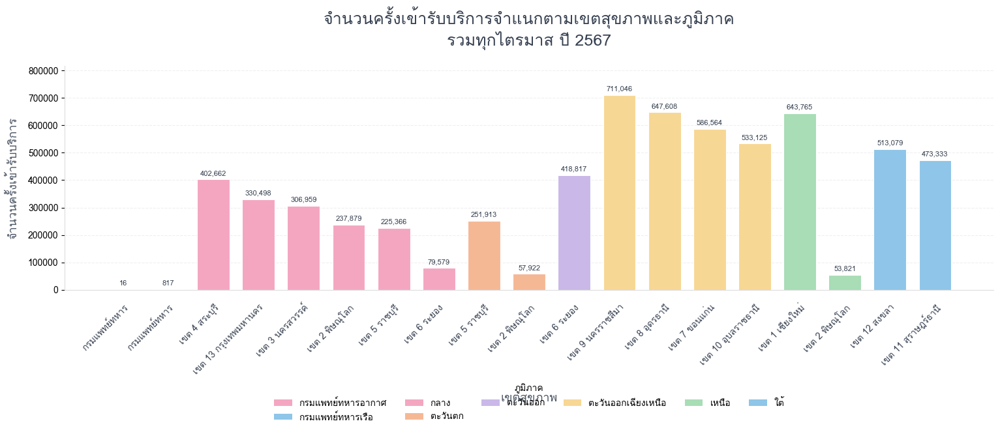


📊 จำนวนครั้งเข้ารับบริการตามภาคและเขตสุขภาพ — ไตรมาส 1 ปี 2567


ภูมิภาค,เขตสุขภาพ,จำนวนครั้งเข้ารับบริการ
กรมแพทย์ทหารอากาศ,กรมแพทย์ทหาร,4
กรมแพทย์ทหารเรือ,กรมแพทย์ทหาร,272
กลาง,เขต 4 สระบุรี,"96,034"
กลาง,เขต 13 กรุงเทพมหานคร,"78,400"
กลาง,เขต 3 นครสวรรค์,"74,943"
กลาง,เขต 2 พิษณุโลก,"56,966"
กลาง,เขต 5 ราชบุรี,"55,758"
กลาง,เขต 6 ระยอง,"18,582"
ตะวันตก,เขต 5 ราชบุรี,"62,789"
ตะวันตก,เขต 2 พิษณุโลก,"14,497"


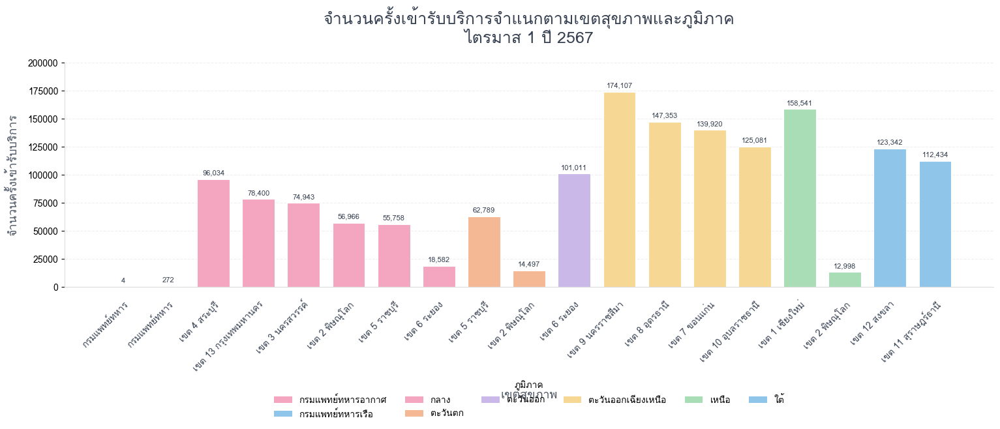


📊 จำนวนครั้งเข้ารับบริการตามภาคและเขตสุขภาพ — ไตรมาส 2 ปี 2567


ภูมิภาค,เขตสุขภาพ,จำนวนครั้งเข้ารับบริการ
กรมแพทย์ทหารอากาศ,กรมแพทย์ทหาร,3
กรมแพทย์ทหารเรือ,กรมแพทย์ทหาร,241
กลาง,เขต 4 สระบุรี,"101,227"
กลาง,เขต 13 กรุงเทพมหานคร,"84,467"
กลาง,เขต 3 นครสวรรค์,"77,771"
กลาง,เขต 2 พิษณุโลก,"57,865"
กลาง,เขต 5 ราชบุรี,"56,214"
กลาง,เขต 6 ระยอง,"20,481"
ตะวันตก,เขต 5 ราชบุรี,"62,254"
ตะวันตก,เขต 2 พิษณุโลก,"14,040"


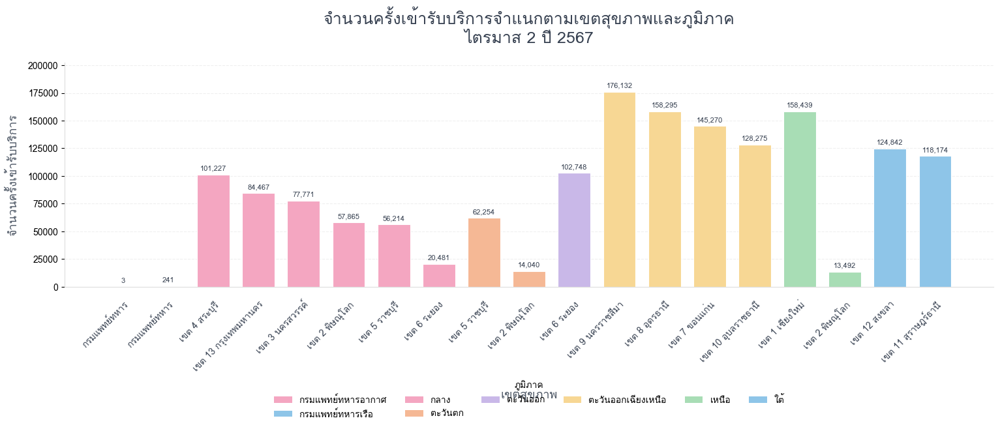


📊 จำนวนครั้งเข้ารับบริการตามภาคและเขตสุขภาพ — ไตรมาส 3 ปี 2567


ภูมิภาค,เขตสุขภาพ,จำนวนครั้งเข้ารับบริการ
กรมแพทย์ทหารอากาศ,กรมแพทย์ทหาร,3
กรมแพทย์ทหารเรือ,กรมแพทย์ทหาร,121
กลาง,เขต 4 สระบุรี,"97,118"
กลาง,เขต 13 กรุงเทพมหานคร,"80,760"
กลาง,เขต 3 นครสวรรค์,"73,315"
กลาง,เขต 2 พิษณุโลก,"58,359"
กลาง,เขต 5 ราชบุรี,"53,145"
กลาง,เขต 6 ระยอง,"18,661"
ตะวันตก,เขต 5 ราชบุรี,"59,701"
ตะวันตก,เขต 2 พิษณุโลก,"14,190"


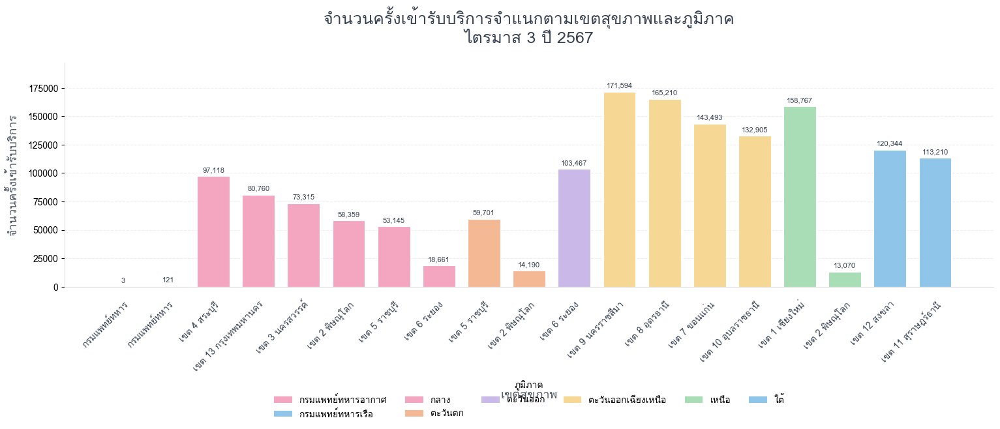


📊 จำนวนครั้งเข้ารับบริการตามภาคและเขตสุขภาพ — ไตรมาส 4 ปี 2567


ภูมิภาค,เขตสุขภาพ,จำนวนครั้งเข้ารับบริการ
กรมแพทย์ทหารอากาศ,กรมแพทย์ทหาร,6
กรมแพทย์ทหารเรือ,กรมแพทย์ทหาร,183
กลาง,เขต 4 สระบุรี,"108,283"
กลาง,เขต 13 กรุงเทพมหานคร,"86,871"
กลาง,เขต 3 นครสวรรค์,"80,930"
กลาง,เขต 2 พิษณุโลก,"64,689"
กลาง,เขต 5 ราชบุรี,"60,249"
กลาง,เขต 6 ระยอง,"21,855"
ตะวันตก,เขต 5 ราชบุรี,"67,169"
ตะวันตก,เขต 2 พิษณุโลก,"15,195"


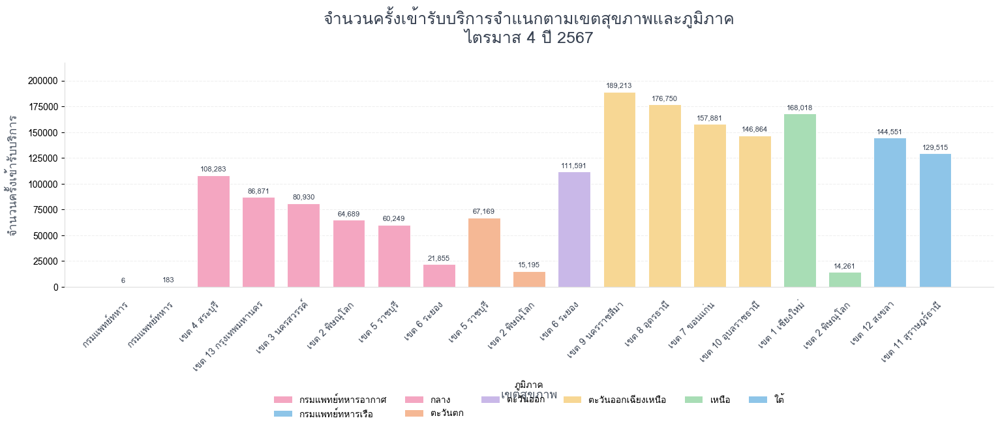

In [83]:

import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
from IPython.display import display

# ============================================================
# 1) ตั้งค่ากราฟ
# ============================================================

mpl.rcParams["font.family"] = "Loma"
mpl.rcParams["axes.unicode_minus"] = False

region_colors = {
    "เหนือ": "#A8DDB5",
    "กลาง": "#F4A6C1",
    "ตะวันออกเฉียงเหนือ": "#F7D794",
    "ตะวันออก": "#C9B8E8",
    "ตะวันตก": "#F5B895",
    "ใต้": "#8EC5E8"
}

fallback_colors = [
    "#F4A6C1", "#8EC5E8", "#C9B8E8",
    "#A8DDB5", "#F7D794", "#F5B895"
]

# ============================================================
# 2) เตรียมข้อมูลทั้ง 4 ไตรมาส
# รองรับ Dictionary ของ DataFrame หรือ DataFrame เดียว
# ============================================================

source_data = cleaned_data if "cleaned_data" in globals() else data
quarter_data = {}

if isinstance(source_data, pd.DataFrame):

    if "month_no" not in source_data.columns:
        raise ValueError("ไม่พบคอลัมน์ month_no สำหรับแบ่งไตรมาส")

    dates = pd.to_datetime(
        source_data["month_no"].astype(str).str.replace(
            r"\.0$", "", regex=True
        ),
        format="%Y%m",
        errors="coerce"
    )

    for q in range(1, 5):
        mask = dates.dt.quarter == q

        if mask.any():
            quarter_data[f"ไตรมาส {q}"] = source_data.loc[mask].copy()

else:

    for key, df in source_data.items():

        if isinstance(key, int):
            quarter_data[f"ไตรมาส {key}"] = df.copy()

        else:
            name = os.path.basename(str(key)).lower()

            for q in range(1, 5):
                if f"67q{q}" in name:
                    quarter_data[f"ไตรมาส {q}"] = df.copy()
                    break

if not quarter_data:
    raise ValueError(
        "ไม่พบข้อมูลไตรมาส 1–4 กรุณาตรวจสอบคีย์ข้อมูลในตัวแปรที่ระบุ"
    )

all_data = pd.concat(
    quarter_data.values(),
    ignore_index=True
)

# ============================================================
# 3) ฟังก์ชันสรุปจำนวนบริการตามภาคและเขตสุขภาพ
# ============================================================

def plot_region_zone(df, title):

    required = ["ภาค", "nhso_zonename", "n_service"]
    missing = [col for col in required if col not in df.columns]

    if missing:
        print(f"ข้าม {title}: ไม่พบคอลัมน์ {missing}")
        return

    temp = df[required].copy()

    temp["n_service"] = pd.to_numeric(
        temp["n_service"], errors="coerce"
    )

    temp["ภาค"] = temp["ภาค"].astype("string").str.strip()

    temp["nhso_zonename"] = (
        temp["nhso_zonename"].astype("string").str.strip()
    )

    temp = temp.dropna(subset=required)

    temp = temp[
        (temp["ภาค"] != "") &
        (temp["nhso_zonename"] != "")
    ]

    # รวมจำนวนบริการตามภาคและเขตสุขภาพ
    region_zone = (
        temp.groupby(
            ["ภาค", "nhso_zonename"],
            as_index=False
        )["n_service"].sum()
    )

    if region_zone.empty:
        print(f"ไม่มีข้อมูลสำหรับ {title}")
        return

    # เรียงตามภาคและจำนวนบริการ
    region_zone = region_zone.sort_values(
        ["ภาค", "n_service"],
        ascending=[True, False]
    ).reset_index(drop=True)

    # --------------------------------------------------------
    # ตารางสรุป
    # --------------------------------------------------------

    table = region_zone.copy()

    table.columns = [
        "ภูมิภาค",
        "เขตสุขภาพ",
        "จำนวนครั้งเข้ารับบริการ"
    ]

    print(
        f"\n📊 จำนวนครั้งเข้ารับบริการตามภาคและเขตสุขภาพ — {title}"
    )

    display(
        table.style
        .hide(axis="index")
        .format({
            "จำนวนครั้งเข้ารับบริการ": "{:,.0f}"
        })
        .set_properties(**{
            "text-align": "center",
            "padding": "8px",
            "border": "1px solid #E5E7EB"
        })
        .set_table_styles([
            {
                "selector": "th",
                "props": [
                    ("background-color", "#F3DDE6"),
                    ("color", "#374151"),
                    ("font-weight", "bold"),
                    ("text-align", "center")
                ]
            },
            {
                "selector": "tbody tr:nth-child(even)",
                "props": [
                    ("background-color", "#FFF8FA")
                ]
            }
        ])
    )

    # --------------------------------------------------------
    # กำหนดสีแท่งกราฟตามภาค
    # --------------------------------------------------------

    colors = []

    for i, region in enumerate(region_zone["ภาค"]):

        color = region_colors.get(region)

        if color is None:
            color = fallback_colors[i % len(fallback_colors)]

        colors.append(color)

    # --------------------------------------------------------
    # สร้างกราฟ
    # --------------------------------------------------------

    fig, ax = plt.subplots(figsize=(16, 8))

    bars = ax.bar(
        range(len(region_zone)),
        region_zone["n_service"],
        color=colors,
        width=0.72,
        edgecolor="white",
        linewidth=0.8
    )

    ax.set_title(
        f"จำนวนครั้งเข้ารับบริการจำแนกตามเขตสุขภาพและภูมิภาค\n{title}",
        fontsize=18,
        fontweight="bold",
        color="#374151",
        pad=22
    )

    ax.set_xlabel(
        "เขตสุขภาพ",
        fontsize=13,
        fontweight="bold",
        color="#4B5563",
        labelpad=18
    )

    ax.set_ylabel(
        "จำนวนครั้งเข้ารับบริการ",
        fontsize=13,
        fontweight="bold",
        color="#4B5563",
        labelpad=10
    )

    # ชื่อเขตสุขภาพบนแกน X
    ax.set_xticks(range(len(region_zone)))

    ax.set_xticklabels(
        region_zone["nhso_zonename"],
        rotation=45,
        ha="right",
        rotation_mode="anchor",
        fontsize=10,
        color="#374151"
    )

    # เลื่อนชื่อเขตสุขภาพลงจากแกน X
    ax.tick_params(
        axis="x",
        pad=14,
        length=0
    )

    # ตัวเลขบนแท่งกราฟ
    max_value = region_zone["n_service"].max()

    for bar, value in zip(bars, region_zone["n_service"]):

        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + max_value * 0.015,
            f"{value:,.0f}",
            ha="center",
            va="bottom",
            fontsize=8,
            color="#374151",
            fontweight="bold"
        )

    # เส้นกริดและขอบกราฟ
    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.2
    )

    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#DDDDDD")
    ax.spines["bottom"].set_color("#DDDDDD")

    ax.set_ylim(
        0,
        max_value * 1.15 if max_value > 0 else 1
    )

    # --------------------------------------------------------
    # คำอธิบายสีตามภูมิภาค
    # --------------------------------------------------------

    present_regions = region_zone["ภาค"].drop_duplicates().tolist()

    from matplotlib.patches import Patch

    legend_handles = [
        Patch(
            facecolor=region_colors.get(
                region,
                fallback_colors[i % len(fallback_colors)]
            ),
            label=region
        )
        for i, region in enumerate(present_regions)
    ]

    ax.legend(
        handles=legend_handles,
        title="ภูมิภาค",
        frameon=False,
        loc="upper center",
        bbox_to_anchor=(0.5, -0.38),
        ncol=min(6, len(present_regions))
    )

    # เพิ่มพื้นที่ด้านล่าง ป้องกันชื่อเขตสุขภาพ
    # และคำอธิบายสีทับกัน
    fig.subplots_adjust(
        left=0.08,
        right=0.97,
        top=0.86,
        bottom=0.43
    )

    plt.show()


# ============================================================
# 4) รวมทั้งปี 2567
# ============================================================

plot_region_zone(
    all_data,
    "รวมทุกไตรมาส ปี 2567"
)

# ============================================================
# 5) แยกไตรมาส 1–4
# ============================================================

for quarter in sorted(
    quarter_data.keys(),
    key=lambda x: int(x.split()[-1])
):
    plot_region_zone(
        quarter_data[quarter],
        f"{quarter} ปี 2567"
    )


##**จำนวนครั้งเข้ารับบริการจำแนกตามโรค เพศ และภูมิภาค**

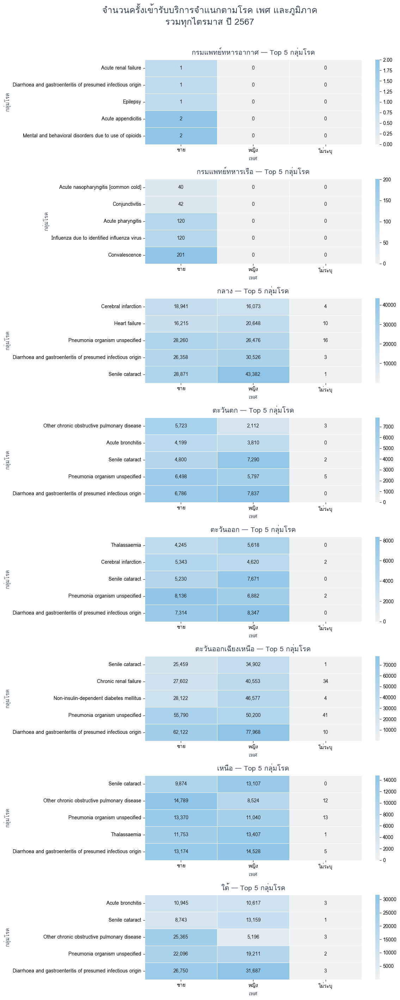

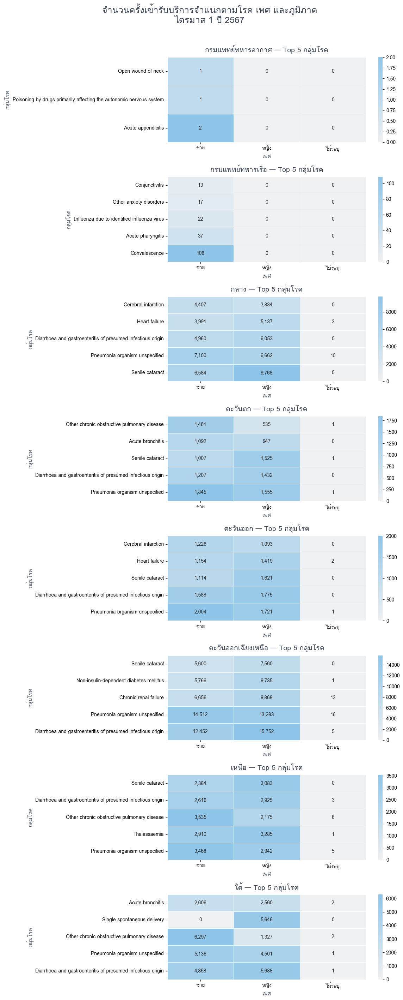

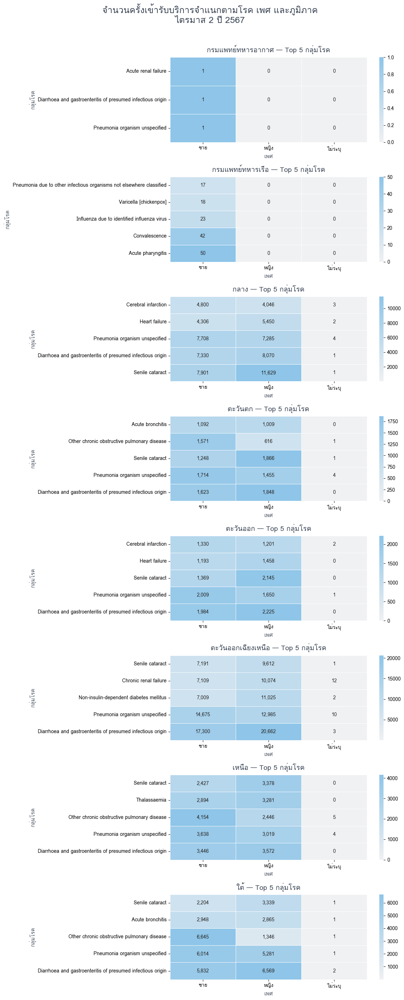

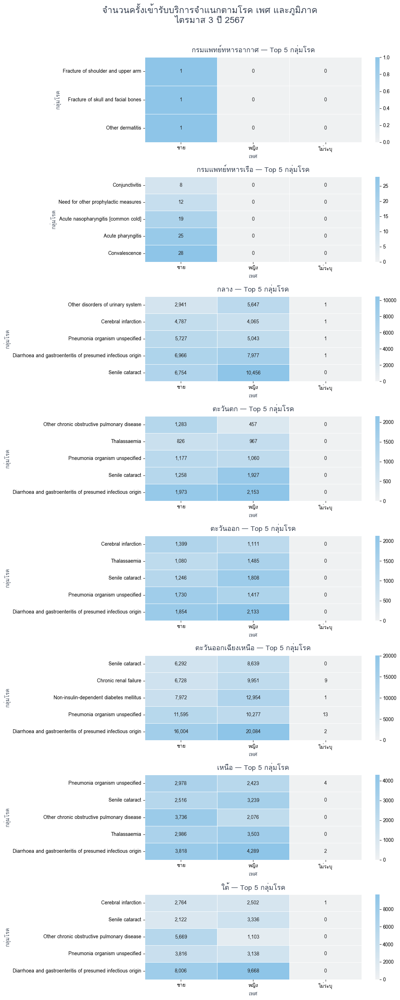

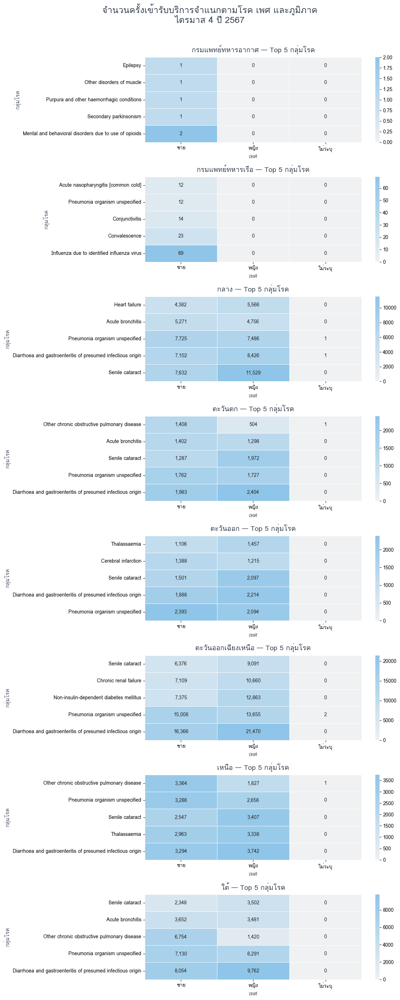

In [79]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns

# ============================================================
# 1) ตั้งค่าฟอนต์และรูปแบบกราฟ
# ============================================================

mpl.rcParams["font.family"] = "Loma"
mpl.rcParams["axes.unicode_minus"] = False

gender_order = ["ชาย", "หญิง", "ไม่ระบุ"]
cmap = sns.light_palette("#8EC5E8", as_cmap=True)

# ============================================================
# 2) เตรียมข้อมูลทั้ง 4 ไตรมาส
# รองรับทั้ง Dictionary และ DataFrame
# ============================================================

source_data = cleaned_data if "cleaned_data" in globals() else data
quarter_data = {}

is_df = isinstance(source_data, pd.DataFrame)

if is_df:
    if "month_no" not in source_data.columns:
        raise ValueError("ไม่พบคอลัมน์ month_no สำหรับแบ่งไตรมาส")

    dates = pd.to_datetime(
        source_data["month_no"].astype(str),
        format="%Y%m",
        errors="coerce"
    )

    for q in range(1, 5):
        mask = dates.dt.quarter == q
        if mask.any():
            quarter_data[f"ไตรมาส {q}"] = source_data.loc[mask].copy()

else:
    for key, df in source_data.items():
        if isinstance(key, int):
            quarter_data[f"ไตรมาส {key}"] = df.copy()
        else:
            name = os.path.basename(str(key)).lower()
            for q in range(1, 5):
                if f"67q{q}" in name:
                    quarter_data[f"ไตรมาส {q}"] = df.copy()
                    break

if not quarter_data:
    raise ValueError(
        "ไม่พบข้อมูลรายไตรมาส กรุณาตรวจสอบไฟล์ 67q1, 67q2, 67q3 และ 67q4"
    )

all_data = pd.concat(quarter_data.values(), ignore_index=True)

# ============================================================
# 3) ฟังก์ชันสร้าง Heatmap
# ============================================================

def plot_disease_gender_heatmap(df, title):

    required = ["ภาค", "pdx_name", "gender", "n_service"]
    missing = [col for col in required if col not in df.columns]

    if missing:
        print(f"ข้าม {title}: ไม่พบคอลัมน์ {missing}")
        return

    temp = df[required].copy()

    # แปลงรหัสเพศ
    temp["gender"] = pd.to_numeric(temp["gender"], errors="coerce")

    temp["gender_label"] = temp["gender"].map({
        1: "ชาย",
        2: "หญิง"
    }).fillna("ไม่ระบุ")

    temp["n_service"] = pd.to_numeric(
        temp["n_service"], errors="coerce"
    )

    temp["ภาค"] = temp["ภาค"].astype("string").str.strip()
    temp["pdx_name"] = temp["pdx_name"].astype("string").str.strip()

    temp = temp.dropna(
        subset=["ภาค", "pdx_name", "n_service"]
    )

    temp = temp[
        (temp["ภาค"] != "") &
        (temp["pdx_name"] != "")
    ]

    if temp.empty:
        print(f"ไม่มีข้อมูลสำหรับ {title}")
        return

    # รวมจำนวนบริการตามภาค โรค และเพศ
    region_disease_gender = (
        temp.groupby(
            ["ภาค", "pdx_name", "gender_label"],
            as_index=False
        )["n_service"].sum()
    )

    # หา Top 5 โรคของแต่ละภาค โดยรวมทุกเพศ
    top5_region = (
        region_disease_gender
        .groupby(["ภาค", "pdx_name"], as_index=False)["n_service"]
        .sum()
        .sort_values(
            ["ภาค", "n_service"],
            ascending=[True, False]
        )
        .groupby("ภาค", sort=False)
        .head(5)
    )

    # เลือกเฉพาะ Top 5 ของแต่ละภาค
    plot_data = region_disease_gender.merge(
        top5_region[["ภาค", "pdx_name"]],
        on=["ภาค", "pdx_name"],
        how="inner"
    )

    regions = sorted(plot_data["ภาค"].unique())

    if not regions:
        print(f"ไม่มีข้อมูลสำหรับสร้าง Heatmap: {title}")
        return

    # สร้างกราฟแยกตามภูมิภาค
    fig, axes = plt.subplots(
        nrows=len(regions),
        ncols=1,
        figsize=(12, 3.5 * len(regions)),
        squeeze=False
    )

    axes = axes.flatten()

    for ax, region in zip(axes, regions):

        region_temp = plot_data[
            plot_data["ภาค"] == region
        ]

        pivot = region_temp.pivot_table(
            index="pdx_name",
            columns="gender_label",
            values="n_service",
            aggfunc="sum",
            fill_value=0
        )

        # กำหนดลำดับเพศให้เหมือนกันทุกกราฟ
        pivot = pivot.reindex(
            columns=gender_order,
            fill_value=0
        )

        # เรียงโรคจากจำนวนบริการรวมน้อยไปมาก
        pivot["รวม"] = pivot.sum(axis=1)
        pivot = pivot.sort_values("รวม", ascending=True)
        pivot = pivot.drop(columns="รวม")

        sns.heatmap(
            pivot,
            annot=True,
            fmt=",.0f",
            cmap=cmap,
            linewidths=0.7,
            linecolor="white",
            cbar=True,
            ax=ax,
            annot_kws={"fontsize": 10}
        )

        ax.set_title(
            f"{region} — Top 5 กลุ่มโรค",
            fontsize=14,
            fontweight="bold",
            color="#374151",
            pad=10
        )

        ax.set_xlabel(
            "เพศ",
            fontsize=11,
            fontweight="bold",
            color="#4B5563"
        )

        ax.set_ylabel(
            "กลุ่มโรค",
            fontsize=11,
            fontweight="bold",
            color="#4B5563"
        )

        ax.tick_params(axis="x", labelrotation=0, labelsize=10)
        ax.tick_params(axis="y", labelrotation=0, labelsize=10)

    fig.suptitle(
        f"จำนวนครั้งเข้ารับบริการจำแนกตามโรค เพศ และภูมิภาค\n{title}",
        fontsize=18,
        fontweight="bold",
        color="#374151",
        y=1.01
    )

    plt.tight_layout()
    plt.show()


# ============================================================
# 4) แสดงผลรวมทั้งปี 2567
# ============================================================

plot_disease_gender_heatmap(
    all_data,
    "รวมทุกไตรมาส ปี 2567"
)

# ============================================================
# 5) แสดงผลแยกไตรมาส 1–4
# ============================================================

for quarter in sorted(
    quarter_data.keys(),
    key=lambda x: int(x.split()[-1])
):
    plot_disease_gender_heatmap(
        quarter_data[quarter],
        f"{quarter} ปี 2567"
    )
